# 04 · Duplicates

For anyone checking how Open Altio flags duplicate cases. It measures the AEOLUS rule and the alternatives, and ends with **The seven choices** it backs, each with its numbers on this release and the code that applies it. The rules themselves are in `rules/dedup-default.md`, `rules/dup-manufacturer-number.md`, `rules/dup-padded-event-dates.md`, `rules/dup-shown-copy.md` and `rules/no-drug-or-reaction.md`.

A duplicate is one patient's event sent to FDA as two or more cases: by two companies, by a company and the patient, or by one company under two case numbers. FDA merges follow-ups of a case under one case number; it does not merge separate cases. Every rule here flags cases; nothing is deleted.

Grain: `case_latest_T`, the latest version of each case across AERS and FAERS, with FDA's deleted cases removed. The notebook reads a release folder (`RELEASE` in the first code cell, or the setting `OPEN_ALTIO_RELEASE`). The numbers in the text are from a release with every choice on, as `open-altio build` makes it: its flags are Open Altio's tag, with the latest received copy shown. The check in section 1 keeps the earliest received copy and the AEOLUS rule alone, so it counts the flags that differ from such a release; it is zero on a release built with the choices of this notebook switched off. To build one, run `open-altio build` in a folder holding this `rules.toml`:

```toml
[dup-manufacturer-number]
on = false
[dup-padded-event-dates]
on = false
[dup-shown-copy]
shown_copy = "earliest_received"
```

No release yet? Build one with `open-altio demo` or `open-altio build`. The notebook computes Open Altio's duplicate tag itself, apart from the release code, so the two can check each other. The release is built from every quarter FDA published, 2004Q1 to 2026Q2.

Words used below:
- **version**: one submission FDA receives. **case**: one case number, its latest version only.
- **group**: cases one rule says are one patient's event.
- **shown copy**: the one case of a group the explorer shows by default; the latest received (choice 3). **Set aside**: the others, flagged and kept.
- **never compared**: a case a rule cannot test, because a field it needs is empty.

Sections: what a version, a case and a group are; 1 the AEOLUS rule and its gap; 2 the alternatives and how they overlap; 3 which copy is shown; 4 do the cases inside a group agree, then examples; 5 facts for a later probability study; the seven choices.

In [1]:
import hashlib
import time

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch

from open_altio import rulebook
from open_altio.faers.insights.cards.notebook import (
    SERIES,
    header,
    label_bars,
    mark_years,
    out_dir,
    setup,
    title,
)
from open_altio.faers.insights.source import connect, release_folder

setup(colwidth=80)
GREEN, ORANGE, GREY, BLUE = SERIES[2], SERIES[1], SERIES[7], SERIES[0]
INK, MUTED = "#1a1a19", "#5a5a56"
# The release this notebook reads, built as the introduction says; None reads $OPEN_ALTIO_RELEASE.
# No release yet? Build one with `open-altio demo` or `open-altio build`.
RELEASE = None
SOURCE = release_folder(RELEASE)
con = connect(SOURCE)  # read-only views over the release's Parquet
# another build of the same quarter gets its own working tables
BUILD_ID = hashlib.md5((SOURCE / "manifest.json").read_bytes()).hexdigest()[:8]
WORK = out_dir() / "04_duplicates" / f"{SOURCE.name}-{BUILD_ID}.duckdb"
WORK.parent.mkdir(parents=True, exist_ok=True)
# other DuckDB jobs share the machine
con.execute(
    "SET memory_limit = '6GB'; SET threads = 4; SET max_temp_directory_size = '20GB'; "
    f"SET preserve_insertion_order = false; SET temp_directory = '{WORK.parent / 'tmp'}'"
)
con.execute(f"ATTACH '{WORK}' AS w")


def q(sql):
    return con.execute(sql).fetchdf()


print("source:", SOURCE, "\nworking tables:", WORK)

# The shown copy of a group (choice 3, rules/dup-shown-copy.md): the latest received. One order
# for every rule.
LATEST = "first_fda_dt_T DESC NULLS LAST, caseid DESC NULLS LAST, era_T, case_key_T DESC"
# The order of the release this notebook reads: the earliest received is kept.
EARLIEST = "first_fda_dt_T ASC NULLS LAST, caseid ASC NULLS LAST, era_T, case_key_T"


def grid(df, heading, ax, fmt="{:.0f}", vmax=100, cmap="Blues"):
    """An annotated single-hue heatmap: rows and columns as in df."""
    v = df.values.astype(float)
    ax.imshow(v, aspect="auto", cmap=cmap, vmin=0, vmax=vmax)
    ax.set_xticks(range(df.shape[1]))
    ax.set_xticklabels(df.columns, rotation=90, fontsize=8)
    ax.set_yticks(range(df.shape[0]))
    ax.set_yticklabels(df.index, fontsize=9)
    ax.grid(False)
    ax.set_title(heading, loc="left")
    for (i, j), x in np.ndenumerate(v):
        if not np.isnan(x):
            color = "white" if x > 0.6 * vmax else INK
            ax.text(j, i, fmt.format(x), ha="center", va="center", fontsize=7, color=color)


# The rule file behind each of the seven choices, for the line under a chart that backs one.
CHOICES = {
    1: "rules/dup-manufacturer-number.md",
    2: "rules/dedup-default.md",
    3: "rules/dup-shown-copy.md",
    4: "rules/dup-shown-copy.md",
    5: "rules/reaction-term-case.md",
    6: "rules/no-drug-or-reaction.md",
    7: "rules/dup-padded-event-dates.md",
}


def rule_line(backs):
    """'Backs choice 1: rules/...' for one choice or several; None for none."""
    backs = (backs,) if isinstance(backs, int) else tuple(backs or ())
    if not backs:
        return None
    files = ", ".join(dict.fromkeys(CHOICES[b] for b in backs))
    return f"Backs choice{'s' if len(backs) > 1 else ''} {' and '.join(map(str, backs))}: {files}"

source: releases/2026Q2-oap-final3-local 
working tables: notebooks/out/04_duplicates/2026Q2-oap-final3-local-140a5c16.duckdb


The notebook first builds its working tables, once, into a scratch DuckDB beside the executed notebook (about ten minutes; later runs reuse them). How they are built is explained after the first chart.

In [2]:
# Words DiAna's dictionary maps to "no medication" or "unspecified", and PTs that say nothing happened,
# as rules/no-drug-or-reaction.md lists them. DiAna works on mapped substances; we have only
# normalised drug names, so the drug list is a stand-in.
NO_DRUG = rulebook.value("no-drug-or-reaction", "unusable_drug_names")
NO_EVENT = rulebook.value("no-drug-or-reaction", "no_event_terms")
SERIOUS = {
    "DE": "death",
    "LT": "life-threatening",
    "HO": "hospitalised",
    "DS": "disability",
    "CA": "congenital anomaly",
    "RI": "needed intervention",
    "OT": "other serious",
}


def sql_list(xs):
    return ", ".join("'" + x.replace("'", "''") + "'" for x in xs)


def md5key(*cols):
    """A group's id: the MD5 of its key fields written out. An empty field is written as a control
    character, so it matches only another empty field. (DuckDB's hash() collides on similar strings:
    8,326 false merges among manufacturer numbers in 2026Q2. MD5 has none.)"""
    return (
        "md5_number(concat_ws(chr(31), "
        + ", ".join(f"coalesce(CAST({c} AS VARCHAR), chr(30))" for c in cols)
        + "))"
    )


def strict_key(*cols):
    """The key only when every field is filled; otherwise NULL, which never matches anything."""
    return f"CASE WHEN {' AND '.join(f'{c} IS NOT NULL' for c in cols)} THEN {md5key(*cols)} END"


def measure(cols, where="TRUE", table="w.case_w_T", strict=True):
    """Groups, cases in groups, cases set aside (all but one per group) and the largest group, grouping on cols.
    strict: every field must be filled, so an empty field never matches; otherwise empty matches empty (SQL GROUP BY)."""
    if strict:
        where = " AND ".join([where] + [f"{c} IS NOT NULL" for c in cols])
    return q(f"""WITH s AS (SELECT count(*) AS n FROM {table} WHERE {where} GROUP BY {", ".join(cols)} HAVING count(*) > 1)
                 SELECT count(*) AS groups, coalesce(sum(n), 0) AS in_groups, coalesce(sum(n) - count(*), 0) AS set_aside,
                        coalesce(max(n), 0) AS largest FROM s""").iloc[0]


RB_FIELDS = (
    "event_dt_diana_T",
    "sex_mf_T",
    "rep_country_diana_T",
    "age_days_T",
    "wt_kg_diana_T",
    "pts_up_h_T",
    "ps_h_T",
    "ss_h_T",
    "ic_h_T",
)

LAST_Q = con.execute("SELECT max(quarter_T) FROM quarters_T").fetchone()[0]
LAST_DAY = (
    LAST_Q[:4] + {"1": "0331", "2": "0630", "3": "0930", "4": "1231"}[LAST_Q[-1]]
)  # DiAna: no date after the release
AGE_DAYS = (
    "CASE coalesce(upper(c.age_cod), 'YR') WHEN 'DEC' THEN 3650 WHEN 'YR' THEN 365 WHEN 'MON' THEN 30.4375 WHEN 'WK' THEN 7 "
    "WHEN 'DY' THEN 1 WHEN 'HR' THEN 1/24 WHEN 'MIN' THEN 1/1440 WHEN 'SEC' THEN 1/86400 END"
)
WT_KG = (
    "CASE WHEN upper(c.wt_cod) IN ('LBS', 'IB') THEN 0.453592 WHEN upper(c.wt_cod) IN ('KG', 'KGS') THEN 1 "
    "WHEN upper(c.wt_cod) = 'GMS' THEN 0.001 WHEN upper(c.wt_cod) = 'MG' THEN 1e-6 WHEN c.wt_cod IS NULL THEN 1 END"
)

BUILD = [
    "CREATE OR REPLACE TABLE w.drug_sets_T (era_T VARCHAR, primaryid VARCHAR, quarter_T VARCHAR, drugs_h_T UHUGEINT, ps_h_T UHUGEINT, ss_h_T UHUGEINT, ic_h_T UHUGEINT, n_drugs_T BIGINT, n_real_drugs_T BIGINT)",
    "CREATE OR REPLACE TABLE w.reac_sets_T (era_T VARCHAR, primaryid VARCHAR, quarter_T VARCHAR, pts_h_T UHUGEINT, pts_up_h_T UHUGEINT, n_pts_T BIGINT, n_real_pts_T BIGINT)",
]
# A set's fingerprint: the XOR of the MD5s of its distinct values. Built a quarter at a time to stay near
# 3 GB (the reason derive.DUP_SETS works by quarter too).
FILL = [
    f"""INSERT INTO w.drug_sets_T SELECT era_T, primaryid, quarter_T,
  bit_xor(DISTINCT md5_number(drugname_norm_T)),
  bit_xor(DISTINCT md5_number(drugname_norm_T)) FILTER (WHERE role_cod = 'PS'),
  bit_xor(DISTINCT md5_number(drugname_norm_T)) FILTER (WHERE role_cod = 'SS'),
  bit_xor(DISTINCT md5_number(drugname_norm_T)) FILTER (WHERE role_cod IN ('I', 'C')),
  count(DISTINCT drugname_norm_T),
  count(DISTINCT drugname_norm_T) FILTER (WHERE drugname_norm_T NOT IN ({sql_list(NO_DRUG)}))
FROM drug_latest_T WHERE drugname_norm_T IS NOT NULL AND quarter_T = $quarter GROUP BY ALL""",
    f"""INSERT INTO w.reac_sets_T SELECT era_T, primaryid, quarter_T,
  bit_xor(DISTINCT md5_number(pt)), bit_xor(DISTINCT md5_number(upper(pt))),
  count(DISTINCT upper(pt)),
  count(DISTINCT upper(pt)) FILTER (WHERE upper(pt) NOT IN ({sql_list(NO_EVENT)}))
FROM reac_latest_T WHERE pt IS NOT NULL AND quarter_T = $quarter GROUP BY ALL""",
]
# One row per case of the analysis grain, with what every rule needs. sex is F or M, else empty: any other code FDA uses (NS, UNK) is not a sex, so the AEOLUS rule never compares it (rules/sex-codes.md). country_fix_T is the release's country_T
# (a legacy name read as its ISO code), or the EU code where only an earlier version named the member state, as the release keys it; country_raw_T is FDA's text, as compared before notebook 02's fix. Legacy AERS has no
# occurrence country, so a legacy case's reporter country is its country_T. num_up_T and sndr_up_T are the
# manufacturer number and sender as the number rule compares them: trimmed, in capitals.
EU = rulebook.value("eu-member-state", "code")
CASES = f"""CREATE OR REPLACE TABLE w.case_w_T AS
WITH b AS (
  SELECT c.era_T, c.case_key_T, c.caseid, c.primaryid, c.quarter_T, c.caseversion_T, c.fda_dt, c.first_fda_dt_T, c.init_year_T,
    c.event_dt, c.age, c.age_cod, c.age_years_T, CASE WHEN upper(trim(c.sex)) IN ('F', 'M') THEN upper(trim(c.sex)) END AS sex, c.wt, c.wt_cod, c.occr_country, c.reporter_country, c.mfr_num, c.mfr_sndr,
    nullif(upper(trim(c.mfr_num)), '') AS num_up_T, nullif(upper(trim(c.mfr_sndr)), '') AS sndr_up_T,
    c.rept_cod, c.occp_cod, c.lit_ref, c.probable_duplicate_T AS released_dup_T, c.dup_kept_T AS released_kept_T,
    CASE WHEN c.rept_cod IN ('EXP', '30DAY', '5DAY') THEN 'manufacturer, expedited' WHEN c.rept_cod = 'PER' THEN 'manufacturer, periodic'
         WHEN c.rept_cod = 'DIR' THEN 'direct to FDA' ELSE 'other or empty' END AS sender_type_T,
    coalesce(c.occr_country, c.reporter_country) AS country_raw_T, CASE WHEN c.country_source_T = 'earlier version' THEN '{EU}' ELSE c.country_T END AS country_fix_T,
    CASE WHEN c.era_T = 'legacy' THEN c.country_T ELSE c.reporter_country END AS reporter_country_fix_T,
    d.drugs_h_T, d.ps_h_T, d.ss_h_T, d.ic_h_T, coalesce(d.n_drugs_T, 0) AS n_drugs_T, coalesce(d.n_real_drugs_T, 0) AS n_real_drugs_T,
    r.pts_h_T, r.pts_up_h_T, coalesce(r.n_pts_T, 0) AS n_pts_T, coalesce(r.n_real_pts_T, 0) AS n_real_pts_T,
    CASE WHEN length(c.event_dt) = 4 AND c.event_dt BETWEEN '1985' AND '{LAST_DAY[:4]}' THEN c.event_dt
         WHEN length(c.event_dt) = 6 AND c.event_dt BETWEEN '198500' AND '{LAST_DAY[:6]}' THEN c.event_dt
         WHEN length(c.event_dt) = 8 AND c.event_dt BETWEEN '19850000' AND '{LAST_DAY}' THEN c.event_dt END AS event_dt_diana_T,
    CASE WHEN upper(trim(c.sex)) IN ('F', 'M') THEN upper(trim(c.sex)) END AS sex_mf_T,
    round(abs(try_cast(c.age AS DOUBLE)) * {AGE_DAYS}) AS age_days_any,
    round(abs(try_cast(c.wt AS DOUBLE)) * {WT_KG}) AS wt_kg_any
  FROM case_latest_T c
  LEFT JOIN w.drug_sets_T d USING (era_T, primaryid, quarter_T)
  LEFT JOIN w.reac_sets_T r USING (era_T, primaryid, quarter_T))
SELECT * EXCLUDE (age_days_any, wt_kg_any),
  CASE WHEN reporter_country_fix_T NOT IN ('COUNTRY NOT SPECIFIED', 'A1') THEN reporter_country_fix_T END AS rep_country_diana_T,
  CASE WHEN age_days_any <= 122 * 365 THEN age_days_any END AS age_days_T,
  CASE WHEN wt_kg_any <= 635 THEN wt_kg_any END AS wt_kg_diana_T
FROM b"""

# AEOLUS single imputation: a case missing exactly one of event date, age, sex, country takes it from another
# version of the same caseid (either era) that has all four and agrees on the other three; the highest value wins.
IMPUTE = """CREATE OR REPLACE TABLE w.impute_T AS
WITH v AS (
  SELECT DISTINCT d.caseid, d.event_dt, d.age, d.age_cod, upper(trim(d.sex)) AS sex, d.country_T AS country
  FROM demo_T d
  WHERE d.caseid IS NOT NULL AND d.event_dt IS NOT NULL AND d.age IS NOT NULL AND d.age_cod IS NOT NULL AND upper(trim(d.sex)) IN ('F', 'M')
    AND d.country_T IS NOT NULL),
c AS (
  SELECT era_T, case_key_T, caseid, event_dt, age, age_cod, sex, country_fix_T AS country FROM w.case_w_T
  WHERE caseid IS NOT NULL
    AND (event_dt IS NULL)::INT + (age IS NULL OR age_cod IS NULL)::INT + (sex IS NULL)::INT + (country_fix_T IS NULL)::INT = 1)
SELECT c.era_T, c.case_key_T,
  max(v.event_dt) FILTER (WHERE c.event_dt IS NULL AND v.age = c.age AND v.age_cod = c.age_cod AND v.sex = c.sex AND v.country = c.country) AS event_dt_imp_T,
  max({'age': v.age, 'age_cod': v.age_cod}) FILTER (WHERE (c.age IS NULL OR c.age_cod IS NULL) AND v.event_dt = c.event_dt AND v.sex = c.sex AND v.country = c.country) AS age_imp_T,
  max(v.sex) FILTER (WHERE c.sex IS NULL AND v.event_dt = c.event_dt AND v.age = c.age AND v.age_cod = c.age_cod AND v.country = c.country) AS sex_imp_T,
  max(v.country) FILTER (WHERE c.country IS NULL AND v.event_dt = c.event_dt AND v.age = c.age AND v.age_cod = c.age_cod AND v.sex = c.sex) AS country_imp_T
FROM c JOIN v USING (caseid) GROUP BY ALL"""

# Every rule's group for every case in the fixed state (NULL = never compared). In each group the latest received
# copy is shown (choice 3), so "set aside" means the same under every rule.
KEYS = {
    "cur": strict_key(
        "event_dt", "age", "age_cod", "sex", "country_fix_T", "drugs_h_T", "pts_up_h_T"
    ),
    "mfr": strict_key("mfr_num", "mfr_sndr"),
    "rb": f"CASE WHEN n_real_drugs_T > 0 AND n_real_pts_T > 0 THEN {md5key(*RB_FIELDS)} END",
    "imp": strict_key("e", "a.age", "a.age_cod", "s", "k", "drugs_h_T", "pts_up_h_T"),
}
RULES = f"""CREATE OR REPLACE TABLE w.case_rules_T AS
WITH x AS (
  SELECT w.*, coalesce(w.event_dt, i.event_dt_imp_T) AS e,
         CASE WHEN w.age IS NOT NULL AND w.age_cod IS NOT NULL THEN {{'age': w.age, 'age_cod': w.age_cod}} ELSE i.age_imp_T END AS a,
         coalesce(w.sex, i.sex_imp_T) AS s, coalesce(w.country_fix_T, i.country_imp_T) AS k
  FROM w.case_w_T w LEFT JOIN w.impute_T i USING (era_T, case_key_T)),
g AS (
  SELECT era_T, case_key_T, caseid, first_fda_dt_T, {
    ", ".join(f"{v} AS g_{r}_T" for r, v in KEYS.items())
},
         n_real_drugs_T = 0 OR n_real_pts_T = 0 AS empty_T,
         (event_dt IS NULL AND e IS NOT NULL) OR (sex IS NULL AND s IS NOT NULL) OR (country_fix_T IS NULL AND k IS NOT NULL)
           OR ((age IS NULL OR age_cod IS NULL) AND a IS NOT NULL) AS imputed_T
  FROM x),
r AS (
  SELECT era_T, case_key_T, empty_T, imputed_T,
    {
    ", ".join(
        f"g_{r}_T, CASE WHEN g_{r}_T IS NOT NULL THEN count(*) OVER (PARTITION BY g_{r}_T) END AS n_{r}_T, "
        f"g_{r}_T IS NOT NULL AND row_number() OVER (PARTITION BY g_{r}_T ORDER BY {LATEST}) > 1 AS aside_{r}_T"
        for r in KEYS
    )
}
  FROM g)
SELECT w.*, r.* EXCLUDE (era_T, case_key_T) FROM w.case_w_T w JOIN r USING (era_T, case_key_T)"""

# Open Altio's tag, written here independently of the release code (src/open_altio/faers/derive.py):
# the AEOLUS rule with the padded-date guard (groups of 8 or more from one sender only), or the manufacturer number
# (trimmed, in capitals) with its sex and age guards, where a number without its two-letter country code takes the
# one coded form its sender uses.
PADDED_SIZE = rulebook.value("dup-padded-event-dates", "min_group_size")
FULL_DATE = rulebook.value("dup-padded-event-dates", "full_date_length")
PADDED_DAY = rulebook.value("dup-padded-event-dates", "padded_month_day")
AGE_GAP = rulebook.value("dup-manufacturer-number", "max_age_gap_years")
TAG = f"""CREATE OR REPLACE TABLE w.tag_T AS
WITH n AS (
  SELECT era_T, case_key_T, sndr_up_T, num_up_T, regexp_matches(num_up_T, '^[A-Z][A-Z]-') AS coded
  FROM w.case_rules_T WHERE sndr_up_T IS NOT NULL AND num_up_T IS NOT NULL),
codes AS (
  SELECT sndr_up_T, substr(num_up_T, 4) AS bare, count(DISTINCT num_up_T) AS k, min(num_up_T) AS coded_num
  FROM n WHERE coded GROUP BY ALL),
nk AS (
  SELECT n.era_T, n.case_key_T, n.sndr_up_T || chr(31) || n.num_up_T AS plain_key,
         n.sndr_up_T || chr(31) || CASE WHEN NOT n.coded AND c.k = 1 THEN c.coded_num ELSE n.num_up_T END AS code_key,
         coalesce(NOT n.coded AND c.k = 1, false) AS via_code, coalesce(NOT n.coded AND c.k > 1, false) AS bare_two_codes
  FROM n LEFT JOIN codes c ON c.sndr_up_T = n.sndr_up_T AND c.bare = n.num_up_T),   -- equalities only: a hash join
snd AS (   -- one sender: every case has the same sender, and none is blank
  SELECT g_cur_T, count(sndr_up_T) = count(*) AND min(sndr_up_T) = max(sndr_up_T) AS one_sender, count(DISTINCT sndr_up_T) AS senders
  FROM w.case_rules_T WHERE n_cur_T >= {PADDED_SIZE} GROUP BY 1),
x AS (
  SELECT r.era_T, r.case_key_T, r.caseid, r.first_fda_dt_T, r.event_dt, r.age_years_T, r.sex_mf_T, r.g_cur_T, r.n_cur_T,
         r.released_kept_T, nk.plain_key, nk.code_key, nk.via_code, nk.bare_two_codes, s.senders,
         r.n_cur_T >= {PADDED_SIZE} AND (length(r.event_dt) < {FULL_DATE} OR (length(r.event_dt) = {FULL_DATE} AND right(r.event_dt, {len(PADDED_DAY)}) = '{PADDED_DAY}')) AS padded_any,
         padded_any AND coalesce(s.one_sender, false) AS padded
  FROM w.case_rules_T r LEFT JOIN nk USING (era_T, case_key_T) LEFT JOIN snd s USING (g_cur_T)
  WHERE r.n_cur_T > 1 OR nk.case_key_T IS NOT NULL),
p AS (
  SELECT plain_key, count(*) AS n, count(DISTINCT sex_mf_T) > 1 AS sex_clash,
         coalesce(max(age_years_T) - min(age_years_T) > {AGE_GAP}, false) AS age_clash
  FROM x WHERE plain_key IS NOT NULL GROUP BY 1 HAVING count(*) > 1),
k AS (
  SELECT code_key, count(*) AS n, count(DISTINCT sex_mf_T) > 1 AS sex_clash,
         coalesce(max(age_years_T) - min(age_years_T) > {AGE_GAP}, false) AS age_clash, bool_or(via_code) AS any_via_code
  FROM x WHERE code_key IS NOT NULL GROUP BY 1 HAVING count(*) > 1)
SELECT x.*, p.n AS n_plain, p.sex_clash AS plain_sex_clash, p.age_clash AS plain_age_clash,
       k.n AS n_code, k.sex_clash AS code_sex_clash, k.age_clash AS code_age_clash, k.any_via_code,
       CASE WHEN x.n_cur_T > 1 THEN CAST(x.g_cur_T AS VARCHAR) END AS cur_any,
       CASE WHEN x.n_cur_T > 1 AND NOT x.padded THEN CAST(x.g_cur_T AS VARCHAR) END AS cur_ok,
       CASE WHEN p.n > 1 AND NOT p.sex_clash AND NOT p.age_clash THEN x.plain_key END AS plain_ok,
       CASE WHEN k.n > 1 AND NOT k.sex_clash AND NOT k.age_clash THEN x.code_key END AS code_ok
FROM x LEFT JOIN p USING (plain_key) LEFT JOIN k USING (code_key)
WHERE x.n_cur_T > 1 OR p.plain_key IS NOT NULL OR k.code_key IS NOT NULL"""


def components(df, cols):
    """Union-find over the cases in df: two cases are linked when they share a non-empty value in any of cols.
    Returns each row's component number (the lowest row index in it). Written in Python, apart from the
    release's label propagation in SQL, so the two can check each other."""
    parent = np.arange(len(df))

    def find(i):
        root = i
        while parent[root] != root:
            root = parent[root]
        while parent[i] != root:
            parent[i], i = root, parent[i]
        return root

    for col in cols:
        first = {}
        for i, key in enumerate(df[col].to_numpy()):
            if key is None or key != key:
                continue
            j = first.setdefault(key, i)
            if j != i:
                a, b = find(i), find(j)
                if a != b:
                    parent[max(a, b)] = min(a, b)
    return np.array([find(i) for i in range(len(df))])


def tag_groups(cols, name):
    """w.<name>: every case linked by the keys in cols, its component, whether it is shown (latest received)
    and its group date (the earliest receipt in the component)."""
    df = q(
        f"SELECT era_T, case_key_T, {', '.join(cols)} FROM w.tag_T WHERE {' OR '.join(f'{c} IS NOT NULL' for c in cols)}"
    )
    df["comp_T"] = components(df, cols)
    con.register("comp_df", df[["era_T", "case_key_T", "comp_T"]])
    con.execute(f"""CREATE OR REPLACE TABLE w.{name} AS
      WITH j AS (SELECT c.era_T, c.case_key_T, c.comp_T, l.caseid, l.first_fda_dt_T, l.released_kept_T
                 FROM comp_df c JOIN w.tag_T l USING (era_T, case_key_T))
      SELECT *, row_number() OVER (PARTITION BY comp_T ORDER BY {LATEST}) = 1 AS shown_T,
             row_number() OVER (PARTITION BY comp_T ORDER BY {EARLIEST}) = 1 AS earliest_T,
             min(first_fda_dt_T) OVER (PARTITION BY comp_T) AS group_first_dt_T FROM j""")
    con.unregister("comp_df")


def has(table):
    return (
        con.execute(
            f"SELECT count(*) FROM duckdb_tables() WHERE database_name = 'w' AND table_name = '{table}'"
        ).fetchone()[0]
        > 0
    )


if not has("case_rules_T"):
    started = time.time()
    for s in BUILD:
        con.execute(s)
    for quarter in [
        r[0] for r in con.execute("SELECT quarter_T FROM quarters_T ORDER BY qnum_T").fetchall()
    ]:
        for s in FILL:
            con.execute(s.replace("$quarter", f"'{quarter}'"))
    for s in (CASES, IMPUTE, RULES):
        con.execute(s)
    print(f"working tables built in {time.time() - started:.0f}s")
if not has("lg_tag_T"):
    started = time.time()
    con.execute(TAG)
    # Open Altio's tag and the steps that lead to it, each as its own set of linked groups
    tag_groups(["cur_any"], "lg_aeolus_T")  # the AEOLUS rule alone, as in the release read
    tag_groups(["cur_ok"], "lg_padded_T")  # + the padded-date guard
    tag_groups(
        ["cur_ok", "plain_ok"], "lg_number_T"
    )  # + the guarded manufacturer number, as written
    tag_groups(
        ["cur_ok", "code_ok"], "lg_tag_T"
    )  # + a number without its country code: Open Altio's tag
    print(f"tag tables built in {time.time() - started:.0f}s")
print(
    q(
        "SELECT table_name, estimated_size AS rows FROM duckdb_tables() WHERE database_name = 'w' ORDER BY 1"
    ).to_string(index=False)
)

working tables built in 1631s


tag tables built in 45s
  table_name     rows
case_rules_T 20588529
    case_w_T 20588529
 drug_sets_T 20588527
    impute_T    36356
 lg_aeolus_T   477382
 lg_number_T   480515
 lg_padded_T   472693
    lg_tag_T   481237
 reac_sets_T 20588478
       tag_T   486380


## What is a version, a case and a group?

**Reading the chart.** One real event, a woman reported by three companies, read left to right: the versions FDA received from each company, the case each becomes (its latest version), and then one row per rule saying which cases that rule puts in one group. In a group, green is the copy shown and orange the copies set aside; grey is a case in no group. The table at the bottom right gives each rule's totals over the whole release.

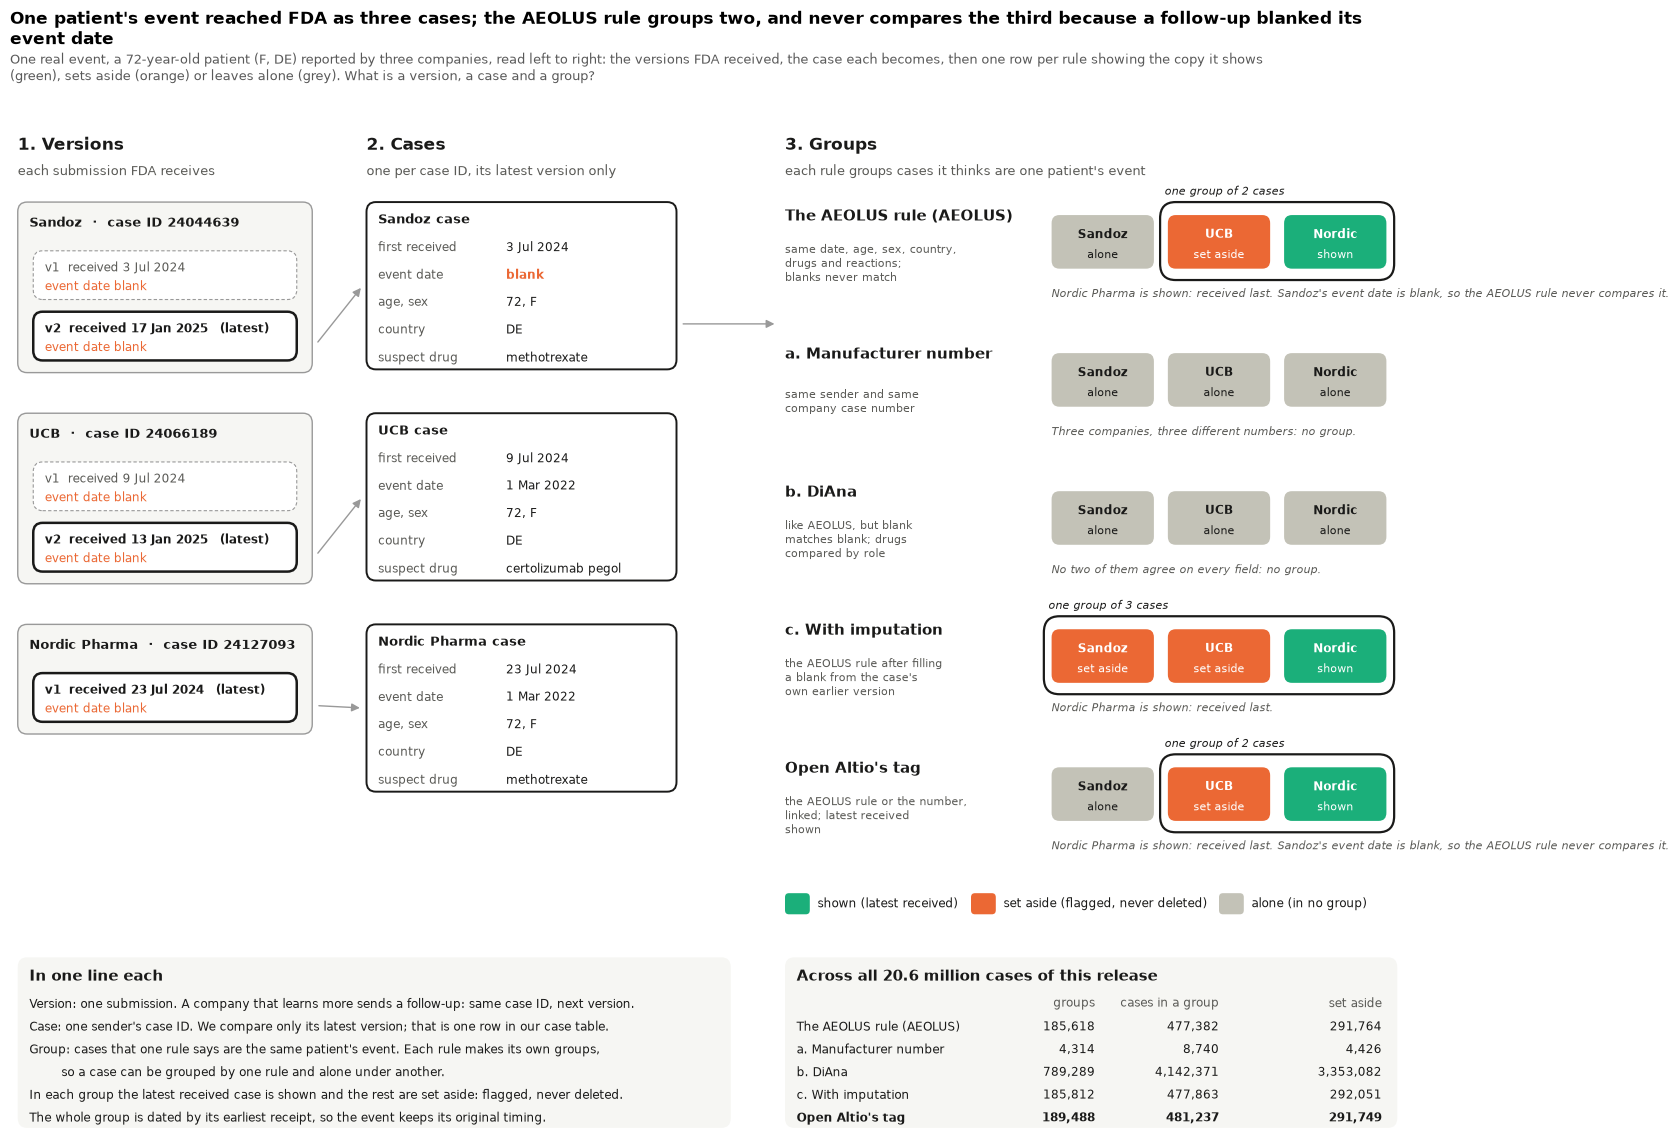

In [3]:
EX = {
    "Sandoz": "24044639",
    "UCB": "24066189",
    "Nordic Pharma": "24127093",
}  # one real event, three companies
IDS = sql_list(EX.values())


def day(d):
    return "blank" if d is None or pd.isna(d) else f"{d.day} {d:%b %Y}"


vers = q(f"""SELECT caseid, caseversion_T, fda_dt_T, event_dt_T FROM demo_T WHERE caseid IN ({IDS})
             QUALIFY row_number() OVER (PARTITION BY caseid, caseversion_T ORDER BY qnum_T DESC) = 1 ORDER BY caseid, caseversion_T""")
cards = q(f"""SELECT r.caseid, r.first_fda_dt_T, r.event_dt, r.age, r.sex, r.country_fix_T,
                     (SELECT string_agg(DISTINCT lower(d.drugname_norm_T), ', ') FROM drug_latest_T d
                      WHERE d.era_T = r.era_T AND d.primaryid = r.primaryid AND d.quarter_T = r.quarter_T AND d.role_cod = 'PS') AS suspect
              FROM w.case_rules_T r WHERE r.caseid IN ({IDS})""").set_index("caseid")
RULE_ROWS = [
    (
        "cur",
        "The AEOLUS rule (AEOLUS)",
        "same date, age, sex, country,\ndrugs and reactions;\nblanks never match",
    ),
    ("mfr", "a. Manufacturer number", "same sender and same\ncompany case number"),
    ("rb", "b. DiAna", "like AEOLUS, but blank\nmatches blank; drugs\ncompared by role"),
    (
        "imp",
        "c. With imputation",
        "the AEOLUS rule after filling\na blank from the case's\nown earlier version",
    ),
    (
        "tag",
        "Open Altio's tag",
        "the AEOLUS rule or the number,\nlinked; latest received\nshown",
    ),
]


def states(rule):
    """example case -> (state, group size) under one rule; state is shown, set aside or alone."""
    if rule == "tag":
        g = q(f"""SELECT l.caseid, l.shown_T, count(*) OVER (PARTITION BY l.comp_T) AS n FROM w.lg_tag_T l
                  WHERE l.comp_T IN (SELECT comp_T FROM w.lg_tag_T WHERE caseid IN ({IDS}))""")
    else:
        g = q(f"""SELECT caseid, row_number() OVER (PARTITION BY g_{rule}_T ORDER BY {LATEST}) = 1 AS shown_T, n_{rule}_T AS n
                  FROM w.case_rules_T WHERE g_{rule}_T IN (SELECT g_{rule}_T FROM w.case_rules_T WHERE caseid IN ({IDS}) AND n_{rule}_T > 1)""")
    g = g.set_index("caseid")
    return {
        name: (("shown" if g.shown_T[cid] else "set aside"), int(g.n[cid]))
        if cid in g.index
        else ("alone", 1)
        for name, cid in EX.items()
    }


def note(rule, st):
    grouped = [n for n, (s, _) in st.items() if s != "alone"]
    alone = [n for n, (s, _) in st.items() if s == "alone"]
    parts = []
    if grouped:
        shown = (
            next(n for n in grouped if st[n][0] == "shown")
            if any(st[n][0] == "shown" for n in grouped)
            else None
        )
        parts.append(
            f"{shown} is shown: received last."
            if shown
            else "The shown copy is another case in the group."
        )
    for n in alone:
        c = cards.loc[EX[n]]
        if rule in ("cur", "imp", "tag") and pd.isna(c.event_dt):
            parts.append(
                f"{n.split()[0]}'s event date is blank"
                + (", so the AEOLUS rule never compares it." if rule != "imp" else ".")
            )
    if not grouped:
        parts.append(
            "No two of them agree on every field: no group."
            if rule != "mfr"
            else "Three companies, three different numbers: no group."
        )
    return " ".join(parts)


fig, ax = plt.subplots(figsize=(18, 13.5))
ax.set_xlim(0, 180)
ax.set_ylim(0, 128)
ax.axis("off")


def box(x, y, w, h, fc="white", ec="#999", lw=1, r=1.2, ls="-", z=1):
    ax.add_patch(
        FancyBboxPatch(
            (x, y),
            w,
            h,
            boxstyle=f"round,pad=0,rounding_size={r}",
            fc=fc,
            ec=ec,
            lw=lw,
            ls=ls,
            zorder=z,
        )
    )


def t(x, y, s, size=9, color=INK, weight="normal", ha="left", va="center", style="normal"):
    ax.text(x, y, s, fontsize=size, color=color, weight=weight, ha=ha, va=va, style=style, zorder=5)


def arrow(x0, y0, x1, y1):
    ax.add_patch(
        FancyArrowPatch(
            (x0, y0), (x1, y1), arrowstyle="-|>", mutation_scale=12, color="#999", lw=1, zorder=0
        )
    )


c0 = cards.iloc[0]
cur_st = states("cur")
if [n for n in EX if cur_st[n][0] != "alone"] == ["UCB", "Nordic Pharma"] and pd.isna(
    cards.loc[EX["Sandoz"]].event_dt
):
    claim = "One patient's event reached FDA as three cases; the AEOLUS rule groups two, and never compares the third because a follow-up blanked its event date"
else:
    claim = "One patient's event reached FDA as three cases, and each rule groups them differently"
for x, s, sub in [
    (1, "1. Versions", "each submission FDA receives"),
    (46, "2. Cases", "one per case ID, its latest version only"),
    (100, "3. Groups", "each rule groups cases it thinks are one patient's event"),
]:
    t(x, 122, s, 12.5, weight="bold")
    t(x, 118.8, sub, 9.5, MUTED)
tops = [115, 89, 63]
for (name, cid), top in zip(EX.items(), tops, strict=True):
    vs = vers[vers.caseid == cid]
    h = 6 + 7.5 * len(vs)
    box(1, top - h, 38, h, fc="#f6f6f3")
    t(2.5, top - 2.6, f"{name}  ·  case ID {cid}", 9.5, weight="bold")
    for i, (_, v) in enumerate(vs.iterrows()):
        latest = i == len(vs) - 1
        y = top - 6 - 7.5 * i - 6
        box(
            3,
            y,
            34,
            6,
            fc="white",
            ec=INK if latest else "#999",
            lw=1.8 if latest else 0.8,
            ls="-" if latest else (0, (3, 2)),
        )
        t(
            4.5,
            y + 3.9,
            f"v{int(v.caseversion_T)}  received {day(v.fda_dt_T)}"
            + ("   (latest)" if latest else ""),
            8.8,
            INK if latest else MUTED,
            weight="bold" if latest else "normal",
        )
        ev = day(v.event_dt_T)
        t(
            4.5,
            y + 1.6,
            f"event date {ev}",
            8.3,
            ORANGE if ev == "blank" else (INK if latest else MUTED),
        )
    c = cards.loc[cid]
    card = [
        ("first received", day(c.first_fda_dt_T)),
        (
            "event date",
            "blank"
            if pd.isna(c.event_dt)
            else day(pd.to_datetime(c.event_dt, format="%Y%m%d", errors="coerce")),
        ),
        ("age, sex", f"{c.age}, {c.sex}"),
        ("country", c.country_fix_T),
        ("suspect drug", c.suspect),
    ]
    ch = 3.6 + 3.4 * len(card)
    box(46, top - ch, 40, ch, ec=INK, lw=1.4)
    t(47.5, top - 2.2, f"{name} case", 9.5, weight="bold")
    for j, (k, v) in enumerate(card):
        yy = top - 5.6 - 3.4 * j
        t(47.5, yy, k, 8.6, MUTED)
        t(
            64,
            yy,
            v,
            8.6,
            ORANGE if v == "blank" else INK,
            weight="bold" if v == "blank" else "normal",
        )
    arrow(39.5, top - h + 3.5, 45.5, top - ch / 2)
xs = dict(zip(EX, [141, 156, 171], strict=True))
col = {"shown": GREEN, "set aside": ORANGE, "alone": GREY}
for i, (rule, rname, how) in enumerate(RULE_ROWS):
    st = states(rule)
    y = 110 - 17 * i
    t(100, y + 3.2, rname, 10.5, weight="bold")
    t(100, y - 2.6, how, 8.2, MUTED)
    grp = [n for n in EX if st[n][0] != "alone"]
    if grp:
        x0, x1 = xs[grp[0]] - 7.6, xs[grp[-1]] + 7.6
        box(x0, y - 4.6, x1 - x0, 9.6, fc="none", ec=INK, lw=1.6, r=2, z=2)
        size = max(st[n][1] for n in grp)
        t(
            x0 + 0.6,
            y + 6.3,
            f"one group of {size} cases"
            + (f" ({size - len(grp)} not shown)" if size > len(grp) else ""),
            8,
            INK,
            style="italic",
        )
    for name, x in xs.items():
        s = st[name][0]
        box(x - 6.6, y - 3.2, 13.2, 6.6, fc=col[s], ec="none", r=1, z=3)
        t(
            x,
            y + 1,
            name.split()[0],
            8.8,
            "white" if s != "alone" else INK,
            weight="bold",
            ha="center",
        )
        t(x, y - 1.5, s, 7.8, "white" if s != "alone" else INK, ha="center")
    t(134.4, y - 6.3, note(rule, st), 8, MUTED, style="italic")
arrow(86.5, 100, 99, 100)
for k, (lab, c) in enumerate(col.items()):
    lx = [100, 124, 156][k]
    box(lx, 27.3, 3.2, 2.6, fc=c, ec="none", r=0.5)
    t(
        lx + 4.2,
        28.6,
        {
            "shown": "shown (latest received)",
            "set aside": "set aside (flagged, never deleted)",
            "alone": "alone (in no group)",
        }[lab],
        8.3,
    )
box(1, 1, 92, 21, fc="#f6f6f3", ec="none")
t(2.5, 19.6, "In one line each", 10.5, weight="bold")
for j, s in enumerate(
    [
        "Version: one submission. A company that learns more sends a follow-up: same case ID, next version.",
        "Case: one sender's case ID. We compare only its latest version; that is one row in our case table.",
        "Group: cases that one rule says are the same patient's event. Each rule makes its own groups,",
        "        so a case can be grouped by one rule and alone under another.",
        "In each group the latest received case is shown and the rest are set aside: flagged, never deleted.",
        "The whole group is dated by its earliest receipt, so the event keeps its original timing.",
    ]
):
    t(2.5, 16.2 - 2.8 * j, s, 8.8)
totals = [
    (name, measure([f"g_{rule}_T"], table="w.case_rules_T")) for rule, name, _ in RULE_ROWS[:4]
]
lt = q(
    "SELECT count(DISTINCT comp_T) AS groups, count(*) AS in_groups, count(*) - count(DISTINCT comp_T) AS set_aside FROM w.lg_tag_T"
).iloc[0]
cases_all = con.execute("SELECT count(*) FROM w.case_rules_T").fetchone()[0]
box(100, 1, 79, 21, fc="#f6f6f3", ec="none")
t(
    101.5,
    19.6,
    f"Across all {cases_all / 1e6:.1f} million cases of this release",
    10.5,
    weight="bold",
)
cx = [101.5, 140, 156, 177]
for k, h in enumerate(["", "groups", "cases in a group", "set aside"]):
    t(cx[k], 16.3, h, 8.6, MUTED, ha="left" if k == 0 else "right")
for j, (name, m) in enumerate(totals + [(RULE_ROWS[4][1], lt)]):
    yy = 13.4 - 2.8 * j
    for k, v in enumerate([name, m["groups"], m["in_groups"], m["set_aside"]]):
        t(
            cx[k],
            yy,
            v if k == 0 else f"{int(v):,}",
            8.8,
            ha="left" if k == 0 else "right",
            weight="bold" if j == 4 else "normal",
        )
title(
    header(fig),
    claim,
    f"One real event, a {c0.age}-year-old patient ({c0.sex}, {c0.country_fix_T}) reported by three companies, read left to right: "
    "the versions FDA received, the case each becomes, then one row per rule showing the copy it shows (green), sets aside (orange) or leaves alone (grey).",
    "What is a version, a case and a group?",
)
plt.show()

## How the notebook counts

- A drug or reaction **set** is compared by fingerprint: the XOR of the MD5s of its distinct values. Equal sets get equal fingerprints, so nothing needs sorting. Drug sets use the normalised drug name (`drugname_norm_T`), reaction sets the PT in capitals.
- Notebook 02 measures three gaps that keep duplicates from matching across the AERS to FAERS change, and the release closes them: one version per case across eras (`rules/latest-version.md`), legacy country names read as ISO codes (`rules/legacy-country.md`), reaction terms compared in capitals (`rules/reaction-term-case.md`).
- Every rule's groups use the same shown copy, the latest received (choice 3), so "set aside" means the same under every rule. Only the check in section 1 uses the earliest received, the order of a release built with the choices off, to compare with its flags.
- `w.tag_T` and the `w.lg_*` tables hold Open Altio's tag, built step by step (the AEOLUS rule, the padded-date guard, the guarded manufacturer number, the missing country code) and linked with a union-find in Python, apart from the release code's label propagation in SQL.

## 1. What the AEOLUS rule does

The rule (AEOLUS, Banda et al. 2016): two cases are one when they agree exactly on event date, age, age unit, sex, country (where it happened, else the reporter's, a legacy name read as its code), the set of drug names and the set of reactions (compared in capitals). All seven must be filled.

**Reading the chart.** One bar per era, and one for both: the share of its cases the rule never compares (a field empty), compares and finds alone, shows from a group, or sets aside. The last column of the table counts the cases whose flag differs from the release's: zero on a release built with the choices off, and on the release read here, which has every choice on and shows the latest received copy, the cases the choices changed.

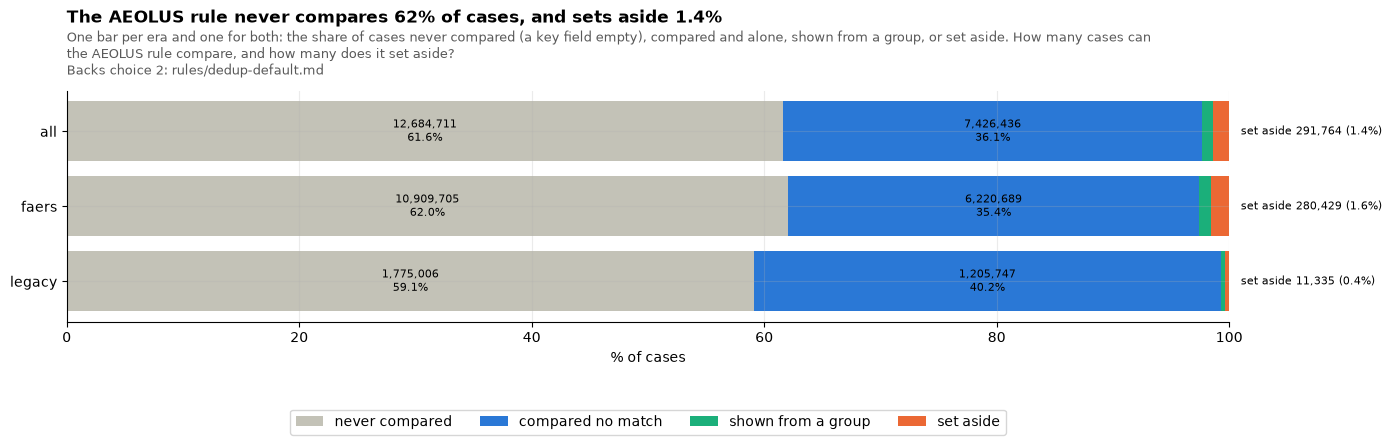

,cases,never_compared,set_aside,differ_from_release
era,,,,
legacy,3002752,1775006,11335,28107
faers,17585777,10909705,280429,355612
all,20588529,12684711,291764,383719


In [4]:
CUR_FIELDS = {
    "event date": "event_dt",
    "age": "age",
    "age unit": "age_cod",
    "sex": "sex",
    "country": "country_fix_T",
    "drugs": "drugs_h_T",
    "reactions": "pts_up_h_T",
}
COMPLETE = " AND ".join(f"{c} IS NOT NULL" for c in CUR_FIELDS.values())
# The check uses the release's own order (earliest received kept), so it can be compared with its flags.
rep = q(f"""
WITH f AS (SELECT era_T, released_dup_T, released_kept_T, {COMPLETE} AS complete,
             {COMPLETE} AND count(*) OVER (PARTITION BY {COMPLETE}, {", ".join(CUR_FIELDS.values())}) > 1 AS dup_T,
             NOT ({COMPLETE}) OR row_number() OVER (PARTITION BY {COMPLETE}, {", ".join(CUR_FIELDS.values())} ORDER BY {EARLIEST}) = 1 AS kept_T
           FROM w.case_w_T)
SELECT coalesce(era_T, 'all') AS era, count(*) AS cases, count(*) FILTER (WHERE NOT complete) AS never_compared,
  count(*) FILTER (WHERE complete AND NOT dup_T) AS compared_no_match, count(*) FILTER (WHERE dup_T AND kept_T) AS shown_from_a_group,
  count(*) FILTER (WHERE NOT kept_T) AS set_aside, count(*) FILTER (WHERE dup_T <> released_dup_T OR kept_T <> released_kept_T) AS differ_from_release
FROM f GROUP BY ROLLUP (era_T) ORDER BY cases""").set_index("era")
parts = ["never_compared", "compared_no_match", "shown_from_a_group", "set_aside"]
share = rep[parts].div(rep.cases, axis=0) * 100
fig, ax = plt.subplots(figsize=(15, 3))
left = np.zeros(len(share))
for i, p in enumerate(parts):
    bars = ax.barh(
        share.index,
        share[p],
        left=left,
        color=[SERIES[7], SERIES[0], SERIES[2], SERIES[1]][i],
        label=p.replace("_", " "),
    )
    for b, v, n in zip(bars, share[p], rep[p], strict=True):
        if v > 5:
            ax.text(
                b.get_x() + b.get_width() / 2,
                b.get_y() + b.get_height() / 2,
                f"{n:,}\n{v:.1f}%",
                ha="center",
                va="center",
                fontsize=8,
            )
    left += share[p].values
for y, (_, r) in enumerate(rep.iterrows()):
    ax.text(
        101,
        y,
        f"set aside {r.set_aside:,} ({100 * r.set_aside / r.cases:.1f}%)",
        va="center",
        fontsize=8,
    )
ax.set_xlim(0, 100)
ax.set_xlabel("% of cases")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.35))
al = rep.loc["all"]
title(
    header(fig),
    f"The AEOLUS rule never compares {100 * al.never_compared / al.cases:.0f}% of cases, and sets aside {100 * al.set_aside / al.cases:.1f}%",
    "One bar per era and one for both: the share of cases never compared (a key field empty), compared and alone, shown from a group, or set aside.",
    "How many cases can the AEOLUS rule compare, and how many does it set aside?",
    rule_line(2),
)
plt.show()
rep[["cases", "never_compared", "set_aside", "differ_from_release"]]

**Reading the chart.** Left: one bar per field and era, the share of cases with that field empty ("age unit" counts only cases that have an age). Right: among the cases never compared, one bar per combination of empty fields, the most common ten.

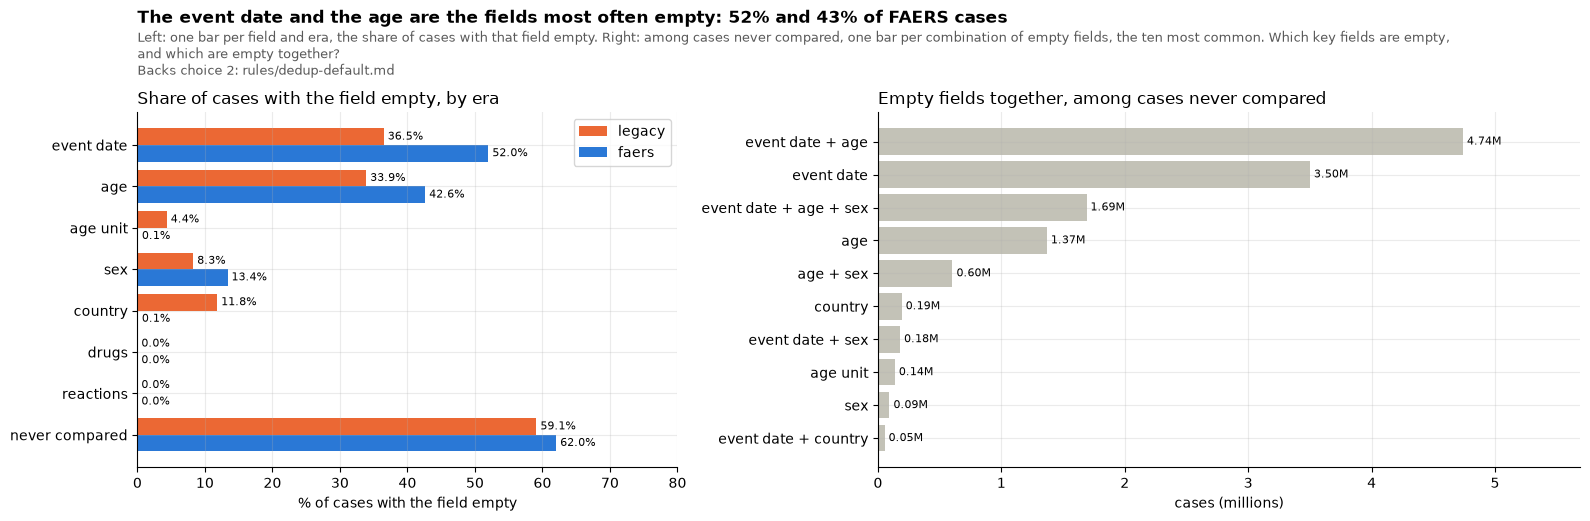

never compared: 12,684,711 of 20,588,529 (61.6%); missing exactly one field (age and its unit as one field): 5,293,059


In [5]:
EMPTY = {
    "event date": "event_dt IS NULL",
    "age": "age IS NULL",
    "age unit": "age IS NOT NULL AND age_cod IS NULL",
    "sex": "sex IS NULL",
    "country": "country_fix_T IS NULL",
    "drugs": "drugs_h_T IS NULL",
    "reactions": "pts_up_h_T IS NULL",
}
NEVER = " OR ".join(f"{c} IS NULL" for c in CUR_FIELDS.values())
PCT_EMPTY = (
    ", ".join(f'100 * avg(({c})::INT) AS "{n}"' for n, c in EMPTY.items())
    + f', 100 * avg(({NEVER})::INT) AS "never compared"'
)
by_era = q(f"SELECT era_T, {PCT_EMPTY} FROM w.case_w_T GROUP BY 1 ORDER BY 1").set_index("era_T").T
combo = q(f"""SELECT concat_ws(' + ', {", ".join(f"CASE WHEN {c} THEN '{n}' END" for n, c in EMPTY.items())}) AS empty_fields, count(*) AS cases
              FROM w.case_w_T WHERE {NEVER} GROUP BY 1 ORDER BY 2 DESC""")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw={"width_ratios": [1, 1.3]})
y = np.arange(len(by_era))
h = 0.4
for i, era in enumerate(["legacy", "faers"]):
    label_bars(
        a1,
        a1.barh(
            y + (i - 0.5) * h, by_era[era], h, color=SERIES[1 if era == "legacy" else 0], label=era
        ),
        "{:.1f}%",
        horizontal=True,
    )
a1.set_yticks(y)
a1.set_yticklabels(by_era.index)
a1.invert_yaxis()
a1.set_xlim(0, 80)
a1.set_xlabel("% of cases with the field empty")
a1.legend()
a1.set_title("Share of cases with the field empty, by era", loc="left")
top = combo.head(10)
label_bars(
    a2,
    a2.barh(top.empty_fields[::-1], top.cases[::-1] / 1e6, color=SERIES[7]),
    "{:.2f}M",
    horizontal=True,
)
a2.set_xlabel("cases (millions)")
a2.set_title("Empty fields together, among cases never compared", loc="left")
a2.set_xlim(0, top.cases.max() / 1e6 * 1.2)
plt.tight_layout()
title(
    header(fig),
    f"The event date and the age are the fields most often empty: {by_era.loc['event date', 'faers']:.0f}% and {by_era.loc['age', 'faers']:.0f}% of FAERS cases",
    "Left: one bar per field and era, the share of cases with that field empty. Right: among cases never compared, one bar per combination of empty fields, the ten most common.",
    "Which key fields are empty, and which are empty together?",
    rule_line(2),
)
plt.show()
# One field missing, with age and its unit counted as one field (a case with no age has no unit either)
ONE = " + ".join(
    f"({c})::INT"
    for c in [
        "event_dt IS NULL",
        "age IS NULL OR age_cod IS NULL",
        "sex IS NULL",
        "country_fix_T IS NULL",
        "drugs_h_T IS NULL",
        "pts_up_h_T IS NULL",
    ]
)
one_missing = q(
    f"SELECT count(*) FILTER (WHERE {ONE} = 1) AS one, count(*) FILTER (WHERE {NEVER}) AS never, count(*) AS cases FROM w.case_w_T"
).iloc[0]
print(
    f"never compared: {one_missing.never:,} of {one_missing.cases:,} ({100 * one_missing.never / one_missing.cases:.1f}%); "
    f"missing exactly one field (age and its unit as one field): {one_missing.one:,}"
)

**Reading the chart.** Top: one row per field, one column per year FDA first received the case; the number is the share of that year's cases with the field empty. Bottom: one line per era, the share of each year's cases the rule never compares.

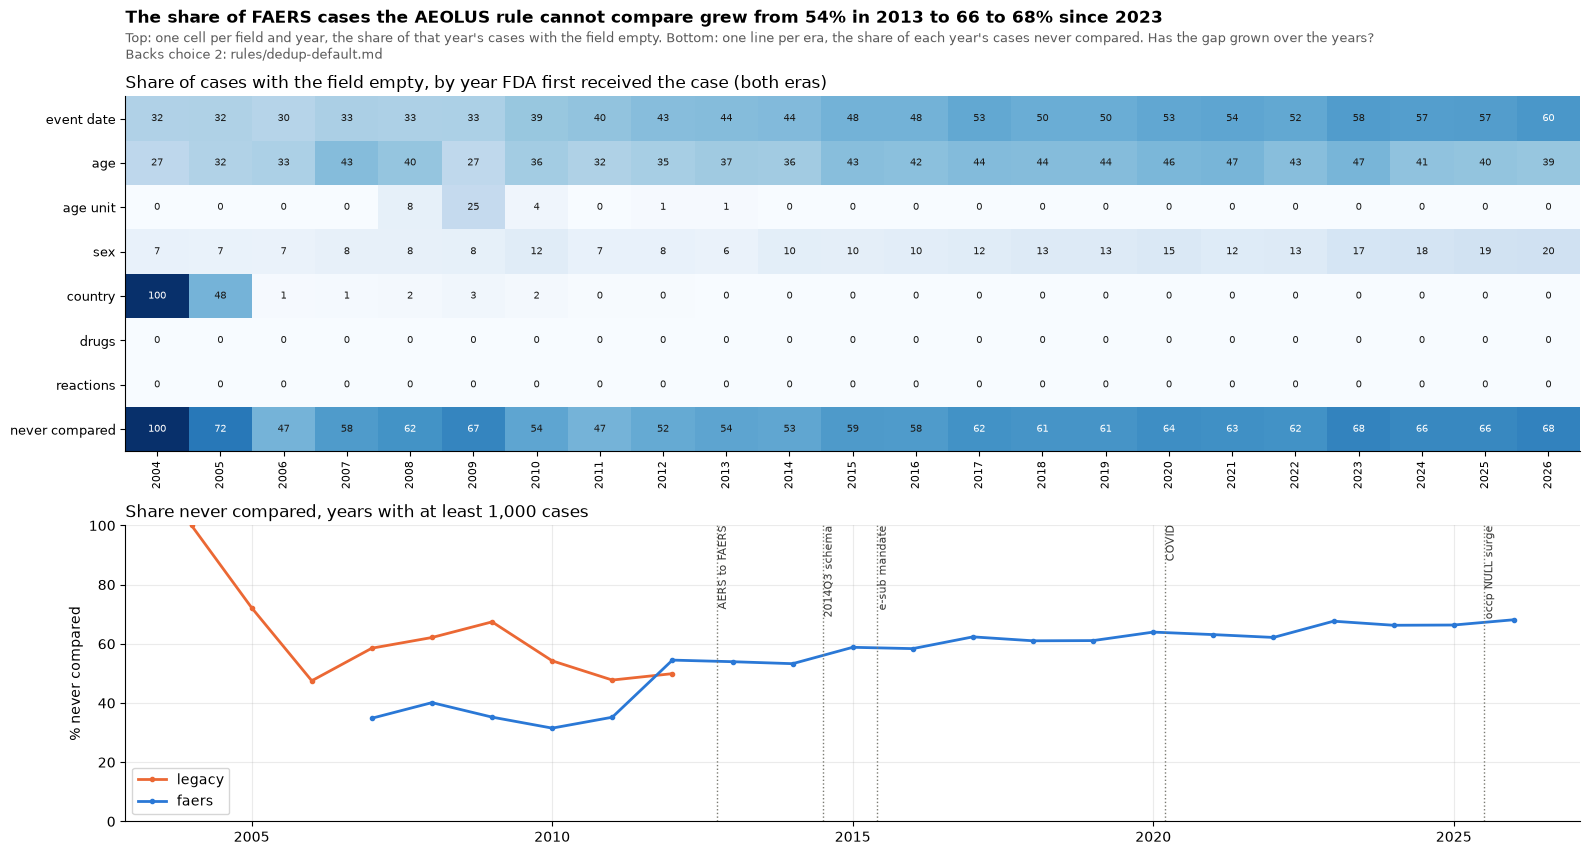

In [6]:
yr = q(
    f"SELECT init_year_T AS year, era_T, count(*) AS cases, {PCT_EMPTY} FROM w.case_w_T WHERE init_year_T BETWEEN 2004 AND 2026 GROUP BY ALL ORDER BY 1"
)
allyr = q(
    f"SELECT init_year_T AS year, {PCT_EMPTY} FROM w.case_w_T WHERE init_year_T BETWEEN 2004 AND 2026 GROUP BY 1 ORDER BY 1"
).set_index("year")
fig, (a1, a2) = plt.subplots(2, 1, figsize=(16, 8), gridspec_kw={"height_ratios": [1.2, 1]})
grid(
    allyr.T,
    "Share of cases with the field empty, by year FDA first received the case (both eras)",
    a1,
)
for era in ["legacy", "faers"]:
    s = yr[(yr.era_T == era) & (yr.cases >= 1000)]
    a2.plot(
        s.year,
        s["never compared"],
        marker="o",
        ms=3,
        label=era,
        color=SERIES[1 if era == "legacy" else 0],
    )
a2.set_ylim(0, 100)
a2.set_ylabel("% never compared")
a2.legend()
a2.set_title("Share never compared, years with at least 1,000 cases", loc="left")
mark_years(a2)
fy = yr[yr.era_T == "faers"].set_index("year")["never compared"]
plt.tight_layout()
title(
    header(fig),
    f"The share of FAERS cases the AEOLUS rule cannot compare grew from {fy.loc[2013]:.0f}% in 2013 to {fy.loc[2023:].min():.0f} to {fy.loc[2023:].max():.0f}% since 2023",
    "Top: one cell per field and year, the share of that year's cases with the field empty. Bottom: one line per era, the share of each year's cases never compared.",
    "Has the gap grown over the years?",
    rule_line(2),
)
plt.show()

**Reading the chart.** One row per kind of sender (`rept_cod`): companies send expedited reports (15-day, also 30DAY and 5DAY) and periodic reports; patients and health professionals send direct reports to FDA. Each number is the share of that sender type's cases with the field empty.

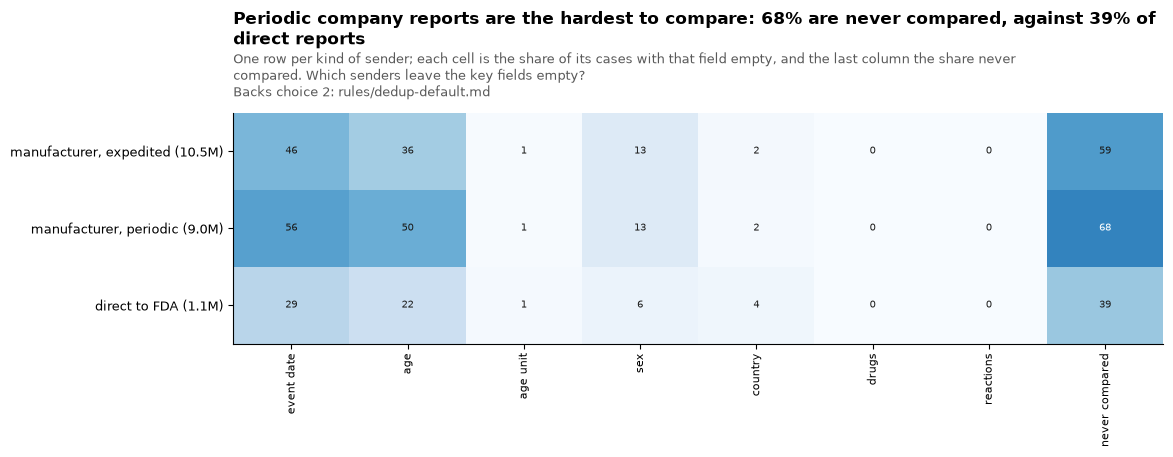

In [7]:
st = q(
    f"SELECT sender_type_T AS sender, count(*) AS cases, {PCT_EMPTY} FROM w.case_w_T GROUP BY 1 HAVING count(*) >= 1000 ORDER BY 2 DESC"
).set_index("sender")
fig, ax = plt.subplots(figsize=(12, 3))
grid(st.drop(columns="cases"), "", ax)
ax.set_yticklabels([f"{s} ({n / 1e6:.1f}M)" for s, n in zip(st.index, st.cases, strict=True)])
title(
    header(fig),
    f"Periodic company reports are the hardest to compare: {st.loc['manufacturer, periodic', 'never compared']:.0f}% are never compared, "
    f"against {st.loc['direct to FDA', 'never compared']:.0f}% of direct reports",
    "One row per kind of sender; each cell is the share of its cases with that field empty, and the last column the share never compared.",
    "Which senders leave the key fields empty?",
    rule_line(2),
)
plt.show()

**Reading the chart.** One line per kind of event date, the share of each year's cases (that have an event date) written that way. Legacy AERS wrote a year-only date as 1 January of that year and a month-only date as the 1st. FAERS kept partial dates as 4 or 6 digits from 2013. A padded date matches every other case from the same year or month padded the same way; choice 7 deals with that.

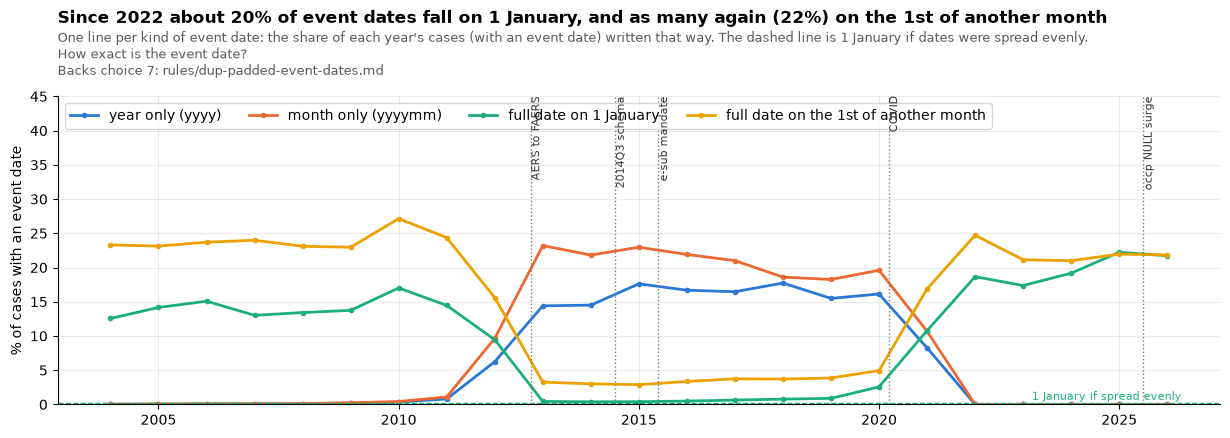

In [8]:
prec = q("""SELECT init_year_T AS year,
  100 * avg((length(event_dt) = 4)::INT) AS "year only (yyyy)", 100 * avg((length(event_dt) = 6)::INT) AS "month only (yyyymm)",
  100 * avg((length(event_dt) = 8 AND right(event_dt, 4) = '0101')::INT) AS "full date on 1 January",
  100 * avg((length(event_dt) = 8 AND right(event_dt, 2) = '01' AND right(event_dt, 4) <> '0101')::INT) AS "full date on the 1st of another month"
  FROM w.case_w_T WHERE event_dt IS NOT NULL AND init_year_T BETWEEN 2004 AND 2026 GROUP BY 1 ORDER BY 1""").set_index(
    "year"
)
fig, ax = plt.subplots(figsize=(15, 4))
for i, c in enumerate(prec.columns):
    ax.plot(prec.index, prec[c], marker="o", ms=3, label=c, color=SERIES[i])
ax.axhline(100 / 365, color=SERIES[2], lw=1, ls="--")
ax.text(
    2026.3,
    100 / 365,
    "1 January if spread evenly",
    fontsize=8,
    va="bottom",
    ha="right",
    color=SERIES[2],
)
ax.set_ylim(0, 45)
ax.set_ylabel("% of cases with an event date")
ax.legend(ncol=4, loc="upper left")
mark_years(ax)
since = prec.loc[2022:]
title(
    header(fig),
    f"Since 2022 about {since['full date on 1 January'].mean():.0f}% of event dates fall on 1 January, "
    f"and as many again ({since['full date on the 1st of another month'].mean():.0f}%) on the 1st of another month",
    "One line per kind of event date: the share of each year's cases (with an event date) written that way. The dashed line is 1 January if dates were spread evenly.",
    "How exact is the event date?",
    rule_line(7),
)
plt.show()

**Reading the chart.** Notebook 02's country and capitals fixes, one at a time, on the AEOLUS rule, starting from FDA's text as compared before them. Left: one bar per step, the cases set aside. Right: groups that hold cases from both eras, and of those, groups made of one case number's two copies (zero, because the grain holds one version per case).

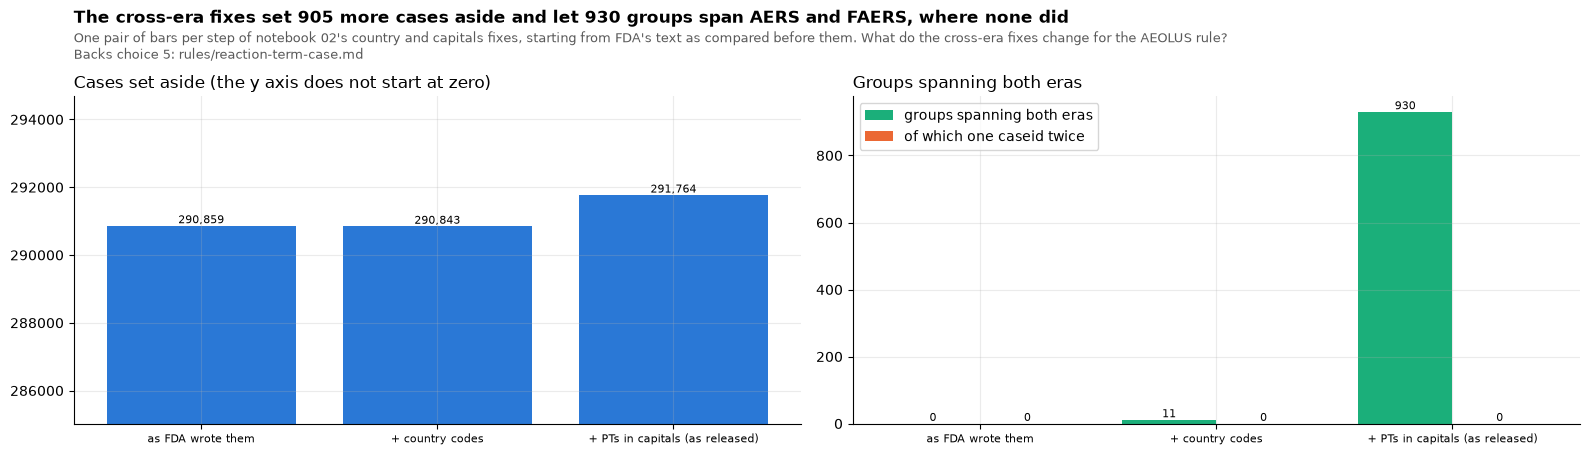

,groups_,set_aside,cross_era_groups,same_caseid_twice
step,,,,
as FDA wrote them,184825,290859.0,0,0
+ country codes,184806,290843.0,11,0
+ PTs in capitals (as released),185618,291764.0,930,0


In [9]:
base = ["event_dt", "age", "age_cod", "sex"]
STEPS = {
    "as FDA wrote them": base + ["country_raw_T", "drugs_h_T", "pts_h_T"],
    "+ country codes": base + ["country_fix_T", "drugs_h_T", "pts_h_T"],
    "+ PTs in capitals (as released)": base + ["country_fix_T", "drugs_h_T", "pts_up_h_T"],
}
rows = []
for step, cols in STEPS.items():
    rows.append(
        q(f"""WITH s AS (SELECT count(*) AS n, count(DISTINCT era_T) AS eras, count(DISTINCT coalesce(caseid, case_key_T)) AS ids
                                 FROM w.case_w_T WHERE {" AND ".join(f"{c} IS NOT NULL" for c in cols)}
                                 GROUP BY {", ".join(cols)} HAVING count(*) > 1)
        SELECT '{step}' AS step, count(*) AS groups_, sum(n) - count(*) AS set_aside,
               count(*) FILTER (WHERE eras = 2) AS cross_era_groups, count(*) FILTER (WHERE ids < n) AS same_caseid_twice FROM s""")
    )
fixes = pd.concat(rows).set_index("step")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 4))
label_bars(a1, a1.bar(fixes.index, fixes.set_aside, color=SERIES[0]))
a1.set_ylim(fixes.set_aside.min() * 0.98, fixes.set_aside.max() * 1.01)
a1.set_title("Cases set aside (the y axis does not start at zero)", loc="left")
x = np.arange(len(fixes))
w = 0.4
label_bars(
    a2,
    a2.bar(
        x - w / 2, fixes.cross_era_groups, w, color=SERIES[2], label="groups spanning both eras"
    ),
)
label_bars(
    a2,
    a2.bar(
        x + w / 2, fixes.same_caseid_twice, w, color=SERIES[1], label="of which one caseid twice"
    ),
)
a2.set_xticks(x)
a2.set_xticklabels(fixes.index)
a2.legend()
a2.set_title("Groups spanning both eras", loc="left")
for a in (a1, a2):
    a.tick_params(axis="x", labelsize=8)
plt.tight_layout()
title(
    header(fig),
    f"The cross-era fixes set {int(fixes.set_aside.iloc[-1] - fixes.set_aside.iloc[0]):,} more cases aside and let "
    f"{int(fixes.cross_era_groups.iloc[-1]):,} groups span AERS and FAERS, where none did",
    "One pair of bars per step of notebook 02's country and capitals fixes, starting from FDA's text as compared before them.",
    "What do the cross-era fixes change for the AEOLUS rule?",
    rule_line(5),
)
plt.show()
fixes

**What section 1 shows.** The fingerprints find 185,618 groups and set 291,764 cases aside (1.4%). The release read here has every choice on, so its flags differ from this check for 383,719 cases (28,107 legacy, 355,612 FAERS); the last step of The seven choices rebuilds the release's flags exactly. The AEOLUS rule never compares 12,684,711 cases (61.6%), mostly because the event date (empty in 52% of FAERS cases) or the age (43%) is missing. 5.3 million cases (5,293,059) miss exactly one key field, counting age and its unit as one field. The gap is widest in periodic company reports (68% never compared) and smallest in direct reports (39%), and it has grown from about 54% of FAERS cases first received in 2013 to 66 to 68% since 2023.

Since 2022 FAERS carries no partial event dates, and about two in five fall on the 1st of a month. For those cases an exact date match is often only a same-month or same-year match.

Compared as FDA wrote them, no group spans the AERS to FAERS change. Reading legacy country names as codes gives 11 cross-era groups; comparing PTs in capitals as well gives 930. Together the two fixes set aside 905 more cases (291,764 against 290,859).

## 2. The alternatives, measured

Each rule is measured on this release, against the same cases, with the same shown copy (the latest received), so the counts compare.

- **a. Manufacturer number** (DiAna): one case per (`mfr_num`, `mfr_sndr`). Cases missing either are never compared. Measured here as FDA wrote them; the chosen rule compares them trimmed and in capitals (choice 1).
- **b. DiAna's rule-based match** (`RB_duplicates`): exact match on event date, sex, reporter country, age in days, weight in kg, the reaction set, and three drug sets by role (primary suspect, secondary suspect, interacting or concomitant). **An empty field matches another empty field.** DiAna compares mapped substances; we use normalised drug names as a stand-in, so a brand and its generic do not match here. As in DiAna, cases with no drug or no reaction are left out of this rule.
- **c. AEOLUS with single imputation**: the AEOLUS rule, after filling one missing key field from another version of the same case.
- **d. Reports with no drug or no reaction** (DiAna): no usable drug name, or no reaction other than "no adverse event". Not duplicates, but DiAna removes them in the same step.

### a. Manufacturer number

**Reading the chart.** Left: one bar per sender, the cases of its in groups, the ten largest. Right: one bar per year, the cases set aside by the number that FDA first received that year.

4,314 groups, 8,740 cases in groups, 4,426 set aside; 1,084,346 never compared, 1,083,821 of them direct reports, which carry no manufacturer number
groups whose cases disagree on sex (one number reused for two patients): 79, holding 145 of the cases set aside


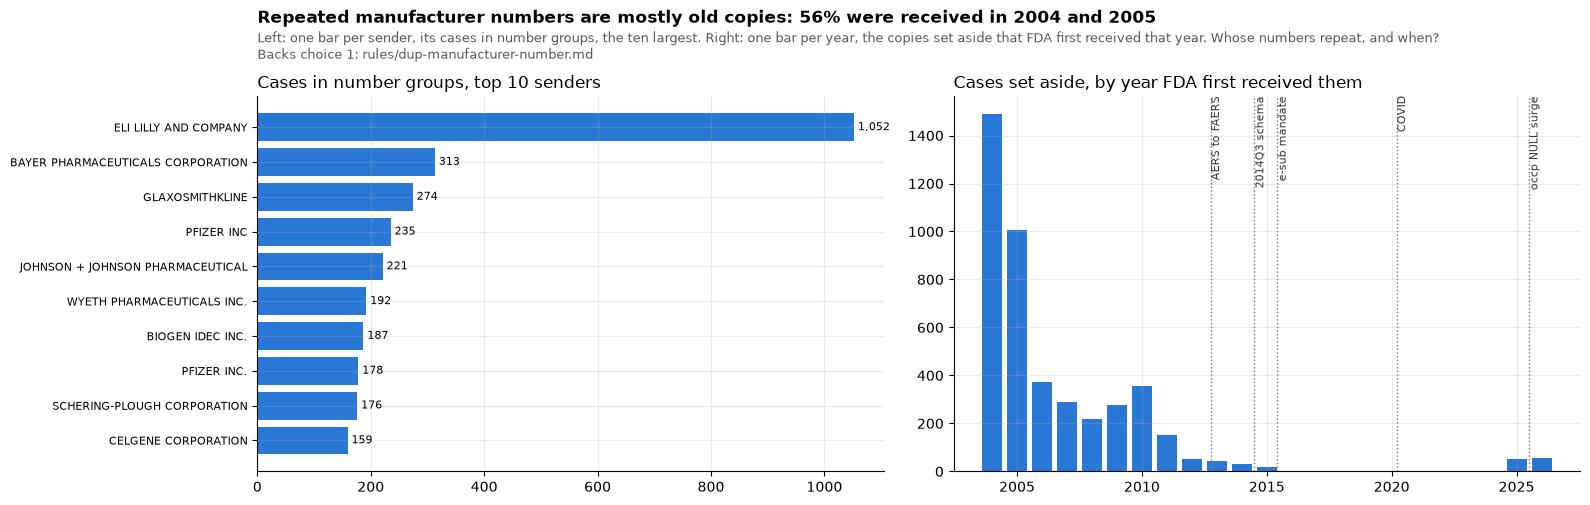

In [10]:
mfr = q("""SELECT count(DISTINCT g_mfr_T) FILTER (WHERE n_mfr_T > 1) AS groups_, count(*) FILTER (WHERE n_mfr_T > 1) AS in_groups,
           count(*) FILTER (WHERE aside_mfr_T) AS set_aside, count(*) FILTER (WHERE g_mfr_T IS NULL) AS never_compared,
           count(*) FILTER (WHERE g_mfr_T IS NULL AND sender_type_T = 'direct to FDA') AS never_compared_direct FROM w.case_rules_T""").iloc[
    0
]
print(
    f"{mfr.groups_:,} groups, {mfr.in_groups:,} cases in groups, {mfr.set_aside:,} set aside; "
    f"{mfr.never_compared:,} never compared, {mfr.never_compared_direct:,} of them direct reports, which carry no manufacturer number"
)
two_sexes = q("""SELECT count(*) AS groups_, sum(n) - count(*) AS set_aside FROM (
                   SELECT count(*) AS n FROM w.case_rules_T WHERE n_mfr_T > 1 GROUP BY g_mfr_T HAVING count(DISTINCT sex_mf_T) > 1)""").iloc[
    0
]
print(
    f"groups whose cases disagree on sex (one number reused for two patients): {int(two_sexes.groups_):,}, holding {int(two_sexes.set_aside):,} of the cases set aside"
)
senders = q(
    "SELECT mfr_sndr, count(*) AS cases FROM w.case_rules_T WHERE n_mfr_T > 1 GROUP BY 1 ORDER BY 2 DESC LIMIT 10"
)
years = q(
    "SELECT init_year_T AS year, count(*) AS set_aside FROM w.case_rules_T WHERE aside_mfr_T AND init_year_T BETWEEN 2004 AND 2026 GROUP BY 1 ORDER BY 1"
)
fig, (a2, a3) = plt.subplots(1, 2, figsize=(16, 4.5))
label_bars(
    a2, a2.barh(senders.mfr_sndr[::-1], senders.cases[::-1], color=SERIES[0]), horizontal=True
)
a2.set_title("Cases in number groups, top 10 senders", loc="left")
a2.tick_params(axis="y", labelsize=8)
a3.bar(years.year, years.set_aside, color=SERIES[0])
a3.set_title("Cases set aside, by year FDA first received them", loc="left")
mark_years(a3)
early = years[years.year.isin([2004, 2005])].set_aside.sum() / years.set_aside.sum()
plt.tight_layout()
title(
    header(fig),
    f"Repeated manufacturer numbers are mostly old copies: {100 * early:.0f}% were received in 2004 and 2005",
    "Left: one bar per sender, its cases in number groups, the ten largest. Right: one bar per year, the copies set aside that FDA first received that year.",
    "Whose numbers repeat, and when?",
    rule_line(1),
)
plt.show()

**Who made the copies?** Who creates a second case with the same number? Each later copy (every case in a number group but the first received) is sorted by how it reached FDA: its first version marked as a follow-up (the company sent a follow-up and FDA filed it as a new case), sent as new on the same day as the first copy (a double entry), sent as new on a later day (the company sent it again), or in a group whose cases disagree on sex (different patients).

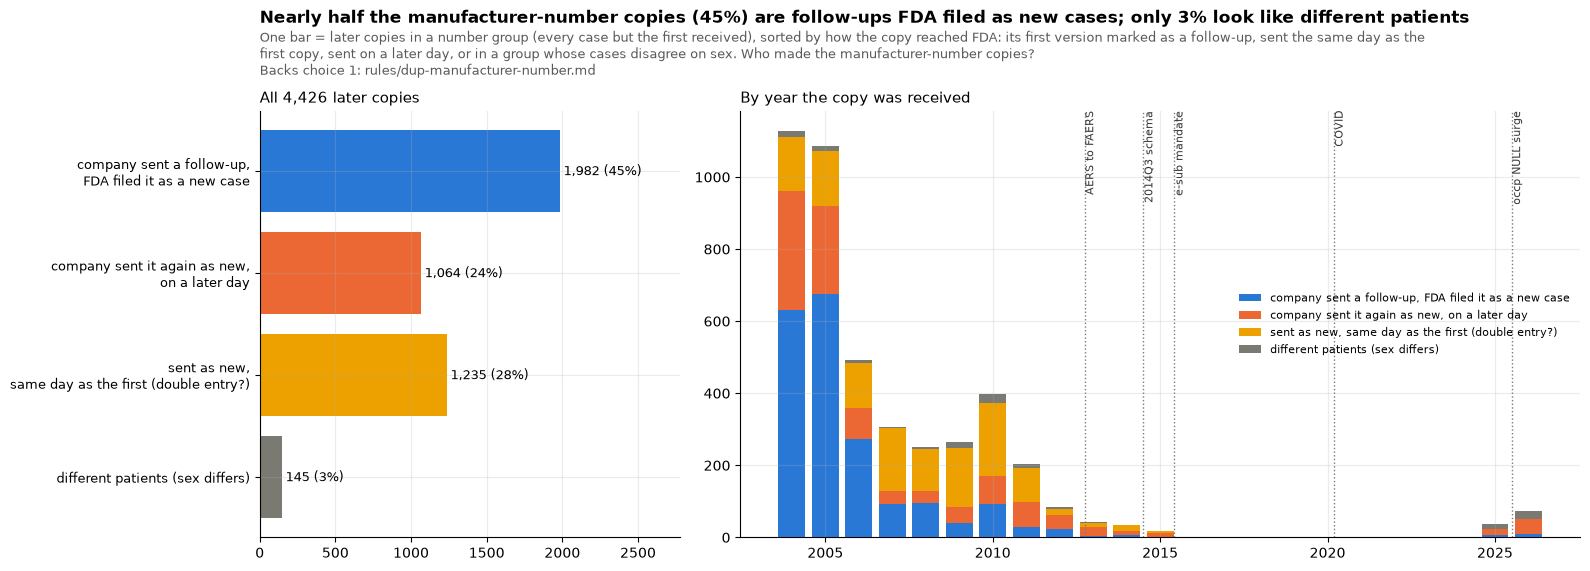

,later copies
who,
"company sent a follow-up, FDA filed it as a new case",1982
"company sent it again as new, on a later day",1064
"sent as new, same day as the first (double entry?)",1235
different patients (sex differs),145


In [11]:
who = q(f"""
WITH m AS (SELECT era_T, case_key_T, caseid, g_mfr_T, first_fda_dt_T,
             row_number() OVER (PARTITION BY g_mfr_T ORDER BY {EARLIEST}) AS rn,
             count(DISTINCT sex_mf_T) OVER (PARTITION BY g_mfr_T) AS sexes
           FROM w.case_rules_T WHERE n_mfr_T > 1),
fi AS (SELECT g_mfr_T, first_fda_dt_T AS first_dt FROM m WHERE rn = 1),
firstv AS (SELECT caseid, era_T, arg_min(i_f_code, (qnum_T, coalesce(caseversion_T, 0), primaryid)) AS first_if
           FROM demo_T WHERE caseid IN (SELECT caseid FROM m) GROUP BY 1, 2)
SELECT year(m.first_fda_dt_T) AS y,
  CASE WHEN m.sexes > 1 THEN 'different patients (sex differs)'
       WHEN f.first_if = 'F' THEN 'company sent a follow-up, FDA filed it as a new case'
       WHEN fi.first_dt = m.first_fda_dt_T THEN 'sent as new, same day as the first (double entry?)'
       ELSE 'company sent it again as new, on a later day' END AS who, count(*) AS n
FROM m JOIN fi USING (g_mfr_T) LEFT JOIN firstv f ON f.caseid = m.caseid AND f.era_T = m.era_T
WHERE m.rn > 1 GROUP BY ALL""")
order = [
    "company sent a follow-up, FDA filed it as a new case",
    "company sent it again as new, on a later day",
    "sent as new, same day as the first (double entry?)",
    "different patients (sex differs)",
]
cols = [SERIES[0], SERIES[1], SERIES[3], SERIES[6]]
tot = who.groupby("who").n.sum().reindex(order).fillna(0)
p = (
    who.pivot_table(index="y", columns="who", values="n", aggfunc="sum")
    .reindex(range(2004, 2027))
    .reindex(columns=order)
    .fillna(0)
)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [1, 2]})
b = a1.barh(range(4)[::-1], tot.values, color=cols)
for r, v in zip(b, tot.values, strict=True):
    a1.text(
        r.get_width(),
        r.get_y() + r.get_height() / 2,
        f" {int(v):,} ({100 * v / tot.sum():.0f}%)",
        va="center",
        fontsize=9,
    )
a1.set_yticks(range(4)[::-1])
a1.set_yticklabels(
    [
        o.replace(", FDA", ",\nFDA").replace(", same", ",\nsame").replace(", on", ",\non")
        for o in order
    ],
    fontsize=9,
)
a1.set_xlim(0, tot.max() * 1.4)
a1.set_title(f"All {int(tot.sum()):,} later copies", loc="left", fontsize=11)
bottom = np.zeros(len(p))
for o, c in zip(order, cols, strict=True):
    a2.bar(p.index, p[o], bottom=bottom, color=c, label=o)
    bottom += p[o].values
a2.set_title("By year the copy was received", loc="left", fontsize=11)
a2.legend(fontsize=8, frameon=False)
mark_years(a2)
sh = tot / tot.sum()
plt.tight_layout()
title(
    header(fig),
    f"Nearly half the manufacturer-number copies ({100 * sh.iloc[0]:.0f}%) are follow-ups FDA filed as new cases; "
    f"only {100 * sh.iloc[3]:.0f}% look like different patients",
    "One bar = later copies in a number group (every case but the first received), sorted by how the copy reached FDA: "
    "its first version marked as a follow-up, sent the same day as the first copy, sent on a later day, or in a group whose cases disagree on sex.",
    "Who made the manufacturer-number copies?",
    rule_line(1),
)
plt.show()
tot.astype(int).to_frame("later copies")

**Should numbers match without their country code?** Many numbers start with a two-letter country code and a hyphen (`US-PFIZER INC-2008036041`). Ignoring the code in general groups one company's local numbers from different countries; matching only where one copy lacks the code is narrower.

**Reading the chart.** Left: one bar per way of matching, the share of its groups whose cases disagree on sex, and the share whose cases all share one event date. "Number as written" is the rule above; "one copy has no code" is the narrow match the rule uses; "two codes meet" is what ignoring every code adds. Right: the groups that ignoring codes adds, by which codes meet.

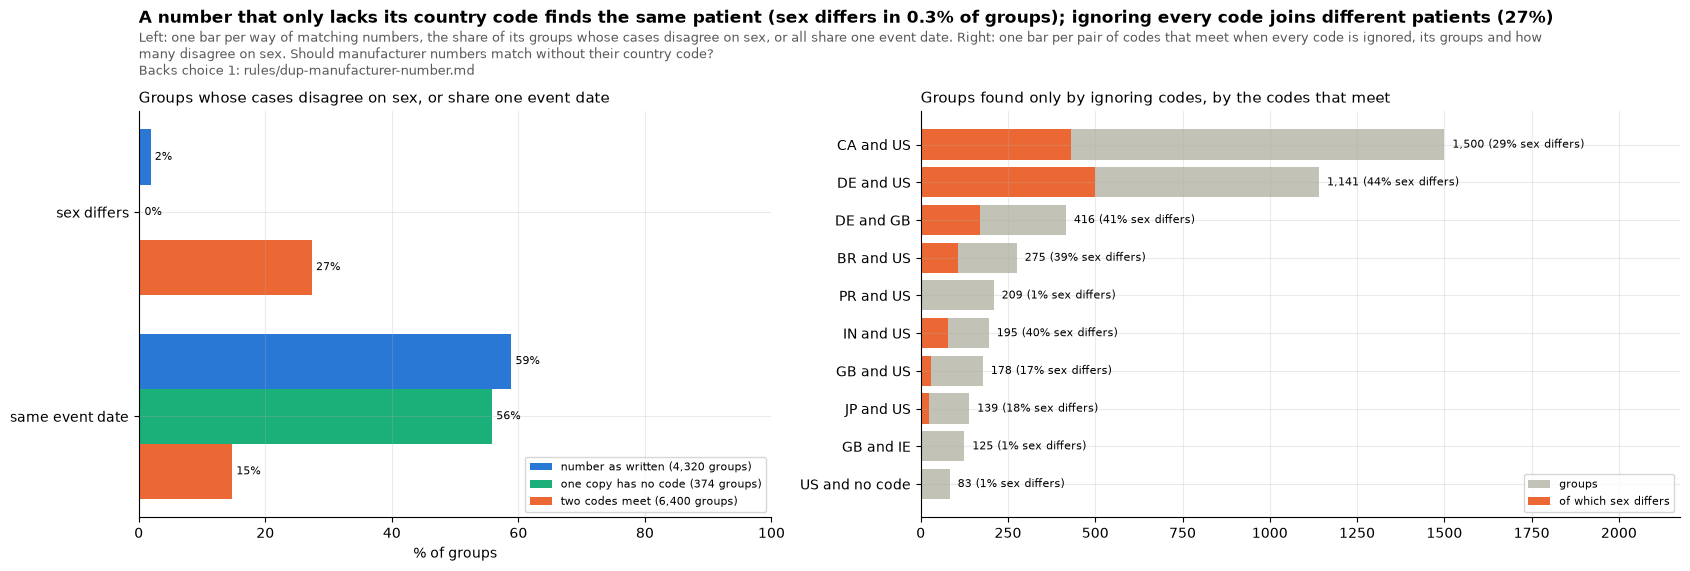

,groups_,more_set_aside,sex_differs,same_date
kind,,,,
number as written,4320,4432.0,1.9,58.9
one copy has no code,374,374.0,0.3,55.9
two codes meet,6400,7100.0,27.4,14.8


In [12]:
con.execute("""CREATE OR REPLACE TEMP TABLE code_groups_T AS
WITH n AS (SELECT sndr_up_T, num_up_T, sex_mf_T, event_dt, regexp_replace(num_up_T, '^[A-Z]{2}-', '') AS bare
           FROM w.case_rules_T WHERE sndr_up_T IS NOT NULL AND num_up_T IS NOT NULL),
same AS (SELECT sndr_up_T, num_up_T FROM n GROUP BY ALL HAVING count(*) > 1),                 -- the number as written
forms AS (SELECT sndr_up_T, bare FROM n GROUP BY ALL HAVING min(num_up_T) <> max(num_up_T))   -- one number, two forms
SELECT 'number as written' AS kind, NULL AS pair, count(*) AS n, min(sex_mf_T) <> max(sex_mf_T) AS sex_differs,
       count(event_dt) = count(*) AND min(event_dt) = max(event_dt) AS same_date
FROM n SEMI JOIN same USING (sndr_up_T, num_up_T) GROUP BY sndr_up_T, num_up_T
UNION ALL
SELECT CASE WHEN bool_or(code = 'no code') AND count(DISTINCT code) = 2 THEN 'one copy has no code' ELSE 'two codes meet' END,
       string_agg(DISTINCT code, ' and ' ORDER BY code), count(*), min(sex_mf_T) <> max(sex_mf_T),
       count(event_dt) = count(*) AND min(event_dt) = max(event_dt)
FROM (SELECT n.*, coalesce(nullif(regexp_extract(num_up_T, '^([A-Z]{2})-', 1), ''), 'no code') AS code FROM n SEMI JOIN forms USING (sndr_up_T, bare))
GROUP BY sndr_up_T, bare""")
SUMS = "count(*) AS groups_, sum(n - 1) AS more_set_aside, 100 * avg(sex_differs::INT) AS sex_differs, 100 * avg(same_date::INT) AS same_date"
kinds = (
    q(f"SELECT kind, {SUMS} FROM code_groups_T GROUP BY 1")
    .set_index("kind")
    .reindex(["number as written", "one copy has no code", "two codes meet"])
)
pairs = q(
    f"SELECT pair, {SUMS} FROM code_groups_T WHERE pair IS NOT NULL GROUP BY 1 ORDER BY 2 DESC LIMIT 10"
).iloc[::-1]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(17, 5), gridspec_kw={"width_ratios": [1, 1.2]})
y = np.arange(2)
h = 0.27
for i, (kind, r) in enumerate(kinds.iterrows()):
    label_bars(
        a1,
        a1.barh(
            y + (i - 1) * h,
            [r.sex_differs, r.same_date],
            h,
            color=[SERIES[0], SERIES[2], SERIES[1]][i],
            label=f"{kind} ({int(r.groups_):,} groups)",
        ),
        "{:.0f}%",
        horizontal=True,
    )
a1.set_yticks(y)
a1.set_yticklabels(["sex differs", "same event date"])
a1.invert_yaxis()
a1.set_xlim(0, 100)
a1.set_xlabel("% of groups")
a1.legend(fontsize=8, loc="lower right")
a1.set_title("Groups whose cases disagree on sex, or share one event date", loc="left", fontsize=11)
a2.barh(pairs.pair, pairs.groups_, color=SERIES[7], label="groups")
a2.barh(
    pairs.pair,
    pairs.groups_ * pairs.sex_differs / 100,
    color=SERIES[1],
    label="of which sex differs",
)
for yy, (_, r) in enumerate(pairs.iterrows()):
    a2.text(
        r.groups_,
        yy,
        f"  {int(r.groups_):,} ({r.sex_differs:.0f}% sex differs)",
        va="center",
        fontsize=8,
    )
a2.set_xlim(0, pairs.groups_.max() * 1.45)
a2.legend(fontsize=8, loc="lower right")
a2.set_title("Groups found only by ignoring codes, by the codes that meet", loc="left", fontsize=11)
plt.tight_layout()
title(
    header(fig),
    f"A number that only lacks its country code finds the same patient (sex differs in {kinds.loc['one copy has no code', 'sex_differs']:.1f}% of groups); "
    f"ignoring every code joins different patients ({kinds.loc['two codes meet', 'sex_differs']:.0f}%)",
    "Left: one bar per way of matching numbers, the share of its groups whose cases disagree on sex, or all share one event date. "
    "Right: one bar per pair of codes that meet when every code is ignored, its groups and how many disagree on sex.",
    "Should manufacturer numbers match without their country code?",
    rule_line(1),
)
plt.show()
kinds[["groups_", "more_set_aside", "sex_differs", "same_date"]].round(1)

### b. DiAna's rule-based match

Because an empty field matches another empty field, a case with only sex, one drug and one reaction filled matches every other such case.

**Reading the chart.** One pair of bars per number of empty fields among the five demographic ones (event date, sex, reporter country, age, weight): the cases DiAna's rule sets aside, against the AEOLUS rule. Weight is empty in most cases, so it rarely blocks a match. The table's second row tries a stricter variant: event date, sex, country and age must be filled; weight may be empty.

strict variant: cases it sets aside that the AEOLUS rule does not: 709


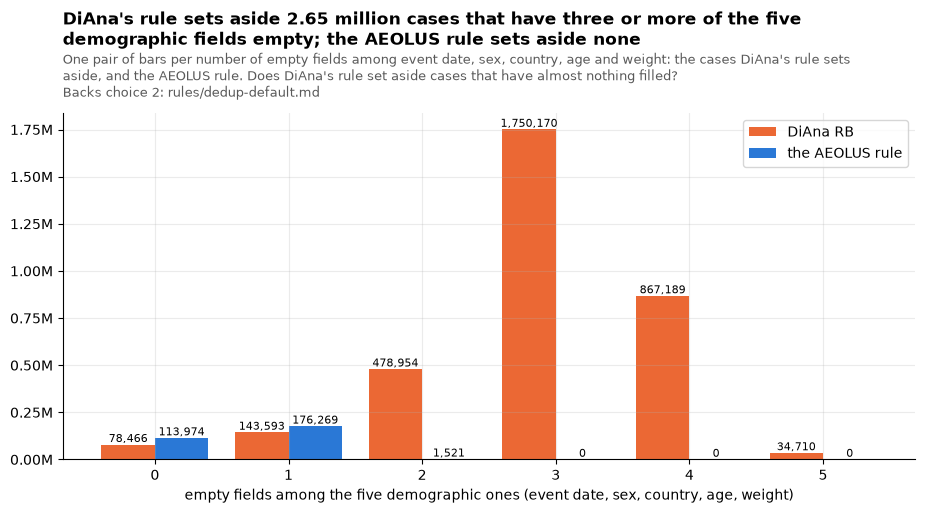

,groups,in_groups,set_aside,largest
DiAna RB as written (empty matches empty),789289,4142371,3353082,7711
"RB, but event date, sex, country and age must be filled",135798,333962,198164,30


In [13]:
NA5 = "(event_dt_diana_T IS NULL)::INT + (sex_mf_T IS NULL)::INT + (rep_country_diana_T IS NULL)::INT + (age_days_T IS NULL)::INT + (wt_kg_diana_T IS NULL)::INT"
by_na = q(f"""SELECT {NA5} AS empty_fields, count(*) AS cases, count(*) FILTER (WHERE aside_rb_T) AS rb_set_aside,
              count(*) FILTER (WHERE aside_cur_T) AS current_set_aside FROM w.case_rules_T GROUP BY 1 ORDER BY 1""")
USABLE = "n_real_drugs_T > 0 AND n_real_pts_T > 0"
STRICT = f"{USABLE} AND event_dt_diana_T IS NOT NULL AND sex_mf_T IS NOT NULL AND rep_country_diana_T IS NOT NULL AND age_days_T IS NOT NULL"
rb_new = q(f"""SELECT count(*) FILTER (WHERE aside AND NOT aside_cur_T) AS n FROM (
               SELECT aside_cur_T, row_number() OVER (PARTITION BY {", ".join(RB_FIELDS)} ORDER BY {LATEST}) > 1 AS aside FROM w.case_rules_T WHERE {STRICT})""").n[
    0
]
print(f"strict variant: cases it sets aside that the AEOLUS rule does not: {rb_new:,}")
rb_variants = pd.DataFrame(
    {
        "DiAna RB as written (empty matches empty)": measure(["g_rb_T"], table="w.case_rules_T"),
        "RB, but event date, sex, country and age must be filled": measure(
            RB_FIELDS, table="w.case_rules_T", strict=False, where=STRICT
        ),
    }
).T
fig, a1 = plt.subplots(figsize=(11, 4.5))
x = np.arange(len(by_na))
w = 0.4
label_bars(a1, a1.bar(x - w / 2, by_na.rb_set_aside, w, color=SERIES[1], label="DiAna RB"))
label_bars(
    a1, a1.bar(x + w / 2, by_na.current_set_aside, w, color=SERIES[0], label="the AEOLUS rule")
)
a1.set_xticks(x)
a1.set_xticklabels(by_na.empty_fields)
a1.set_xlabel(
    "empty fields among the five demographic ones (event date, sex, country, age, weight)"
)
a1.legend()
a1.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"{v / 1e6:.2f}M"))
n3 = by_na[by_na.empty_fields >= 3].rb_set_aside.sum()
title(
    header(fig),
    f"DiAna's rule sets aside {n3 / 1e6:.2f} million cases that have three or more of the five demographic fields empty; the AEOLUS rule sets aside none",
    "One pair of bars per number of empty fields among event date, sex, country, age and weight: the cases DiAna's rule sets aside, and the AEOLUS rule.",
    "Does DiAna's rule set aside cases that have almost nothing filled?",
    rule_line(2),
)
plt.show()
rb_variants.astype(int)

### c. AEOLUS with single imputation

**Reading the chart.** A funnel from cases missing one of event date, age, sex and country to cases newly set aside. Imputation can only borrow from another version of the same case, and most cases missing a field have no other version that has it. The axis is logarithmic: each grid step is ten times the one before, so read the printed numbers.

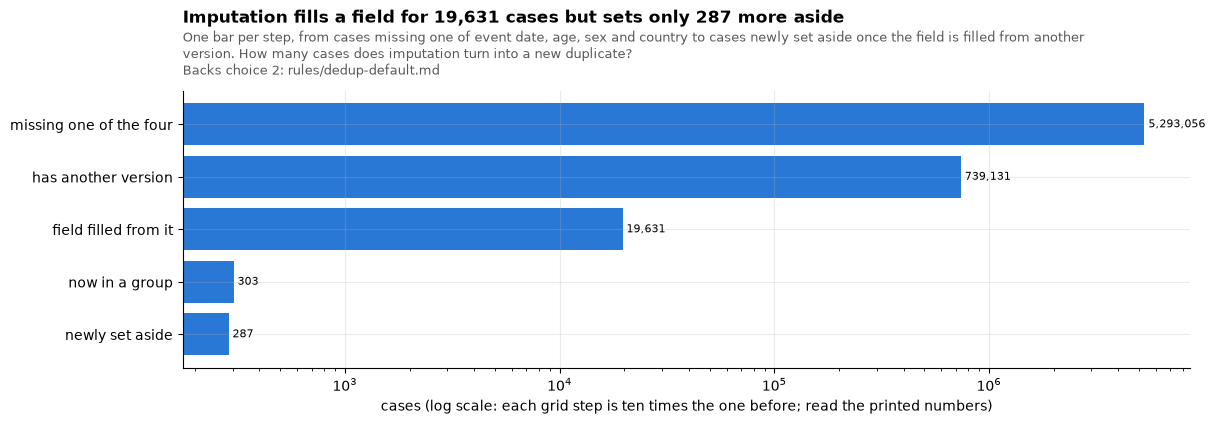

,groups,in_groups,set_aside,largest
the AEOLUS rule,185618.0,477382.0,291764.0,36.0
with imputation,185812.0,477863.0,292051.0,36.0


In [14]:
ONE4 = "(event_dt IS NULL)::INT + (age IS NULL OR age_cod IS NULL)::INT + (sex IS NULL)::INT + (country_fix_T IS NULL)::INT = 1"
imp = q(f"""WITH multi AS (SELECT caseid FROM demo_T WHERE caseid IS NOT NULL GROUP BY 1 HAVING count(*) > 1)
  SELECT count(*) FILTER (WHERE {ONE4}) AS "missing one of the four",
         count(*) FILTER (WHERE {ONE4} AND caseid IN (SELECT caseid FROM multi)) AS "has another version",
         count(*) FILTER (WHERE imputed_T) AS "field filled from it",
         count(*) FILTER (WHERE imputed_T AND n_imp_T > 1) AS "now in a group",
         count(*) FILTER (WHERE aside_imp_T AND NOT aside_cur_T) AS "newly set aside"
  FROM w.case_rules_T""").iloc[0]
fig, a1 = plt.subplots(figsize=(13, 3.6))
label_bars(a1, a1.barh(list(imp.index)[::-1], imp.values[::-1], color=SERIES[0]), horizontal=True)
a1.set_xscale("log")
a1.set_xlabel(
    "cases (log scale: each grid step is ten times the one before; read the printed numbers)"
)
title(
    header(fig),
    f"Imputation fills a field for {int(imp['field filled from it']):,} cases but sets only {int(imp['newly set aside']):,} more aside",
    "One bar per step, from cases missing one of event date, age, sex and country to cases newly set aside once the field is filled from another version.",
    "How many cases does imputation turn into a new duplicate?",
    rule_line(2),
)
plt.show()
pd.DataFrame(
    {
        "the AEOLUS rule": measure(["g_cur_T"], table="w.case_rules_T"),
        "with imputation": measure(["g_imp_T"], table="w.case_rules_T"),
    }
).T

### d. Reports with no drug or no reaction

**Reading the chart.** One bar per year FDA first received the case, split by why the report has no usable drug or reaction. Section 4 shows what these reports still carry.

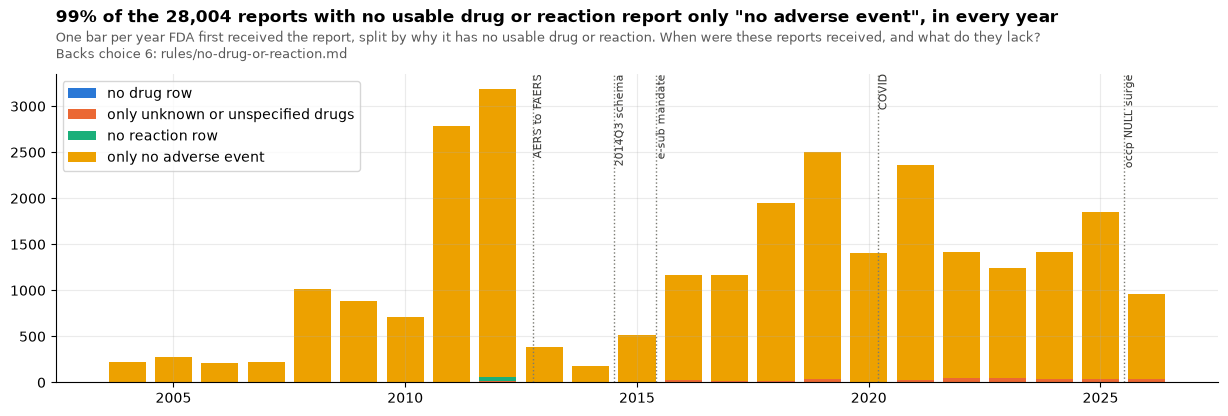

cases                      28004
also_in_an_aeolus_group       19
neither                       20
only_no_adverse_event      27620


In [15]:
nd = q("""SELECT init_year_T AS year,
  count(*) FILTER (WHERE n_drugs_T = 0) AS "no drug row",
  count(*) FILTER (WHERE n_drugs_T > 0 AND n_real_drugs_T = 0) AS "only unknown or unspecified drugs",
  count(*) FILTER (WHERE n_pts_T = 0) AS "no reaction row",
  count(*) FILTER (WHERE n_pts_T > 0 AND n_real_pts_T = 0) AS "only no adverse event"
FROM w.case_rules_T WHERE init_year_T BETWEEN 2004 AND 2026 GROUP BY 1 ORDER BY 1""").set_index(
    "year"
)
tot = q("""SELECT count(*) FILTER (WHERE empty_T) AS cases, count(*) FILTER (WHERE empty_T AND n_cur_T > 1) AS also_in_an_aeolus_group,
           count(*) FILTER (WHERE n_real_drugs_T = 0 AND n_real_pts_T = 0) AS neither,
           count(*) FILTER (WHERE empty_T AND n_pts_T > 0 AND n_real_pts_T = 0) AS only_no_adverse_event FROM w.case_rules_T""").iloc[
    0
]
fig, ax = plt.subplots(figsize=(15, 4))
bottom = np.zeros(len(nd))
for i, c in enumerate(nd.columns):
    ax.bar(nd.index, nd[c], bottom=bottom, color=SERIES[i], label=c)
    bottom += nd[c].values
ax.legend()
mark_years(ax)
title(
    header(fig),
    f'{100 * tot.only_no_adverse_event / tot.cases:.0f}% of the {int(tot.cases):,} reports with no usable drug or reaction report only "no adverse event", in every year',
    "One bar per year FDA first received the report, split by why it has no usable drug or reaction.",
    "When were these reports received, and what do they lack?",
    rule_line(6),
)
plt.show()
print(tot.to_string())

### How the rules overlap

**How to read the UpSet chart.** Each case that any rule sets aside sits in exactly one bar: the bar for the exact set of rules that set it aside, shown by the dots under it (a line joins the dots when several rules agree). So the first bar is the cases only DiAna's rule sets aside, not DiAna's total. The grey bars on the left are each rule's total, and the table at the top left gives the same totals plainly, with how many each rule shares with the AEOLUS rule and how many only it sets aside. The bar heights are on a log scale: each step up is ten times the one below, so read the printed numbers.

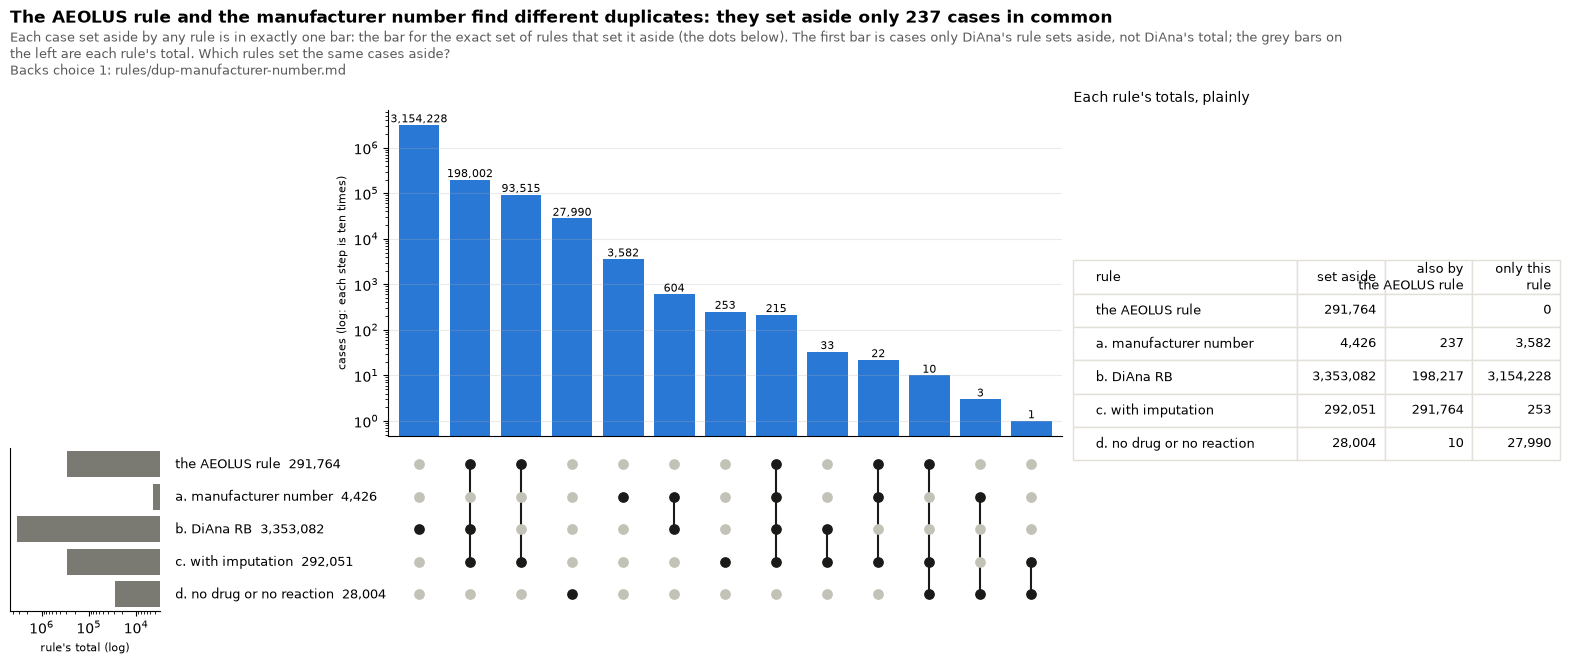

,set aside,also by the AEOLUS rule,only this rule
rule,,,
the AEOLUS rule,291764,NaN,0
a. manufacturer number,4426,237.0,3582
b. DiAna RB,3353082,198217.0,3154228
c. with imputation,292051,291764.0,253
d. no drug or no reaction,28004,10.0,27990


In [16]:
SETS = {
    "the AEOLUS rule": "aside_cur_T",
    "a. manufacturer number": "aside_mfr_T",
    "b. DiAna RB": "aside_rb_T",
    "c. with imputation": "aside_imp_T",
    "d. no drug or no reaction": "empty_T",
}
ov = q(f"""SELECT {", ".join(f'{c} AS "{s}"' for s, c in SETS.items())}, count(*) AS n FROM w.case_rules_T
           WHERE {" OR ".join(SETS.values())} GROUP BY ALL ORDER BY n DESC""")
per_rule = pd.DataFrame(
    [
        {
            "rule": s,
            "set aside": int(ov.loc[ov[s], "n"].sum()),
            "also by the AEOLUS rule": int(ov.loc[ov[s] & ov["the AEOLUS rule"], "n"].sum())
            if s != "the AEOLUS rule"
            else np.nan,
            "only this rule": int(ov.loc[ov[s] & (ov[list(SETS)].sum(axis=1) == 1), "n"].sum()),
        }
        for s in SETS
    ]
).set_index("rule")


def upset(c, sets, claim):
    """UpSet chart: one bar per combination of sets (log), membership dots below, each set's total on the left, a plain table top left."""
    fig = plt.figure(figsize=(20, 6.5))
    g = fig.add_gridspec(
        2, 4, height_ratios=[3, 1.5], width_ratios=[0.8, 1.1, 3.6, 2.6], hspace=0.05, wspace=0.03
    )
    top, dots, names, side, tab = (
        fig.add_subplot(g[0, 2]),
        fig.add_subplot(g[1, 2]),
        fig.add_subplot(g[1, 1]),
        fig.add_subplot(g[1, 0]),
        fig.add_subplot(g[:, 3]),
    )
    x = np.arange(len(c))
    top.bar(x, c.n, color=SERIES[0])
    top.set_yscale("log")
    top.set_xlim(-0.6, len(c) - 0.4)
    top.set_xticks([])
    top.set_ylabel("cases (log: each step is ten times)", fontsize=8)
    for xi, n in zip(x, c.n, strict=True):
        top.text(xi, n, f"{n:,}", ha="center", va="bottom", fontsize=8)
    for yi, s in enumerate(sets):
        on = c[s].values.astype(bool)
        dots.scatter(x[on], [yi] * on.sum(), color="#1a1a19", s=45, zorder=3)
        dots.scatter(x[~on], [yi] * (~on).sum(), color=SERIES[7], s=45, zorder=3)
    for xi, (_, row) in zip(x, c.iterrows(), strict=True):
        ys = [yi for yi, s in enumerate(sets) if row[s]]
        if len(ys) > 1:
            dots.plot([xi, xi], [min(ys), max(ys)], color="#1a1a19", lw=1.5, zorder=2)
    totals = [int(c.loc[c[s], "n"].sum()) for s in sets]
    for ax in (dots, names, side):
        ax.set_ylim(len(sets) - 0.5, -0.5)
        ax.grid(False)
    dots.set_xlim(top.get_xlim())
    dots.axis("off")
    names.axis("off")
    for yi, (s, t_) in enumerate(zip(sets, totals, strict=True)):
        names.text(0.02, yi, f"{s}  {t_:,}", va="center", fontsize=9)
    side.barh(range(len(sets)), totals, color=SERIES[6])
    side.set_xscale("log")
    side.invert_xaxis()
    side.set_yticks([])
    side.set_xlabel("rule's total (log)", fontsize=8)
    tab.axis("off")
    also = "also by the AEOLUS rule"
    cells = [
        [
            r,
            f"{int(v['set aside']):,}",
            "" if pd.isna(v[also]) else f"{int(v[also]):,}",
            f"{int(v['only this rule']):,}",
        ]
        for r, v in per_rule.iterrows()
    ]
    tb = tab.table(
        cellText=cells,
        colLabels=["rule", "set aside", "also by\nthe AEOLUS rule", "only this\nrule"],
        loc="center",
        cellLoc="right",
        colLoc="right",
        colWidths=[0.46, 0.18, 0.18, 0.18],
    )
    tb.auto_set_font_size(False)
    tb.set_fontsize(9)
    tb.scale(1, 2.0)
    tab.set_title("Each rule's totals, plainly", loc="left", fontsize=10)
    for (_, c_), cell in tb.get_celld().items():
        cell.set_edgecolor("#e1e0d9")
        cell.set_text_props(ha="left" if c_ == 0 else "right")
    title(
        header(fig),
        claim,
        "Each case set aside by any rule is in exactly one bar: the bar for the exact set of rules that set it aside (the dots below). "
        "The first bar is cases only DiAna's rule sets aside, not DiAna's total; the grey bars on the left are each rule's total.",
        "Which rules set the same cases aside?",
        rule_line(1),
    )
    plt.show()


upset(
    ov,
    list(SETS),
    f"The AEOLUS rule and the manufacturer number find different duplicates: they set aside only "
    f"{int(per_rule.loc['a. manufacturer number', 'also by the AEOLUS rule']):,} cases in common",
)
per_rule

### How big are the groups?

**Reading the chart.** One pair of bars per group size, for the AEOLUS rule and the manufacturer number: blue is the share of the rule's groups that have that many cases, green the share of the cases in its groups that sit in groups that size. The grey number under each pair is the count of groups.

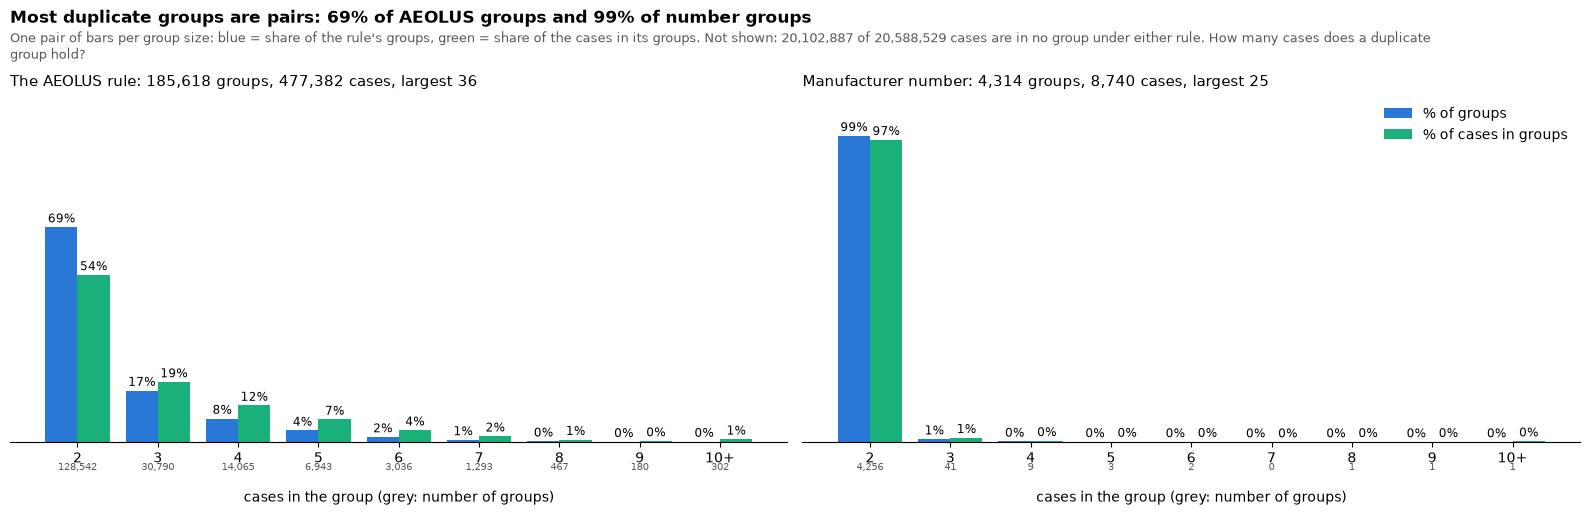

In [17]:
alone = q(
    "SELECT count(*) FILTER (WHERE coalesce(n_cur_T, 1) = 1 AND coalesce(n_mfr_T, 1) = 1) AS alone, count(*) AS cases FROM w.case_rules_T"
).iloc[0]
fig, axes = plt.subplots(1, 2, figsize=(16, 4.6), sharey=True)
pairs_share = {}
for ax, (r, name) in zip(
    axes, [("cur", "The AEOLUS rule"), ("mfr", "Manufacturer number")], strict=True
):
    d = q(
        f"SELECT n, count(*) AS g FROM (SELECT g_{r}_T, count(*) AS n FROM w.case_rules_T WHERE n_{r}_T > 1 GROUP BY 1) GROUP BY 1"
    )
    d["cases"] = d.n * d.g
    d["bin"] = d.n.where(d.n < 10, 10)
    b = d.groupby("bin")[["g", "cases"]].sum().reindex(range(2, 11), fill_value=0)
    b["pg"] = 100 * b.g / b.g.sum()
    b["pc"] = 100 * b.cases / b.cases.sum()
    pairs_share[r] = b.pg.loc[2]
    xx = range(len(b))
    w = 0.4
    ax.bar([i - w / 2 for i in xx], b.pg, w, color=BLUE, label="% of groups")
    ax.bar([i + w / 2 for i in xx], b.pc, w, color=GREEN, label="% of cases in groups")
    for i, (g_, cs, ng) in enumerate(zip(b.pg, b.pc, b.g, strict=True)):
        ax.text(i - w / 2, g_ + 1.5, f"{g_:.0f}%", ha="center", fontsize=8.5)
        ax.text(i + w / 2, cs + 1.5, f"{cs:.0f}%", ha="center", fontsize=8.5)
        ax.text(i, -9, f"{int(ng):,}", ha="center", fontsize=7.5, color=MUTED)
    ax.set_xticks(list(xx))
    ax.set_xticklabels([str(i) if i < 10 else "10+" for i in b.index])
    ax.set_xlabel("cases in the group (grey: number of groups)", labelpad=18)
    ax.set_title(
        f"{name}: {int(b.g.sum()):,} groups, {int(b.cases.sum()):,} cases, largest {int(d.n.max())}",
        loc="left",
        fontsize=10.5,
    )
    ax.set_ylim(0, 112)
    ax.set_yticks([])
    ax.spines["left"].set_visible(False)
    ax.grid(False)
axes[1].legend(frameon=False, loc="upper right")
plt.tight_layout()
title(
    header(fig),
    f"Most duplicate groups are pairs: {pairs_share['cur']:.0f}% of AEOLUS groups and {pairs_share['mfr']:.0f}% of number groups",
    f"One pair of bars per group size: blue = share of the rule's groups, green = share of the cases in its groups. "
    f"Not shown: {int(alone.alone):,} of {int(alone.cases):,} cases are in no group under either rule.",
    "How many cases does a duplicate group hold?",
)
plt.show()

**What section 2 shows.** 
- **Manufacturer number** finds few duplicates, and they look real. As FDA wrote it, 4,314 groups and 4,426 cases set aside, mostly copies received 2004 to 2011. 45% of the later copies are follow-ups FDA filed as new cases, 24% a company sending the report again on a later day, 28% a second entry on the same day; 3% sit in the 79 groups whose cases disagree on sex: one number reused for different patients, such as one maker's labeller code, 54973, with 25 patients under it, aged from 2 months to 79 years. Direct reports (1.08 million) carry no number and are never compared.
- **Country codes.** Where one copy simply lacks the code the other has, the 374 groups look like one patient: sex differs in 0.3%, as with the number as written (1.9%). Ignoring every code adds 6,400 groups that mostly join one company's local numbers from two countries (Canada and the US 1,500 groups, Germany and the US 1,141), and sex differs in 27% of them.
- **DiAna's rule as written** sets aside 3,353,082 cases (16%), and its largest group holds 7,711. Of those set aside, 2.65 million have three or more of the five demographic fields empty: "empty matches empty" turns a common drug and reaction pair into one group. Requiring event date, sex, country and age cuts it to 198,164, only 709 beyond what the AEOLUS rule already sets aside.
- **Imputation** fills a field for 19,631 cases but puts only 303 of them in a group, setting aside 287 more. Most cases missing a field have no other version to borrow from.
- **No drug or no reaction**: 28,004 cases, 27,620 of them reporting only "no adverse event". They are not duplicates.
- **Overlap.** DiAna's rule also sets aside 198,217 (68%) of the AEOLUS rule's 291,764. The manufacturer number overlaps the AEOLUS rule in only 237 cases and sets 3,582 aside that no other rule does: the two find different duplicates.
- **Group sizes.** 69% of AEOLUS groups are pairs and the largest holds 36 cases; 99% of number groups are pairs, the largest 25.

## 3. Which copy is shown

Within a group, which case stays visible? The check in section 1 keeps the **earliest received**; the release read here shows the latest. DiAna keeps the **latest received**; AEOLUS the highest primaryid. Choice 3: show the **latest received**, one order for every rule, and date the whole group by its **earliest receipt** (`group_first_dt_T`), so the event keeps its original timing while users see the fullest copy. This mirrors FAERS itself: the latest version of a case is shown, dated by its first receipt.

**Reading the chart.** One bar per field, across all of a rule's groups: each group's earliest received copy is compared with its latest received copy, and the bar splits the groups by which carries more (patient fields filled of five, drugs, reactions).

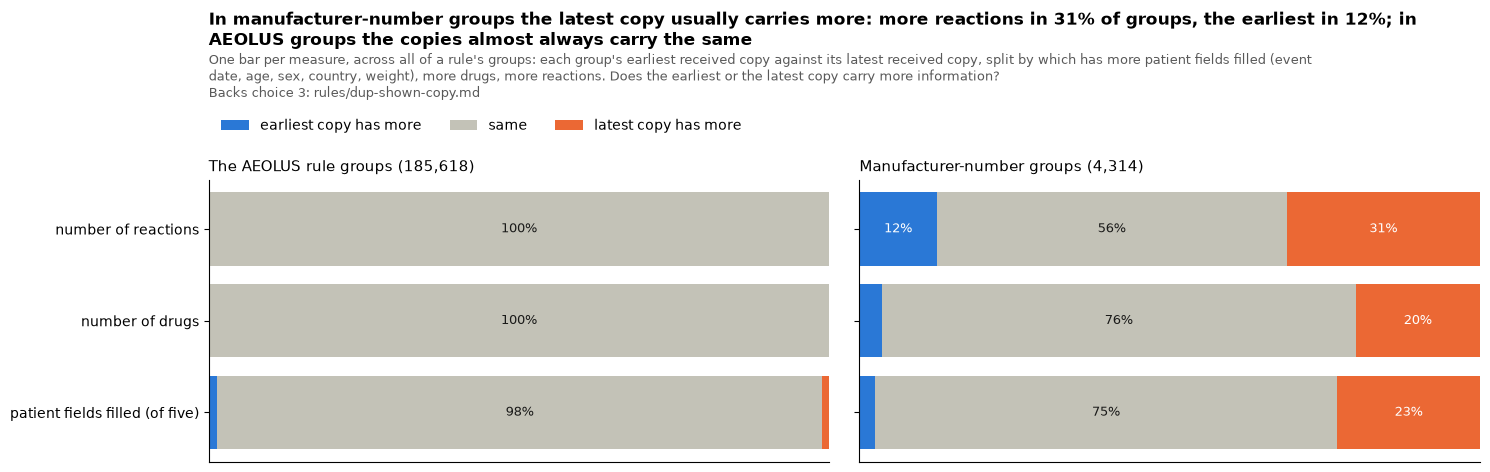

In [18]:
DEMO5 = "(event_dt IS NOT NULL)::INT + (age IS NOT NULL)::INT + (sex_mf_T IS NOT NULL)::INT + (country_fix_T IS NOT NULL)::INT + (wt_kg_diana_T IS NOT NULL)::INT"
info = []
for r, name in [("cur", "The AEOLUS rule groups"), ("mfr", "Manufacturer-number groups")]:
    info.append(
        q(f"""WITH x AS (
      SELECT g_{r}_T AS g, {DEMO5} AS demo, n_real_drugs_T AS drugs, n_real_pts_T AS pts,
             row_number() OVER (PARTITION BY g_{r}_T ORDER BY {EARLIEST}) AS e, row_number() OVER (PARTITION BY g_{r}_T ORDER BY {LATEST}) AS l
      FROM w.case_rules_T WHERE n_{r}_T > 1),
    p AS (SELECT a.demo AS ed, b.demo AS ld, a.drugs AS edr, b.drugs AS ldr, a.pts AS ep, b.pts AS lp FROM x a JOIN x b ON a.g = b.g AND a.e = 1 AND b.l = 1)
    SELECT k, 100 * avg((e > l)::INT) AS "earliest copy has more", 100 * avg((e = l)::INT) AS "same",
           100 * avg((e < l)::INT) AS "latest copy has more", count(*) AS groups_ FROM (
      SELECT 'patient fields filled (of five)' AS k, ed AS e, ld AS l FROM p UNION ALL
      SELECT 'number of drugs', edr, ldr FROM p UNION ALL SELECT 'number of reactions', ep, lp FROM p) GROUP BY ALL""").assign(
            grp=name
        )
    )
info = pd.concat(info)
ks = ["patient fields filled (of five)", "number of drugs", "number of reactions"]
cols = {"earliest copy has more": BLUE, "same": GREY, "latest copy has more": ORANGE}
fig, axes = plt.subplots(1, 2, figsize=(15, 3.8), sharey=True)
for ax, grp in zip(axes, ["The AEOLUS rule groups", "Manufacturer-number groups"], strict=True):
    s = info[info.grp == grp].set_index("k").loc[ks]
    left = np.zeros(3)
    for c, colr in cols.items():
        ax.barh(range(3), s[c], left=left, color=colr, label=c)
        for i, v in enumerate(s[c]):
            if v >= 6:
                ax.text(
                    left[i] + v / 2,
                    i,
                    f"{v:.0f}%",
                    ha="center",
                    va="center",
                    color="white" if c != "same" else INK,
                    fontsize=9,
                )
        left += s[c].values
    ax.set_title(f"{grp} ({int(s.groups_.iloc[0]):,})", loc="left", fontsize=10.5)
    ax.set_yticks(range(3))
    ax.set_yticklabels(ks)
    ax.invert_yaxis()
    ax.set_xlim(0, 100)
    ax.set_xticks([])
    ax.grid(False)
axes[0].legend(ncol=3, loc="lower left", bbox_to_anchor=(0, 1.12), frameon=False)
mr = info[(info.grp == "Manufacturer-number groups") & (info.k == "number of reactions")].iloc[0]
plt.tight_layout()
title(
    header(fig),
    f"In manufacturer-number groups the latest copy usually carries more: more reactions in {mr['latest copy has more']:.0f}% of groups, "
    f"the earliest in {mr['earliest copy has more']:.0f}%; in AEOLUS groups the copies almost always carry the same",
    "One bar per measure, across all of a rule's groups: each group's earliest received copy against its latest received copy, "
    "split by which has more patient fields filled (event date, age, sex, country, weight), more drugs, more reactions.",
    "Does the earliest or the latest copy carry more information?",
    rule_line(3),
)
plt.show()

**Reading the chart.** One bar per rule, its groups split by how many years separate the latest copy's own first receipt from the group's earliest. If the shown copy were dated by its own receipt, the event would move by that much in every year count; the group date stops that.

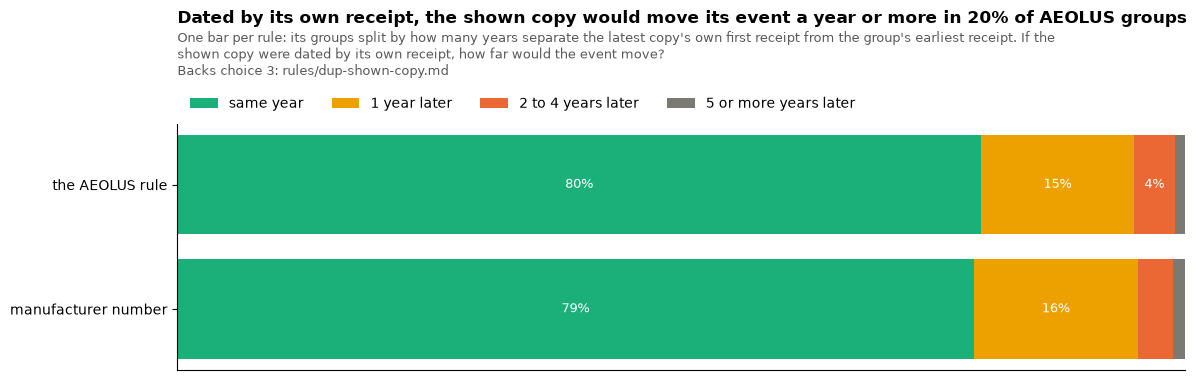

,groups_,same year,1 year later,2 to 4 years later,5 or more years later
rule,,,,,
manufacturer number,4314,79.0,16.3,3.5,1.2
the AEOLUS rule,185618,79.7,15.2,4.0,1.0


In [19]:
mv = q(f"""
WITH g AS (
  SELECT 'the AEOLUS rule' AS rule, g_cur_T AS g, * FROM w.case_rules_T WHERE n_cur_T > 1
  UNION ALL BY NAME SELECT 'manufacturer number' AS rule, g_mfr_T AS g, * FROM w.case_rules_T WHERE n_mfr_T > 1),
r AS (SELECT rule, g, case_key_T, year(first_fda_dt_T) AS y,
        row_number() OVER (PARTITION BY rule, g ORDER BY {EARLIEST}) AS e, row_number() OVER (PARTITION BY rule, g ORDER BY {LATEST}) AS l FROM g),
p AS (SELECT rule, g, max(y) FILTER (WHERE l = 1) - min(y) AS shift FROM r GROUP BY ALL)
SELECT rule, count(*) AS groups_,
  100 * avg((shift = 0)::INT) AS "same year", 100 * avg((shift = 1)::INT) AS "1 year later",
  100 * avg((shift BETWEEN 2 AND 4)::INT) AS "2 to 4 years later", 100 * avg((shift >= 5)::INT) AS "5 or more years later"
FROM p GROUP BY 1 ORDER BY 1""").set_index("rule")
shift = mv[["same year", "1 year later", "2 to 4 years later", "5 or more years later"]]
fig, ax = plt.subplots(figsize=(13, 3.2))
left = np.zeros(len(shift))
for i, c in enumerate(shift.columns):
    ax.barh(
        shift.index, shift[c], left=left, color=[GREEN, SERIES[3], ORANGE, SERIES[6]][i], label=c
    )
    for yy, v in enumerate(shift[c]):
        if v >= 4:
            ax.text(
                left[yy] + v / 2,
                yy,
                f"{v:.0f}%",
                ha="center",
                va="center",
                fontsize=9,
                color="white",
            )
    left += shift[c].values
ax.set_xlim(0, 100)
ax.set_xticks([])
ax.grid(False)
ax.legend(ncol=4, loc="lower left", bbox_to_anchor=(0, 1.0), frameon=False)
title(
    header(fig),
    f"Dated by its own receipt, the shown copy would move its event a year or more in {100 - shift.loc['the AEOLUS rule', 'same year']:.0f}% of AEOLUS groups",
    "One bar per rule: its groups split by how many years separate the latest copy's own first receipt from the group's earliest receipt.",
    "If the shown copy were dated by its own receipt, how far would the event move?",
    rule_line(3),
)
plt.show()
mv.round(1)

## 4. Do the cases inside a group agree?

Counts prove; examples illustrate. This section first compares every group each rule makes, then shows examples of each kind.

**Reading the chart.** One bar is one field, across all of a rule's groups. A group's cases are compared only with each other, field by field: green, they all have the same value; orange, two filled values differ; dark grey, one case is blank and the filled ones agree; light grey, the field is blank in every case of the group.

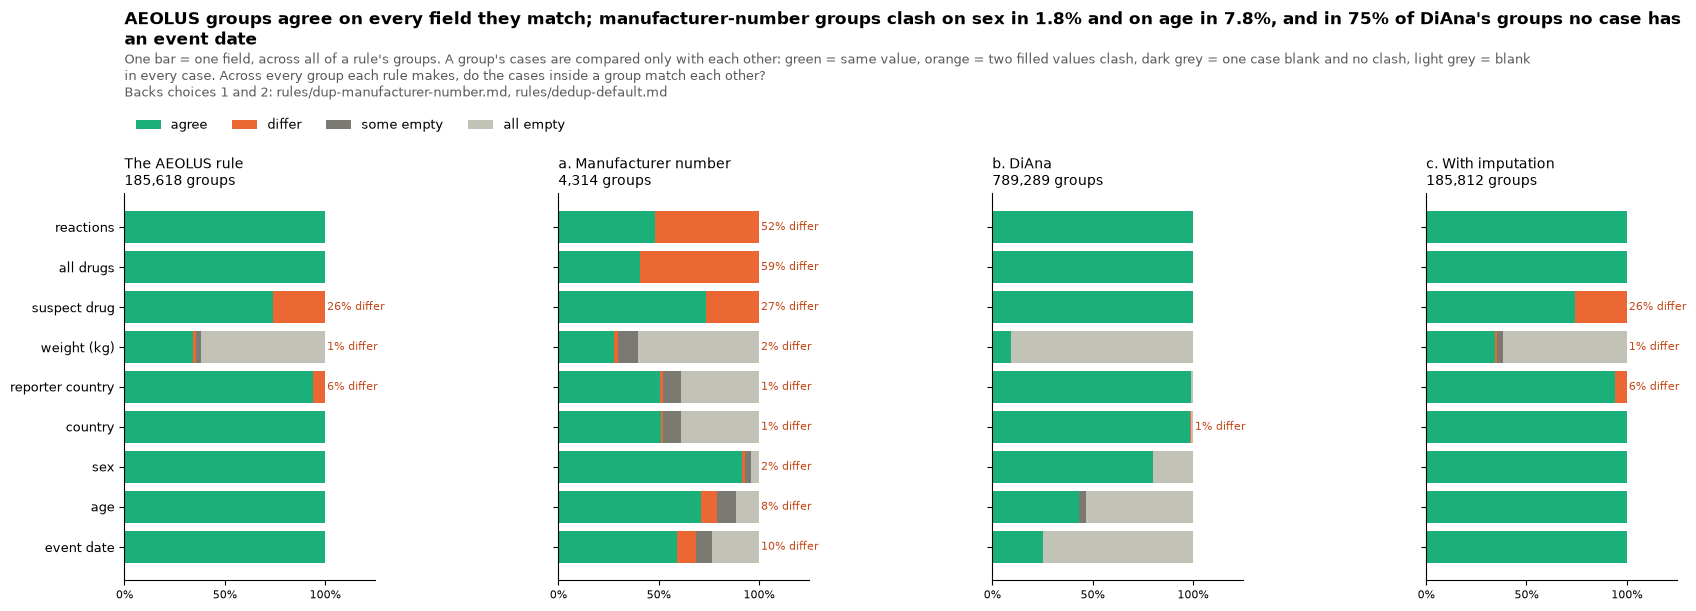

DiAna's groups with the field blank in every case: event date 74.7%, weight (kg) 90.5%, age 53.2%, sex 20.1%


state                                    agree  differ  some empty  all empty
rule                   field                                                 
The AEOLUS rule        event date        100.0     0.0         0.0        0.0
                       age               100.0     0.0         0.0        0.0
                       sex               100.0     0.0         0.0        0.0
                       country           100.0     0.0         0.0        0.0
                       reporter country   93.9     6.1         0.0        0.0
                       weight (kg)        34.2     1.3         2.8       61.7
                       suspect drug       74.0    26.0         0.0        0.0
                       all drugs         100.0     0.0         0.0        0.0
                       reactions         100.0     0.0         0.0        0.0
a. Manufacturer number event date         58.9     9.8         8.1       23.2
                       age                71.3     7.8         9.2       11.7
                       sex                91.4     1.8         2.7        4.0
                       country            51.3     0.7         9.3       38.8
                       reporter country   50.8     1.5         9.0       38.7
                       weight (kg)        27.9     2.0         9.6       60.5
                       suspect drug       73.4    26.6         0.0        0.0
                       all drugs          40.7    59.3         0.0        0.0
                       reactions          48.1    51.9         0.0        0.0

In [20]:
F = {
    "event date": "event_dt",
    "age": "nullif(concat_ws(' ', age, age_cod), '')",
    "sex": "sex_mf_T",
    "country": "country_fix_T",
    "reporter country": "reporter_country_fix_T",
    "weight (kg)": "round(wt_kg_diana_T)",
    "suspect drug": "ps_h_T",
    "all drugs": "drugs_h_T",
    "reactions": "pts_up_h_T",
}
AG_RULES = {
    "cur": "The AEOLUS rule",
    "mfr": "a. Manufacturer number",
    "rb": "b. DiAna",
    "imp": "c. With imputation",
}
rows = []
for r, name in AG_RULES.items():
    parts = [
        f"""count(*) FILTER (WHERE nd_{i} > 1) AS "{f}|differ", count(*) FILTER (WHERE nd_{i} <= 1 AND nn_{i} = n) AS "{f}|agree",
                 count(*) FILTER (WHERE nd_{i} <= 1 AND nn_{i} BETWEEN 1 AND n - 1) AS "{f}|some empty", count(*) FILTER (WHERE nn_{i} = 0) AS "{f}|all empty" """
        for i, f in enumerate(F)
    ]
    inner = ", ".join(
        f"count(DISTINCT {x}) AS nd_{i}, count({x}) AS nn_{i}" for i, x in enumerate(F.values())
    )
    s = q(f"""SELECT count(*) AS groups_, {", ".join(parts)} FROM (
        SELECT g_{r}_T, count(*) AS n, {inner} FROM w.case_rules_T WHERE n_{r}_T > 1 GROUP BY 1)""").iloc[
        0
    ]
    for f in F:
        for st_ in ["agree", "differ", "some empty", "all empty"]:
            rows.append((name, int(s.groups_), f, st_, 100 * s[f"{f}|{st_}"] / s.groups_))
ag = pd.DataFrame(rows, columns=["rule", "groups", "field", "state", "pct"])
COL = {"agree": GREEN, "differ": ORANGE, "some empty": SERIES[6], "all empty": GREY}
fig, axes = plt.subplots(1, 4, figsize=(17, 5.2), sharey=True)
for ax, name in zip(axes, AG_RULES.values(), strict=True):
    d = ag[ag.rule == name].pivot_table(index="field", columns="state", values="pct", sort=False)[
        list(COL)
    ]
    left = np.zeros(len(d))
    for st_, c in COL.items():
        ax.barh(range(len(d)), d[st_], left=left, color=c, label=st_)
        left += d[st_].values
    for i, v in enumerate(d["differ"]):
        if v >= 0.5:
            ax.text(101, i, f"{v:.0f}% differ", va="center", fontsize=8, color="#c2491b")
    ax.set_title(
        f"{name}\n{int(ag[ag.rule == name].groups.iloc[0]):,} groups", fontsize=10, loc="left"
    )
    ax.set_yticks(range(len(d)))
    ax.set_yticklabels(d.index, fontsize=9)
    ax.invert_yaxis()
    ax.grid(False)
    ax.set_xlim(0, 125)
    ax.set_xticks([0, 50, 100])
    ax.set_xticklabels(["0%", "50%", "100%"], fontsize=8)
axes[0].legend(ncol=4, loc="lower left", bbox_to_anchor=(0, 1.13), frameon=False, fontsize=9)


def cell(rule, field, state):
    return ag[(ag.rule == rule) & (ag.field == field) & (ag.state == state)].pct.iloc[0]


plt.tight_layout()
title(
    header(fig),
    f"AEOLUS groups agree on every field they match; manufacturer-number groups clash on sex in "
    f"{cell('a. Manufacturer number', 'sex', 'differ'):.1f}% and on age in {cell('a. Manufacturer number', 'age', 'differ'):.1f}%, "
    f"and in {cell('b. DiAna', 'event date', 'all empty'):.0f}% of DiAna's groups no case has an event date",
    "One bar = one field, across all of a rule's groups. A group's cases are compared only with each other: green = same value, "
    "orange = two filled values clash, dark grey = one case blank and no clash, light grey = blank in every case.",
    "Across every group each rule makes, do the cases inside a group match each other?",
    rule_line((1, 2)),
)
plt.show()
blank = ag[(ag.rule == "b. DiAna") & (ag.state == "all empty")].set_index("field").pct
print(
    "DiAna's groups with the field blank in every case: "
    + ", ".join(f"{f} {blank[f]:.1f}%" for f in ["event date", "weight (kg)", "age", "sex"])
)
ag.pivot_table(index=["rule", "field"], columns="state", values="pct", sort=False).round(1).loc[
    ["The AEOLUS rule", "a. Manufacturer number"]
]

**Different suspect drugs in AEOLUS groups.** The AEOLUS rule matches the whole drug set, so a group can still differ on which drug each copy names as the suspect. **Reading the chart.** One bar per kind of group (the copies name the same suspect drug, or not), split by whether the copies came from different senders (two companies, or a company and a direct report) or one sender.

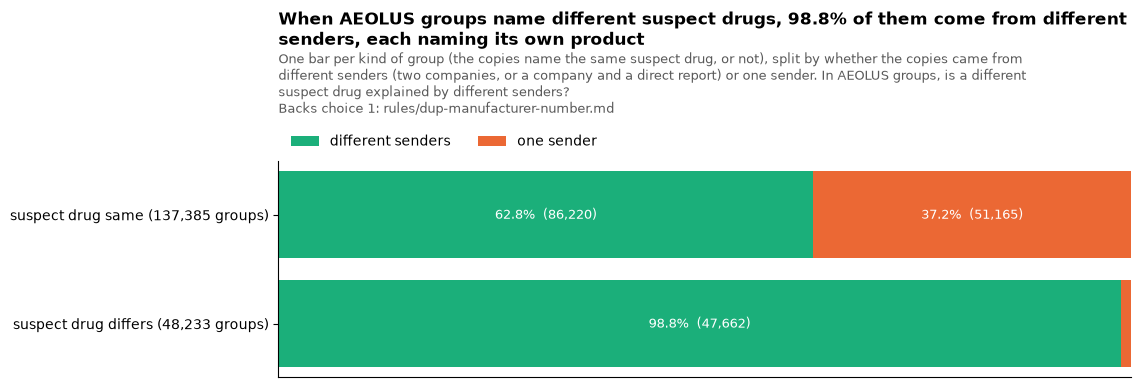

senders,different senders,one sender
ps,,
suspect drug differs,47662,571
suspect drug same,86220,51165


In [21]:
cl = q("""SELECT CASE WHEN count(DISTINCT ps_h_T) > 1 THEN 'suspect drug differs' ELSE 'suspect drug same' END AS ps,
   CASE WHEN count(DISTINCT coalesce(mfr_sndr, 'FDA direct')) > 1 OR bool_or(sender_type_T = 'direct to FDA') AND bool_or(sender_type_T LIKE 'manufacturer%')
        THEN 'different senders' ELSE 'one sender' END AS senders
   FROM w.case_rules_T WHERE n_cur_T > 1 GROUP BY g_cur_T""")
t_ = cl.groupby(["ps", "senders"]).size().unstack(fill_value=0)
p = 100 * t_.div(t_.sum(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(11, 2.8))
for i, row in enumerate(p.index):
    left = 0
    for s, c in {"different senders": GREEN, "one sender": ORANGE}.items():
        v = p.loc[row, s]
        ax.barh(i, v, left=left, color=c, label=s if i == 0 else None)
        if v >= 4:
            ax.text(
                left + v / 2,
                i,
                f"{v:.1f}%  ({int(t_.loc[row, s]):,})",
                ha="center",
                va="center",
                color="white",
                fontsize=9,
            )
        left += v
ax.set_yticks(range(len(p)))
ax.set_yticklabels([f"{r} ({int(t_.loc[r].sum()):,} groups)" for r in p.index])
ax.set_xlim(0, 100)
ax.set_xticks([])
ax.grid(False)
ax.legend(ncol=2, loc="lower left", bbox_to_anchor=(0, 1.0), frameon=False)
title(
    header(fig),
    f"When AEOLUS groups name different suspect drugs, {p.loc['suspect drug differs', 'different senders']:.1f}% of them come from different senders, "
    "each naming its own product",
    "One bar per kind of group (the copies name the same suspect drug, or not), split by whether the copies came from different senders "
    "(two companies, or a company and a direct report) or one sender.",
    "In AEOLUS groups, is a different suspect drug explained by different senders?",
    rule_line(1),
)
plt.show()
t_

**Sex values and switches over time.** The guards of choice 1 rest on how rarely a case's own follow-ups switch sex. **Reading the chart.** Left: one bar per year, every version FDA received that year, split by the sex value as FDA publishes it. Right: one bar per year, how many follow-ups (FAERS versions 2 or later) switched sex between male and female, per 10,000 follow-ups; the label is the count.

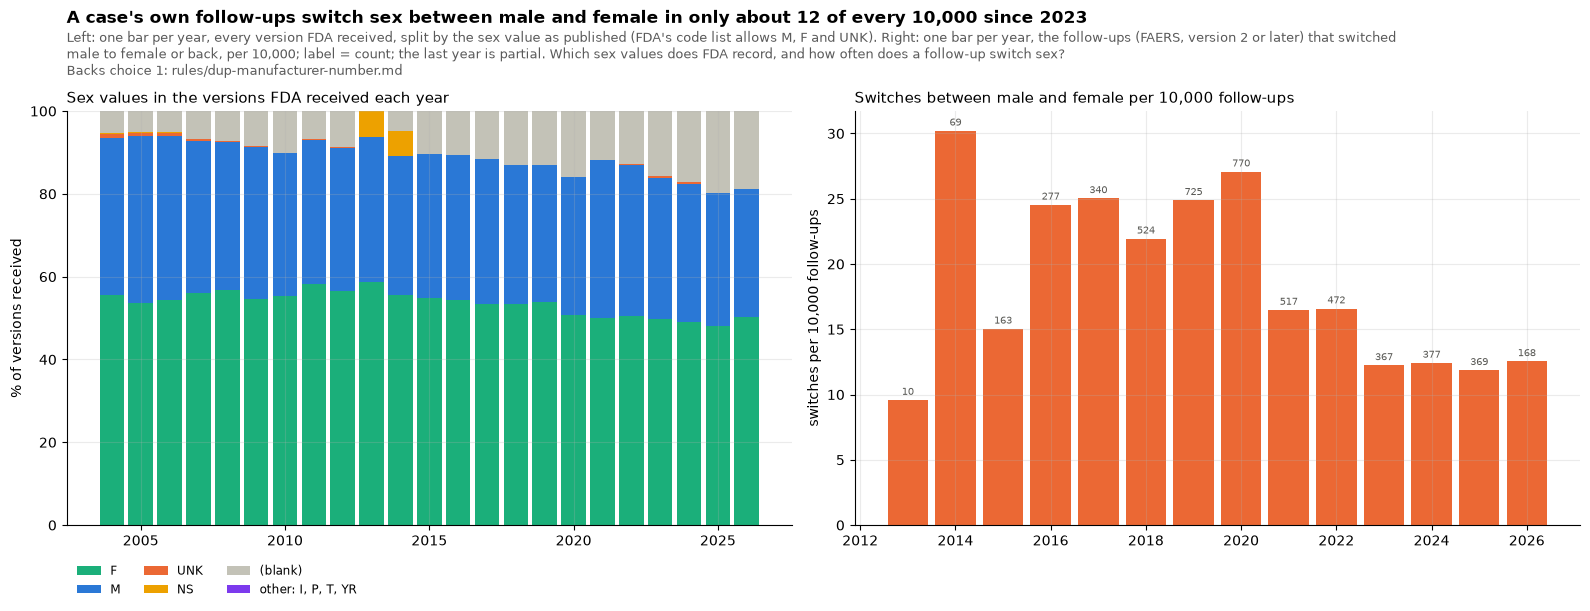

versions with a sex value outside M, F, UNK, NS: 341 (I, P, T, YR); switches per 10,000 follow-ups over all FAERS years: 18.0


In [22]:
vals = q("""SELECT fda_year_T AS y, coalesce(nullif(trim(upper(sex)), ''), '(blank)') AS sex, count(*) AS n
            FROM demo_T WHERE fda_year_T BETWEEN 2004 AND 2026 GROUP BY ALL""")
flips = q("""WITH v AS (
    SELECT caseid, fda_year_T AS y, upper(trim(sex)) AS s,
           lag(upper(trim(sex))) OVER (PARTITION BY caseid ORDER BY caseversion_T, fda_dt, qnum_T, primaryid) AS ps,
           row_number() OVER (PARTITION BY caseid ORDER BY caseversion_T, fda_dt, qnum_T, primaryid) AS rn
    FROM demo_T WHERE era_T = 'faers' AND caseid IS NOT NULL AND fda_year_T IS NOT NULL)
  SELECT y, count(*) AS follow_ups, count(*) FILTER (WHERE ps IN ('M', 'F') AND s IN ('M', 'F') AND ps <> s) AS flips
  FROM v WHERE rn > 1 GROUP BY 1 ORDER BY 1""")
flips["per_10k"] = 1e4 * flips.flips / flips.follow_ups
known = ["F", "M", "UNK", "NS", "(blank)"]
other = sorted(set(vals.sex) - set(known))
vals["sex"] = vals.sex.where(vals.sex.isin(known), "other: " + ", ".join(other))
p = vals.pivot_table(index="y", columns="sex", values="n", aggfunc="sum", fill_value=0)
p = 100 * p.div(p.sum(axis=1), axis=0)
cols = dict(
    zip(
        known + [c for c in p.columns if c.startswith("other")],
        [GREEN, BLUE, ORANGE, SERIES[3], GREY, "#7c3aed"],
        strict=False,
    )
)
fig, (a, b) = plt.subplots(1, 2, figsize=(16, 5.4))
bottom = 0
for s, c in cols.items():
    if s in p:
        a.bar(p.index, p[s], bottom=bottom, color=c, label=s, width=0.85)
        bottom = bottom + p[s]
a.set_title("Sex values in the versions FDA received each year", loc="left", fontsize=11)
a.set_ylabel("% of versions received")
a.set_ylim(0, 100)
a.legend(ncol=3, loc="upper left", bbox_to_anchor=(0, -0.07), frameon=False, fontsize=8.5)
s2 = flips[flips.y >= 2013]
b.bar(s2.y, s2.per_10k, color=ORANGE, width=0.85)
for _, r in s2.iterrows():
    b.text(r.y, r.per_10k + 0.4, f"{int(r.flips):,}", ha="center", fontsize=7.5, color=MUTED)
b.set_title("Switches between male and female per 10,000 follow-ups", loc="left", fontsize=11)
b.set_ylabel("switches per 10,000 follow-ups")
recent = flips[flips.y >= 2023]
plt.tight_layout()
title(
    header(fig),
    f"A case's own follow-ups switch sex between male and female in only about {1e4 * recent.flips.sum() / recent.follow_ups.sum():.0f} "
    f"of every 10,000 since 2023",
    "Left: one bar per year, every version FDA received, split by the sex value as published (FDA's code list allows M, F and UNK). "
    "Right: one bar per year, the follow-ups (FAERS, version 2 or later) that switched male to female or back, per 10,000; label = count; the last year is partial.",
    "Which sex values does FDA record, and how often does a follow-up switch sex?",
    rule_line(1),
)
plt.show()
print(
    f"versions with a sex value outside M, F, UNK, NS: {int(vals[vals.sex.str.startswith('other')].n.sum()):,} ({', '.join(other)}); "
    f"switches per 10,000 follow-ups over all FAERS years: {1e4 * flips.flips.sum() / flips.follow_ups.sum():.1f}"
)

**Padded dates and group size.** Choice 7 rests on this chart. **Reading the chart.** One bar per exact group size of the AEOLUS rule: the cases set aside in groups that size, split by the group's shared event date (any other day, the 1st of another month, 1 January, or a month or year only). The dashed line marks where the guard starts. The table under it splits the large padded groups by who sent them: the guard applies only when one company sent every copy.

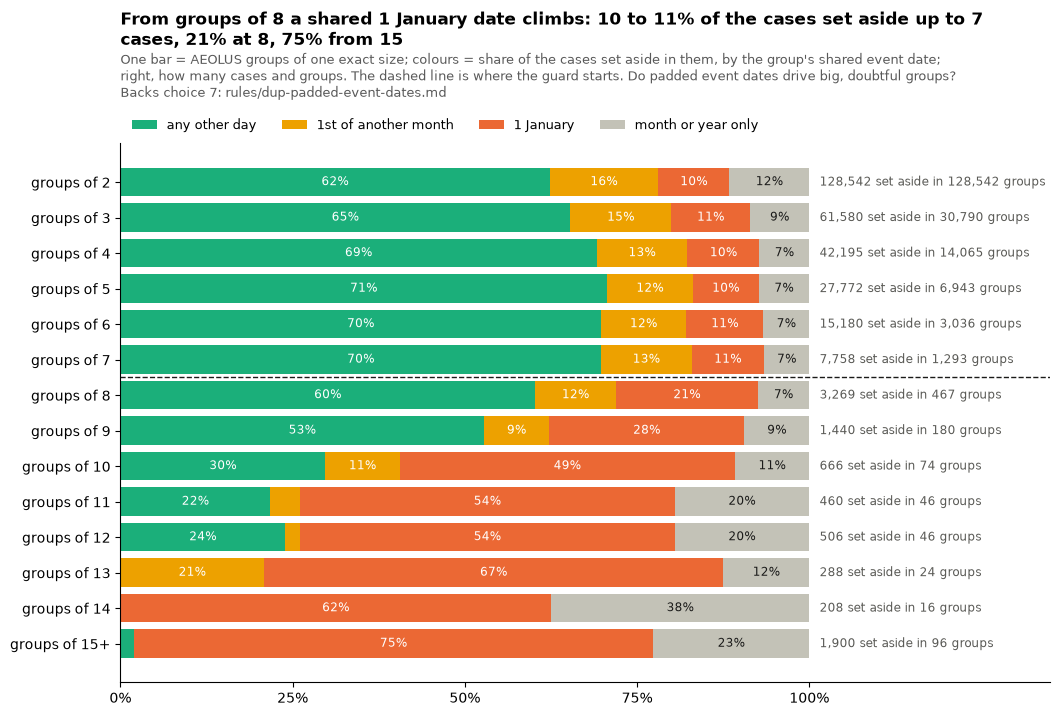

**Who sent the large padded groups?** One row per kind of group of 8 or more with a padded shared event date (choice 7).

,groups_,cases,set_aside
who,,,
"two or more companies, or a blank sender: still set aside",68,621,553
"one company: guarded, nothing set aside",372,4689,4317


In [23]:
pd_ = q("""WITH g AS (SELECT g_cur_T, count(*) AS n, any_value(event_dt) AS dt FROM w.case_rules_T WHERE n_cur_T > 1 GROUP BY 1)
  SELECT CASE WHEN length(dt) = 8 AND right(dt, 4) = '0101' THEN '1 January' WHEN length(dt) = 8 AND right(dt, 2) = '01' THEN '1st of another month'
              WHEN length(dt) = 8 THEN 'any other day' ELSE 'month or year only' END AS kind,
         least(n, 15) AS size, count(*) AS groups_, sum(n - 1) AS aside FROM g GROUP BY ALL""")
kinds = ["any other day", "1st of another month", "1 January", "month or year only"]
p = pd_.pivot_table(
    index="size", columns="kind", values="aside", aggfunc="sum", fill_value=0
).reindex(columns=kinds, fill_value=0)
gs = pd_.groupby("size").groups_.sum()
pct = 100 * p.div(p.sum(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(12, 7))
left = np.zeros(len(pct))
for k, c in zip(kinds, [GREEN, SERIES[3], ORANGE, GREY], strict=True):
    ax.barh(range(len(pct)), pct[k], left=left, color=c, label=k)
    for i, v in enumerate(pct[k]):
        if v >= 5:
            ax.text(
                left[i] + v / 2,
                i,
                f"{v:.0f}%",
                ha="center",
                va="center",
                fontsize=8.5,
                color="white" if k != "month or year only" else INK,
            )
    left += pct[k].values
for i, s in enumerate(pct.index):
    ax.text(
        101.5,
        i,
        f"{int(p.loc[s].sum()):,} set aside in {int(gs[s]):,} groups",
        va="center",
        fontsize=8.5,
        color=MUTED,
    )
ax.axhline(5.5, color=INK, lw=1, ls="--")
ax.set_yticks(range(len(pct)))
ax.set_yticklabels([f"groups of {s}" if s < 15 else "groups of 15+" for s in pct.index])
ax.invert_yaxis()
ax.set_xlim(0, 135)
ax.set_xticks([0, 25, 50, 75, 100])
ax.set_xticklabels(["0%", "25%", "50%", "75%", "100%"])
ax.grid(False)
ax.legend(ncol=4, loc="lower left", bbox_to_anchor=(0, 1.0), frameon=False, fontsize=9)
jan = pct["1 January"]
title(
    header(fig),
    f"From groups of 8 a shared 1 January date climbs: {jan.loc[2:7].min():.0f} to {jan.loc[2:7].max():.0f}% of the cases set aside "
    f"up to 7 cases, {jan.loc[8]:.0f}% at 8, {jan.loc[15]:.0f}% from 15",
    "One bar = AEOLUS groups of one exact size; colours = share of the cases set aside in them, by the group's shared event date; "
    "right, how many cases and groups. The dashed line is where the guard starts.",
    "Do padded event dates drive big, doubtful groups?",
    rule_line(7),
)
plt.show()
big = q("""SELECT CASE WHEN padded THEN 'one company: guarded, nothing set aside' ELSE 'two or more companies, or a blank sender: still set aside' END AS who,
                   count(DISTINCT g_cur_T) AS groups_, count(*) AS cases, count(*) - count(DISTINCT g_cur_T) AS set_aside
            FROM w.tag_T WHERE padded_any GROUP BY 1 ORDER BY 1 DESC""").set_index("who")
display(
    Markdown(
        "**Who sent the large padded groups?** One row per kind of group of 8 or more with a padded shared event date (choice 7)."
    )
)
big

### Examples

**Reading the example charts.** Each row is one group of cases the rule calls one patient's event, named by why it was picked and the shown copy's suspect drug. A colour compares only the cases inside that group, field by field: green, all agree; orange, some differ; dark grey, one is blank; light grey, all are blank. Below each chart, one table per group: one column per case, the shown copy first (the latest received), at most four cases. A shaded cell differs from the shown copy; a grey cell is empty. Drug and reaction lists are normalised drug names and PTs in capitals.

In [24]:
SHOW = {
    "caseid": "caseid",
    "era": "era_T",
    "version": "caseversion_T",
    "first received": "strftime(first_fda_dt_T, '%Y-%m-%d')",
    "sender": "mfr_sndr",
    "mfr number": "mfr_num",
    "report type": "rept_cod",
    "reporter": "occp_cod",
    "event date": "event_dt",
    "age": "nullif(concat_ws(' ', age, age_cod), '')",
    "sex": "sex",
    "country": "country_fix_T",
    "reporter country": "reporter_country_fix_T",
    "weight": "nullif(concat_ws(' ', wt, wt_cod), '')",
}
LISTS = ["suspect drugs", "other drugs", "reactions"]
COMPARED = [
    "event date",
    "age",
    "sex",
    "country",
    "reporter country",
    "weight",
] + LISTS  # the chart leaves out fields that differ by nature (dates, senders)
STATE_COLOURS = [GREEN, ORANGE, SERIES[6], GREY]
con.execute("CREATE OR REPLACE TEMP TABLE picks_T (label VARCHAR, g UHUGEINT, ord INTEGER)")


def pick(rule, label, where="TRUE", having="TRUE", k=1, order="g"):
    """Choose k groups of a rule: groups whose cases meet `where` and whose group meets `having`."""
    label = label.replace("'", "''")
    con.execute(f"""INSERT INTO picks_T SELECT '{label}', g, (SELECT count(*) FROM picks_T) + row_number() OVER (ORDER BY {order.replace("count(*)", "n")}) FROM (
        SELECT g_{rule}_T AS g, count(*) AS n FROM w.case_rules_T WHERE n_{rule}_T > 1 AND {where} GROUP BY 1
        HAVING {having} AND g_{rule}_T NOT IN (SELECT g FROM picks_T) ORDER BY {order} LIMIT {k})""")


def with_lists(m):
    """Add each case's suspect drugs, other drugs and reactions (FDA's text, normalised names, upper-cased PTs)."""
    con.register("shown_T", m[["era_T", "primaryid", "quarter_T"]])
    drugs = q("""SELECT era_T, primaryid, quarter_T,
        string_agg(DISTINCT d.drugname_norm_T, '; ' ORDER BY d.drugname_norm_T) FILTER (WHERE d.role_cod = 'PS') AS "suspect drugs",
        string_agg(DISTINCT d.drugname_norm_T, '; ' ORDER BY d.drugname_norm_T) FILTER (WHERE d.role_cod <> 'PS') AS "other drugs"
        FROM shown_T JOIN drug_latest_T d USING (era_T, primaryid, quarter_T) GROUP BY ALL""")
    reac = q("""SELECT era_T, primaryid, quarter_T, string_agg(DISTINCT upper(r.pt), '; ' ORDER BY upper(r.pt)) AS reactions
        FROM shown_T JOIN reac_latest_T r USING (era_T, primaryid, quarter_T) GROUP BY ALL""")
    con.unregister("shown_T")
    return m.merge(drugs, how="left", on=["era_T", "primaryid", "quarter_T"]).merge(
        reac, how="left", on=["era_T", "primaryid", "quarter_T"]
    )


def side_by_side(t, caption, compare=True):
    """One table, one column per case; a cell differing from the first column is shaded, an empty one grey."""
    first = t.iloc[:, 0]

    def shade(col):
        return [
            "background-color: #e8e8e4"
            if pd.isna(v)
            else ("background-color: #fbd9c6" if compare and not pd.isna(f) and v != f else "")
            for v, f in zip(col, first, strict=True)
        ]

    display(Markdown(caption))
    display(t.style.apply(shade).format(na_rep=""))


def show(rule, claim, asks, backs=(), members=4):
    """The agreement chart for the picked groups of a rule, then one side-by-side table per group, the shown copy first.
    Each example is named by its label and the shown copy's suspect drug, so no two rows look alike."""
    m = with_lists(
        q(f"""SELECT * FROM (
          SELECT p.label, p.ord, w.n_{rule}_T AS n, w.era_T, w.primaryid, w.quarter_T, {", ".join(f'{v} AS "{k}"' for k, v in SHOW.items())},
                 row_number() OVER (PARTITION BY p.ord ORDER BY {LATEST}) AS pos
          FROM picks_T p JOIN w.case_rules_T w ON w.g_{rule}_T = p.g) WHERE pos <= {members} ORDER BY ord, pos""")
    )
    groups = [g for _, g in m.groupby("ord", sort=True)]
    names = []
    for g in groups:
        drug = g["suspect drugs"].iloc[0] or g["other drugs"].iloc[0] or "no drug"
        drug = drug if len(drug) <= 28 else drug[:26] + "..."
        name = f"{g.label.iloc[0]}: {drug}"
        names.append(name if name not in names else f"{name} ({len(names) + 1})")

    def state(v):
        return 3 if v.isna().all() else (2 if v.isna().any() else (1 if v.nunique() > 1 else 0))

    mat = np.array([[state(g[f]) for f in COMPARED] for g in groups])
    fig, ax = plt.subplots(figsize=(14, 0.45 * len(groups) + 1.6))
    ax.imshow(mat, cmap=mpl.colors.ListedColormap(STATE_COLOURS), vmin=0, vmax=3, aspect="auto")
    ax.set_xticks(range(len(COMPARED)))
    ax.set_xticklabels(COMPARED, fontsize=9)
    ax.grid(False)
    ax.set_yticks(range(len(groups)))
    ax.set_yticklabels(
        [f"{n} ({int(g.n.iloc[0])} cases)" for n, g in zip(names, groups, strict=True)], fontsize=8
    )
    ax.legend(
        handles=[
            mpl.patches.Patch(color=c, label=label)
            for c, label in zip(
                STATE_COLOURS, ["all agree", "some differ", "some empty", "all empty"], strict=True
            )
        ],
        ncol=4,
        loc="lower left",
        bbox_to_anchor=(0, 1.0),
        fontsize=8,
        frameon=False,
    )
    title(
        header(fig),
        claim,
        "One row per example group, named by why it was picked and its shown copy's suspect drug. A colour compares only the cases "
        "inside that group, field by field: green all agree, orange some differ, dark grey one is blank, light grey all are blank.",
        asks,
        rule_line(backs),
    )
    plt.show()
    for n, g in zip(names, groups, strict=True):
        t_ = g.set_index("caseid")[list(SHOW)[1:] + LISTS].T
        t_.columns = [f"{c} (shown)" if i == 0 else str(c) for i, c in enumerate(t_.columns)]
        side_by_side(
            t_,
            f"**{n}**, group of {int(g.n.iloc[0])} cases"
            + (f" (first {members} shown)" if g.n.iloc[0] > members else ""),
        )
    con.execute("DELETE FROM picks_T")

#### The AEOLUS rule

Country here is the occurrence country first, else the reporter's, so the reporter country can differ in a true duplicate. The largest group from one company has a padded event date, so the padded-date guard of choice 7 leaves it whole; the last example has a padded date too but comes from several companies, so it stays set aside.

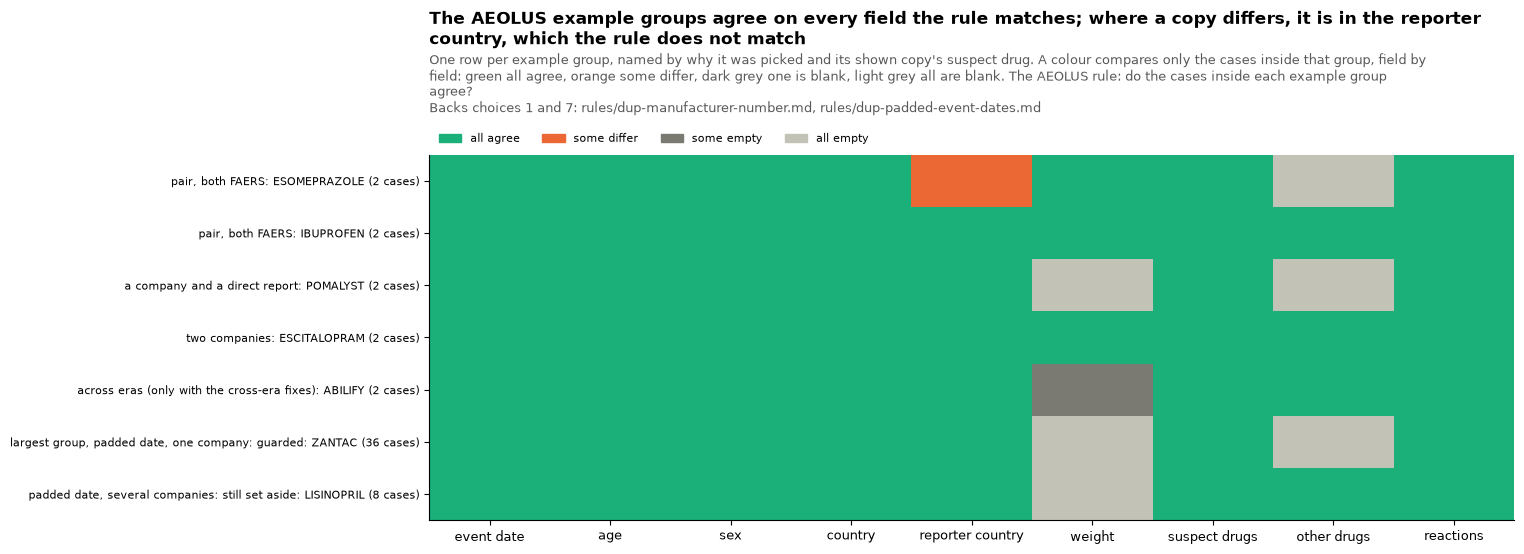

**pair, both FAERS: ESOMEPRAZOLE**, group of 2 cases

,17970641 (shown),17902556
era,faers,faers
version,2,1
first received,2020-07-02,2020-06-17
sender,RANBAXY,AUROBINDO
mfr number,FR-SUN PHARMACEUTICAL INDUSTRIES LTD-2020RR-252080,FR-AUROBINDO-AUR-APL-2020-029642
report type,EXP,EXP
reporter,HP,PH
event date,20200530,20200530
age,15 YR,15 YR
sex,F,F


**pair, both FAERS: IBUPROFEN**, group of 2 cases

,23163228 (shown),23124497
era,faers,faers
version,1,1
first received,2023-11-09,2023-10-30
sender,TEVA,MYLAN
mfr number,HR-TEVA-2023-HR-2942367,HR-MYLANLABS-2023M1113701
report type,EXP,EXP
reporter,MD,MD
event date,20230901,20230901
age,44 YR,44 YR
sex,F,F


**a company and a direct report: POMALYST**, group of 2 cases

...

,14540971 (shown),6052884
era,faers,legacy
version,1,
first received,2018-02-16,2006-05-26
sender,OTSUKA,BRISTOL-MYERS SQUIBB COMPANY
mfr number,GB-OTSUKA-DJ20060805,GB-BRISTOL-MYERS SQUIBB COMPANY-13377684
report type,EXP,EXP
reporter,CN,OT
event date,20060401,20060401
age,49 YR,49 YR
sex,M,M


**largest group, padded date, one company: guarded: ZANTAC**, group of 36 cases (first 4 shown)

,21528013 (shown),21519291,21501131,21338480
era,faers,faers,faers,faers
version,1,1,1,1
first received,2022-10-31,2022-10-28,2022-10-25,2022-09-15
sender,SANOFI AVENTIS,SANOFI AVENTIS,SANOFI AVENTIS,SANOFI AVENTIS
mfr number,US-SA-2022SA442570,US-SA-2022SA440545,US-SA-2022SA433090,US-SA-2022SA380357
report type,EXP,EXP,EXP,EXP
reporter,MD,MD,MD,MD
event date,20180101,20180101,20180101,20180101
age,59 YR,59 YR,59 YR,59 YR
sex,M,M,M,M


**padded date, several companies: still set aside: LISINOPRIL**, group of 8 cases (first 4 shown)

,18599931 (shown),18546577,18544569,18544144
era,faers,faers,faers,faers
version,1,1,1,1
first received,2020-12-10,2020-11-25,2020-11-25,2020-11-25
sender,MYLAN,TEVA,EMCURE,ALVOGEN
mfr number,GB-MYLANLABS-2020M1099062,GB-TEVA-2020-GB-1851938,GB-EMCURE PHARMACEUTICALS LTD-2020-EPL-001919,GB-ALVOGEN-2020-ALVOGEN-115294
report type,EXP,EXP,EXP,EXP
reporter,PH,PH,PH,PH
event date,202010,202010,202010,202010
age,68 YR,68 YR,68 YR,68 YR
sex,M,M,M,M


In [25]:
pick("cur", "pair, both FAERS", having="bool_and(era_T = 'faers') AND count(*) = 2", k=2)
pick(
    "cur",
    "a company and a direct report",
    having="bool_or(sender_type_T = 'direct to FDA') AND bool_or(sender_type_T LIKE 'manufacturer%')",
)
pick("cur", "two companies", having="count(DISTINCT mfr_sndr) = 2")
pick("cur", "across eras (only with the cross-era fixes)", having="count(DISTINCT era_T) = 2")
pick(
    "cur",
    "largest group, padded date, one company: guarded",
    having="count(sndr_up_T) = count(*) AND count(DISTINCT sndr_up_T) = 1",
    order="count(*) DESC, g",
)
pick(
    "cur",
    "padded date, several companies: still set aside",
    having="count(*) >= 8 AND count(DISTINCT sndr_up_T) > 1 "
    "AND (length(any_value(event_dt)) < 8 OR right(any_value(event_dt), 4) = '0101')",
)
show(
    "cur",
    "The AEOLUS example groups agree on every field the rule matches; where a copy differs, it is in the reporter country, which the rule does not match",
    "The AEOLUS rule: do the cases inside each example group agree?",
    backs=(1, 7),
)

#### a. Manufacturer number

The number rule mostly finds AERS-era copies (2004 to 2011). A number can be a labeller code rather than a case number, as with one maker's 54973 reused for 25 patients of both sexes and all ages: the guards of choice 1 skip such groups.

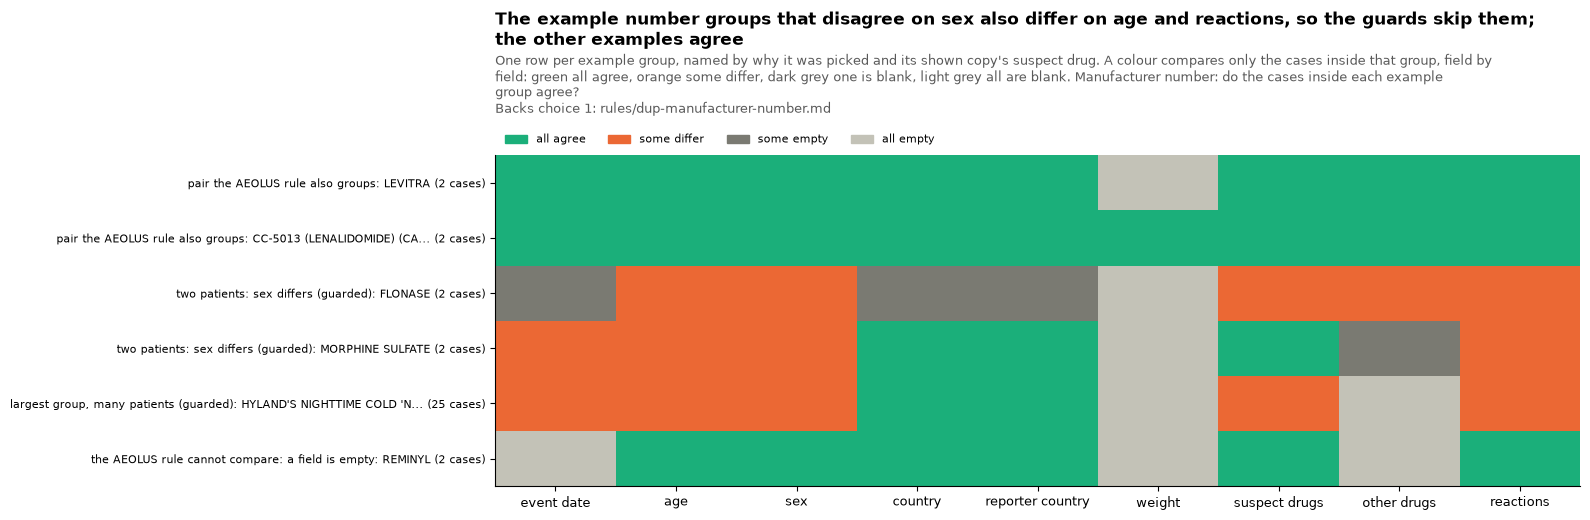

**pair the AEOLUS rule also groups: LEVITRA**, group of 2 cases

,5940699 (shown),5876449
era,legacy,legacy
version,,
first received,2006-01-06,2005-09-01
sender,BAYER PHARMACEUTICALS CORPORATION,BAYER PHARMACEUTICALS CORPORATION
mfr number,200511422BWH,200511422BWH
report type,PER,PER
reporter,,
event date,20040101,20040101
age,63 YR,63 YR
sex,M,M


**pair the AEOLUS rule also groups: CC-5013 (LENALIDOMIDE) (CA...**, group of 2 cases

,6510089 (shown),6314326
era,legacy,legacy
version,,
first received,2007-05-03,2007-05-03
sender,CELGENE CORPORATION,CELGENE CORPORATION
mfr number,163-C5013-06070529,163-C5013-06070529
report type,EXP,EXP
reporter,MD,MD
event date,20060630,20060630
age,19 YR,19 YR
sex,M,M


**two patients: sex differs (guarded): FLONASE**, group of 2 cases

...

,6705041 (shown),6705030
era,legacy,legacy
version,,
first received,2008-07-09,2008-07-09
sender,KV PHARMACEUTICALS COMPANY,KV PHARMACEUTICALS COMPANY
mfr number,14598,14598
report type,EXP,EXP
reporter,,
event date,20080407,20080403
age,67 YR,37 YR
sex,F,M


**largest group, many patients (guarded): HYLAND'S NIGHTTIME COLD 'N...**, group of 25 cases (first 4 shown)

,7753347 (shown),8439038,7996309,8276143
era,legacy,legacy,legacy,legacy
version,,,,
first received,2012-05-01,2012-02-21,2011-12-09,2011-11-23
sender,"HYLAND'S, INC.","HYLAND'S, INC.","HYLAND'S, INC.","HYLAND'S, INC."
mfr number,54973,54973,54973,54973
report type,EXP,EXP,EXP,EXP
reporter,,CN,,OT
event date,20120320,20120123,20110424,20111031
age,2 YR,79 YR,2 YR,7 YR
sex,M,M,M,F


**the AEOLUS rule cannot compare: a field is empty: REMINYL**, group of 2 cases

,6433025 (shown),6245216
era,legacy,legacy
version,,
first received,2007-02-26,2007-02-26
sender,JOHNSON + JOHNSON PHARMACEUTICAL R+D,JOHNSON + JOHNSON PHARMACEUTICAL R+D
mfr number,FR-JNJFOC-20070204208,FR-JNJFOC-20070204208
report type,EXP,EXP
reporter,MD,MD
event date,,
age,87 YR,87 YR
sex,F,F


In [26]:
pick(
    "mfr",
    "pair the AEOLUS rule also groups",
    having="count(*) = 2 AND count(DISTINCT g_cur_T) = 1 AND count(g_cur_T) = 2",
    k=2,
)
pick(
    "mfr",
    "two patients: sex differs (guarded)",
    having="count(*) = 2 AND count(DISTINCT sex_mf_T) = 2",
    k=2,
)
pick("mfr", "largest group, many patients (guarded)", order="count(*) DESC, g")
pick(
    "mfr",
    "the AEOLUS rule cannot compare: a field is empty",
    having="count(*) = 2 AND count(g_cur_T) < 2 AND count(DISTINCT sex_mf_T) = 1 AND count(DISTINCT ps_h_T) = 1 AND count(DISTINCT pts_up_h_T) = 1",
)
show(
    "mfr",
    "The example number groups that disagree on sex also differ on age and reactions, so the guards skip them; the other examples agree",
    "Manufacturer number: do the cases inside each example group agree?",
    backs=1,
)

#### b. DiAna's rule-based match

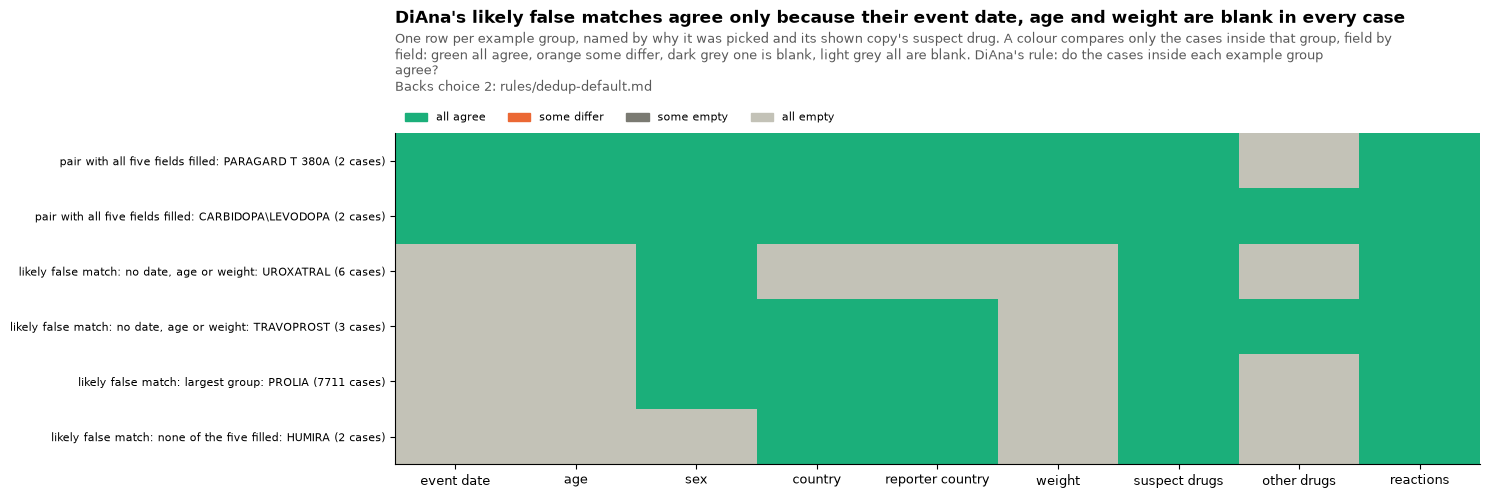

**pair with all five fields filled: PARAGARD T 380A**, group of 2 cases

,15818020 (shown),14536312
era,faers,faers
version,2,1
first received,2019-01-13,2018-02-15
sender,COOPERSURGICAL,TEVA
mfr number,"US-COOPERSURGICAL, INC.-US-2018CPS018595",US-TEVA-2018-US-857254
report type,PER,PER
reporter,CN,CN
event date,20180129,20180129
age,27 YR,27 YR
sex,F,F


**pair with all five fields filled: CARBIDOPA\LEVODOPA**, group of 2 cases

,22517791 (shown),22032711
era,faers,faers
version,1,3
first received,2023-06-04,2023-02-24
sender,ABBVIE,ABBVIE
mfr number,TR-ABBVIE-5188941,TR-ABBVIE-4316842
report type,EXP,EXP
reporter,HP,HP
event date,20221031,20221031
age,78 YR,78 YR
sex,M,M


**likely false match: no date, age or weight: UROXATRAL**, group of 6 cases (first 4 shown)

...

,18207200 (shown),18010896,17984883
era,faers,faers,faers
version,1,1,1
first received,2020-08-28,2020-07-10,2020-07-06
sender,NOVARTIS,NOVARTIS,NOVARTIS
mfr number,NVSC2018US010715,NVSC2018US007968,NVSC2018US007380
report type,PER,PER,PER
reporter,CN,CN,CN
event date,,,
age,,,
sex,F,F,F


**likely false match: largest group: PROLIA**, group of 7711 cases (first 4 shown)

,24330061 (shown),24231446,24154805,24017814
era,faers,faers,faers,faers
version,1,1,2,1
first received,2024-09-17,2024-08-21,2024-07-31,2024-06-27
sender,AMGEN,AMGEN,AMGEN,AMGEN
mfr number,US-AMGEN-USASP2024184391,US-AMGEN-USASP2024162084,US-AMGEN-USASP2024147359,US-AMGEN-USASP2024126020
report type,PER,PER,PER,PER
reporter,CN,CN,CN,CN
event date,,,,
age,,,,
sex,F,F,F,F


**likely false match: none of the five filled: HUMIRA**, group of 2 cases

,11964144 (shown),10819874
era,faers,faers
version,1,1
first received,2016-01-26,2015-02-18
sender,ABBVIE,ABBVIE
mfr number,US-ABBVIE-15K-163-1381900-00,US-ABBVIE-14K-163-1295501-00
report type,PER,PER
reporter,CN,CN
event date,,
age,,
sex,,


In [27]:
pick("rb", "pair with all five fields filled", where=f"{NA5} = 0", having="count(*) = 2", k=2)
pick(
    "rb",
    "likely false match: no date, age or weight",
    where=f"{NA5} = 4 AND sex_mf_T IS NOT NULL",
    having="count(*) BETWEEN 3 AND 6",
    k=2,
)
pick("rb", "likely false match: largest group", order="count(*) DESC, g")
pick("rb", "likely false match: none of the five filled", where=f"{NA5} = 5", having="count(*) = 2")
show(
    "rb",
    "DiAna's likely false matches agree only because their event date, age and weight are blank in every case",
    "DiAna's rule: do the cases inside each example group agree?",
    backs=2,
)

#### c. Groups that exist only after imputation

In each group one case had an empty field, filled from another version of its case. The table shows FDA's values, so that field is still empty here.

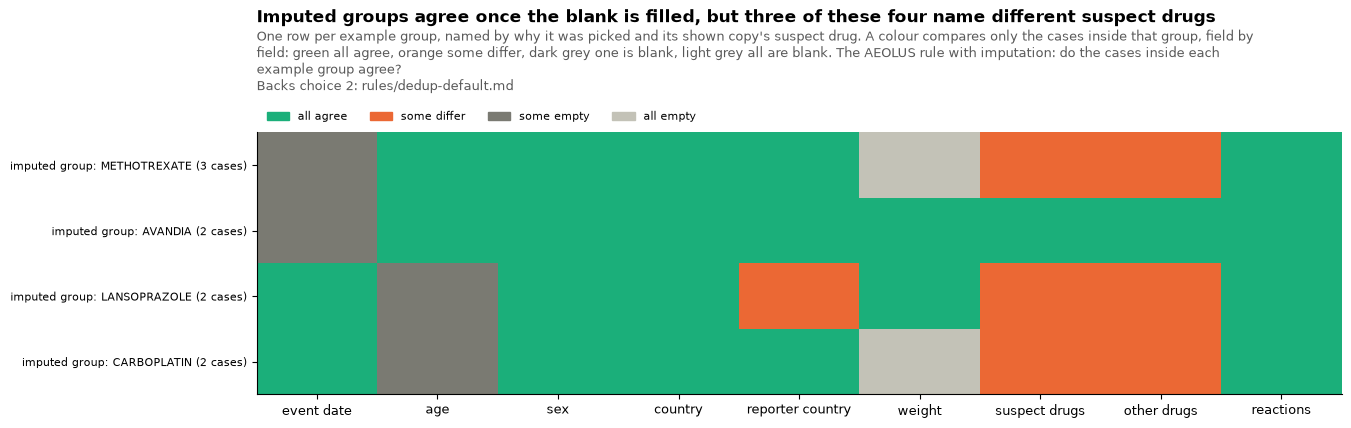

**imputed group: METHOTREXATE**, group of 3 cases

,24127093 (shown),24066189,24044639
era,faers,faers,faers
version,1,2,2
first received,2024-07-23,2024-07-09,2024-07-03
sender,NORDIC PHARMA,UCB,SANDOZ
mfr number,DE-NORDICGR-2023002813,DE-UCBSA-2024034427,DE-SANDOZ INC.-SDZ2024DE061941
report type,EXP,EXP,EXP
reporter,MD,MD,MD
event date,20220301,20220301,
age,72 YR,72 YR,72 YR
sex,F,F,F


**imputed group: AVANDIA**, group of 2 cases

,9934732 (shown),6566886
era,faers,legacy
version,2,
first received,2014-02-28,2010-12-02
sender,GLAXOSMITHKLINE,GLAXOSMITHKLINE
mfr number,US-GLAXOSMITHKLINE-A0712512A,A0712512A
report type,EXP,EXP
reporter,MD,OT
event date,20040218,
age,66 YR,66 YR
sex,M,M


**imputed group: LANSOPRAZOLE**, group of 2 cases

,16723554 (shown),15882959
era,faers,faers
version,1,3
first received,2019-08-21,2019-01-29
sender,RANBAXY,ROCHE
mfr number,FR-SUN PHARMACEUTICAL INDUSTRIES LTD-2019RR-218205,FR-ROCHE-2250547
report type,EXP,EXP
reporter,OT,OT
event date,20181213,20181213
age,38 YR,
sex,F,F


**imputed group: CARBOPLATIN**, group of 2 cases

,20340483 (shown),20201508
era,faers,faers
version,3,4
first received,2022-01-17,2021-12-17
sender,NOVARTIS,BRISTOL MYERS SQUIBB
mfr number,NVSC2022DE007852,DE-BRISTOL-MYERS SQUIBB COMPANY-BMS-2021-129947
report type,EXP,EXP
reporter,HP,MD
event date,20210423,20210423
age,49 YR,
sex,M,M


In [28]:
pick(
    "imp",
    "imputed group",
    having="bool_or(imputed_T) AND NOT (count(g_cur_T) = count(*) AND count(DISTINCT g_cur_T) = 1)",
    k=4,
)
show(
    "imp",
    "Imputed groups agree once the blank is filled, but three of these four name different suspect drugs",
    "The AEOLUS rule with imputation: do the cases inside each example group agree?",
    backs=2,
)

#### Likely misses of the AEOLUS rule

Pairs that share a manufacturer number and sender and agree on sex and suspect drugs, which the AEOLUS rule does not group because one field differs.

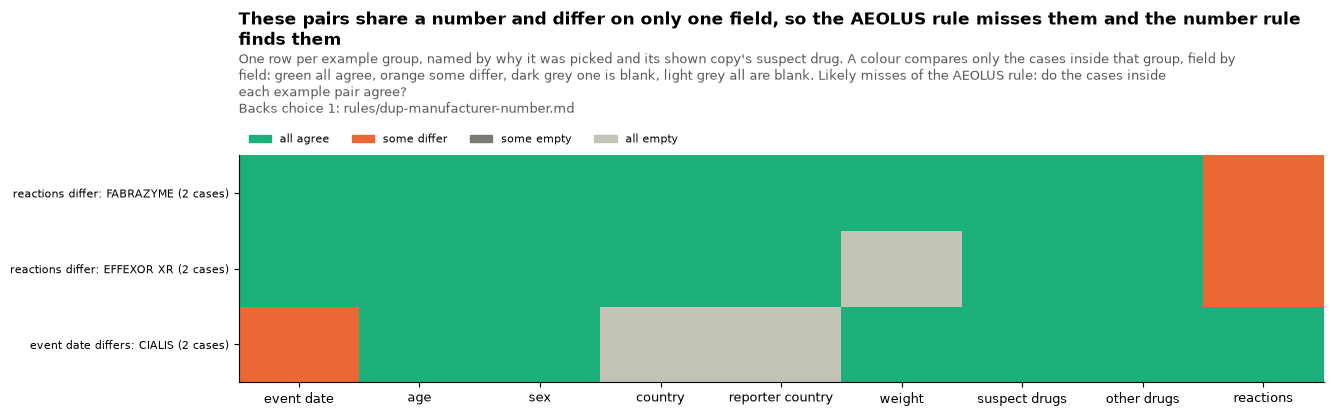

**reactions differ: FABRAZYME**, group of 2 cases

,5989845 (shown),5962351
era,legacy,legacy
version,,
first received,2006-02-14,2006-01-10
sender,GENZYME CORPORATION,GENZYME CORPORATION
mfr number,FABR-11341,FABR-11341
report type,EXP,EXP
reporter,MD,MD
event date,20051210,20051210
age,49 YR,49 YR
sex,M,M


**reactions differ: EFFEXOR XR**, group of 2 cases

,5995488 (shown),5885240
era,legacy,legacy
version,,
first received,2006-02-13,2005-09-20
sender,WYETH PHARMACEUTICALS INC.,WYETH PHARMACEUTICALS INC.
mfr number,HQWYE467414SEP05,HQWYE467414SEP05
report type,EXP,EXP
reporter,CN,
event date,20040101,20040101
age,58 YR,58 YR
sex,M,M


**event date differs: CIALIS**, group of 2 cases

,5839599 (shown),5718941
era,legacy,legacy
version,,
first received,2004-12-14,2004-12-14
sender,ELI LILLY AND COMPANY,ELI LILLY AND COMPANY
mfr number,USA040774120,USA040774120
report type,PER,PER
reporter,,
event date,20040101,20410101
age,52 YR,52 YR
sex,M,M


In [29]:
pick(
    "mfr",
    "reactions differ",
    having="count(*) = 2 AND count(DISTINCT g_cur_T) = 2 AND count(DISTINCT event_dt) = 1 AND count(DISTINCT sex) = 1 AND count(DISTINCT pts_up_h_T) = 2 AND count(DISTINCT ps_h_T) = 1",
    k=2,
)
pick(
    "mfr",
    "event date differs",
    having="count(*) = 2 AND count(DISTINCT event_dt) = 2 AND count(DISTINCT age) = 1 AND count(DISTINCT sex) = 1 AND count(DISTINCT pts_up_h_T) = 1 AND count(DISTINCT ps_h_T) = 1",
)
show(
    "mfr",
    "These pairs share a number and differ on only one field, so the AEOLUS rule misses them and the number rule finds them",
    "Likely misses of the AEOLUS rule: do the cases inside each example pair agree?",
    backs=1,
)

#### d. Reports with no drug or no reaction

These reports are not duplicates and are never hidden (choice 6). **Reading the chart.** Four views of the same reports, all of them, not examples: the serious outcome codes they carry, the suspect drug they name, the report type and who reported. One bar is the number of reports with that value. The three cases below illustrate the three kinds.

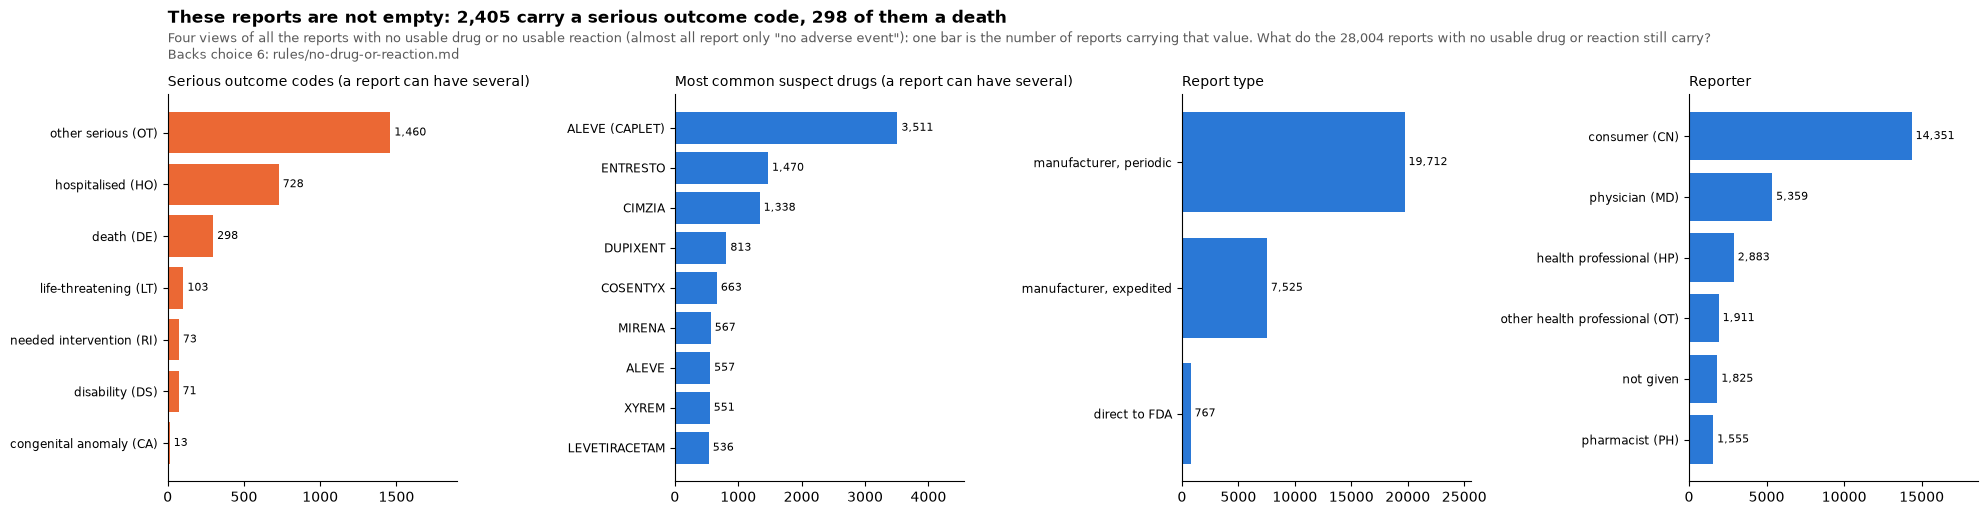

**Three example cases, one of each kind**

label,only unknown or unspecified drugs,only no adverse event,no reaction row
caseid,24654478,8033983,7896078
era,faers,legacy,legacy
version,2,,
first received,2024-11-22,2011-07-13,2011-04-12
sender,SIGMAPHARM,NOVARTIS PHARMACEUTICAL CORPORATION,WATSON
mfr number,"US-SIGMAPHARM LABORATORIES, LLC-2024SIG00060",PHHY2011VE43757,US-WATSON-2011-04835
report type,EXP,EXP,EXP
reporter,HP,OT,CN
event date,,,20080307
age,,YR,YR


In [30]:
EMPTY_CASES = "w.case_rules_T r WHERE r.empty_T"
cont = {
    "Which serious outcomes are recorded?": q(f"""SELECT o.outc_cod AS v, count(DISTINCT (r.era_T, r.case_key_T)) AS n FROM {EMPTY_CASES.replace("WHERE", "JOIN outc_latest_T o USING (era_T, primaryid, quarter_T) WHERE")}
      AND o.outc_cod IN ({sql_list(SERIOUS)}) GROUP BY 1 ORDER BY 2 DESC"""),
    "Which suspect drug do they name?": q(f"""SELECT d.drugname_norm_T AS v, count(DISTINCT (r.era_T, r.case_key_T)) AS n FROM {EMPTY_CASES.replace("WHERE", "JOIN drug_latest_T d USING (era_T, primaryid, quarter_T) WHERE")}
      AND d.role_cod = 'PS' GROUP BY 1 ORDER BY 2 DESC LIMIT 9"""),
    "Which report type are they?": q(
        f"SELECT r.sender_type_T AS v, count(*) AS n FROM {EMPTY_CASES} GROUP BY 1 ORDER BY 2 DESC"
    ),
    "Who reported them?": q(
        f"SELECT coalesce(r.occp_cod, 'not given') AS v, count(*) AS n FROM {EMPTY_CASES} GROUP BY 1 ORDER BY 2 DESC LIMIT 6"
    ),
}
WHO = {
    "CN": "consumer",
    "MD": "physician",
    "HP": "health professional",
    "OT": "other health professional",
    "PH": "pharmacist",
    "LW": "lawyer",
}
cont["Who reported them?"]["v"] = cont["Who reported them?"].v.map(
    lambda c: f"{WHO[c]} ({c})" if c in WHO else c
)
cont["Which serious outcomes are recorded?"]["v"] = cont[
    "Which serious outcomes are recorded?"
].v.map(lambda c: f"{SERIOUS[c]} ({c})")
PANEL = {
    "Which serious outcomes are recorded?": "Serious outcome codes (a report can have several)",
    "Which suspect drug do they name?": "Most common suspect drugs (a report can have several)",
    "Which report type are they?": "Report type",
    "Who reported them?": "Reporter",
}
fig, axes = plt.subplots(1, 4, figsize=(20, 4.6))
for ax, (view, d) in zip(axes, cont.items(), strict=True):
    label_bars(
        ax,
        ax.barh(d.v[::-1].astype(str), d.n[::-1], color=ORANGE if "serious" in view else BLUE),
        horizontal=True,
    )
    ax.set_title(PANEL[view], loc="left", fontsize=10)
    ax.set_xlim(0, d.n.max() * 1.3)
    ax.tick_params(axis="y", labelsize=8.5)
    ax.grid(False)
ser = cont["Which serious outcomes are recorded?"].set_index("v").n
n_serious = con.execute(f"""SELECT count(DISTINCT (r.era_T, r.case_key_T)) FROM w.case_rules_T r JOIN outc_latest_T o USING (era_T, primaryid, quarter_T)
                            WHERE r.empty_T AND o.outc_cod IN ({sql_list(SERIOUS)})""").fetchone()[
    0
]
plt.tight_layout()
title(
    header(fig),
    f"These reports are not empty: {n_serious:,} carry a serious outcome code, {int(ser.get('death (DE)', 0)):,} of them a death",
    'Four views of all the reports with no usable drug or no usable reaction (almost all report only "no adverse event"): '
    "one bar is the number of reports carrying that value.",
    f"What do the {int(tot.cases):,} reports with no usable drug or reaction still carry?",
    rule_line(6),
)
plt.show()
EXAMPLES = {
    "only unknown or unspecified drugs": "n_drugs_T > 0 AND n_real_drugs_T = 0 AND n_real_pts_T > 0",
    "only no adverse event": "n_pts_T > 0 AND n_real_pts_T = 0 AND n_real_drugs_T > 0",
    "no reaction row": "n_pts_T = 0",
}
ex = with_lists(
    pd.concat(
        [
            q(f"""SELECT '{label}' AS label, era_T, primaryid, quarter_T,
                                 {", ".join(f'{v} AS "{k}"' for k, v in SHOW.items())} FROM w.case_rules_T WHERE {where} ORDER BY md5(case_key_T) LIMIT 1""")
            for label, where in EXAMPLES.items()
        ]
    )
)
side_by_side(
    ex.set_index("label")[list(SHOW) + LISTS].T,
    "**Three example cases, one of each kind**",
    compare=False,
)

## 5. Facts for the duplicate probability study

A later study will weigh partial agreement instead of demanding exact matches (vigiMatch style). It needs, for each field, how often true duplicates agree and how often unrelated cases agree by chance. Choice 7 adds one more field to it: the event date's precision (full day, 1 January, month only, year only).

- **Known duplicates**: pairs sharing a manufacturer number and sender under two case numbers (groups of exactly two). Section 4 shows some are two patients, so these rates understate how often true duplicates agree.
- **Random pairs**: the same number of pairs drawn at random from all cases, and from cases of the same sender.

**Reading the chart.** Left: one bar per field and kind of pair, the share of pairs that agree when both cases have the field; "at least one drug" and "at least one reaction" ask whether the two cases share any item. Right: the share of pairs with the field empty in one or both.

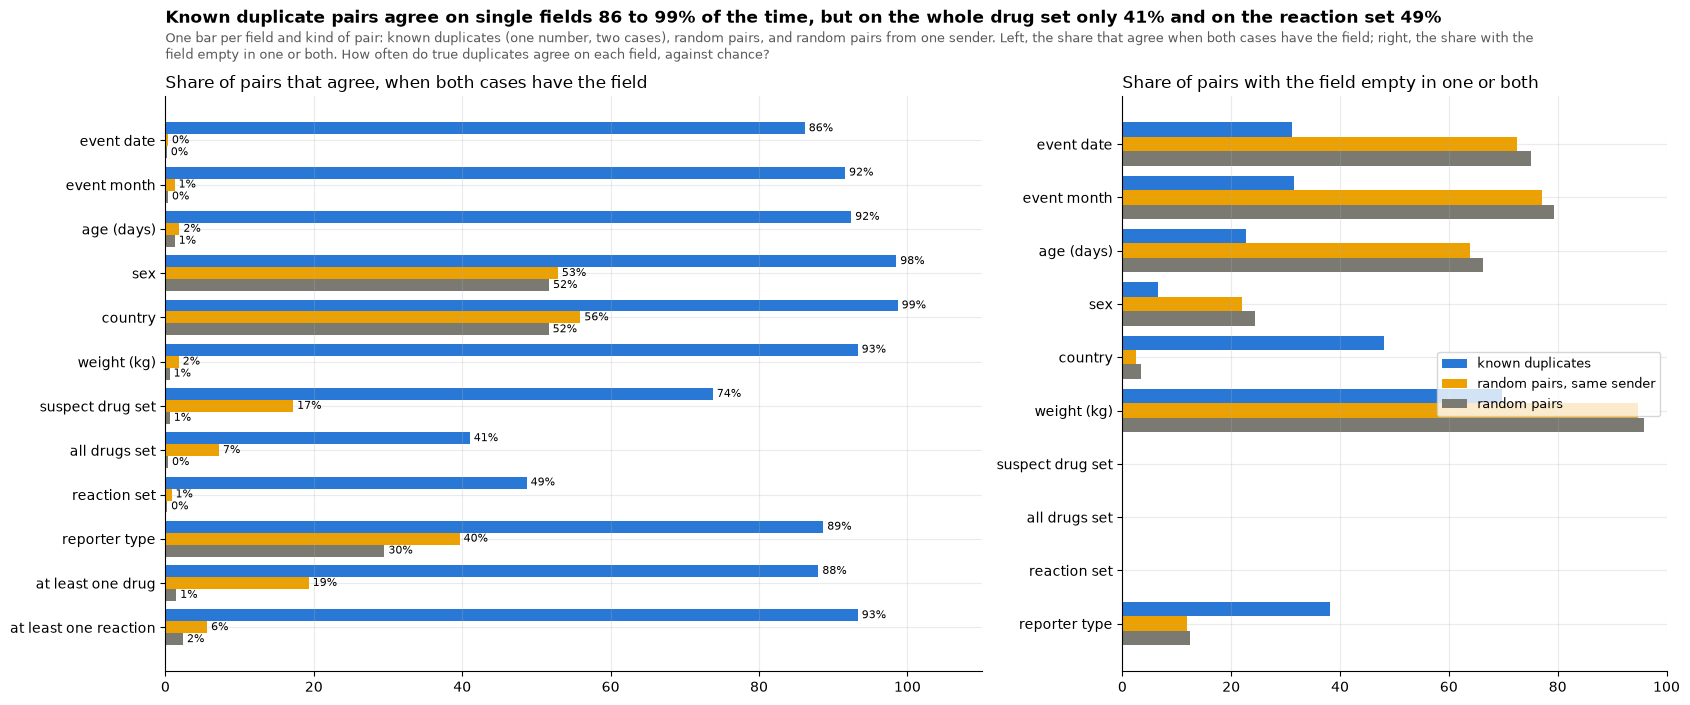

known-duplicate pairs each rule groups together: pairs 4,256, the AEOLUS rule 221, with imputation 221, DiAna RB 710, the AEOLUS rule never compares 3,070


kind,known duplicates,random pairs,"random pairs, same sender",known / random
field,,,,
event date,86.16,0.19,0.34,457.10
event month,91.60,0.34,1.23,267.76
age (days),92.42,1.25,1.89,73.73
sex,98.49,51.71,52.89,1.90
country,98.69,51.65,55.92,1.91
weight (kg),93.30,0.56,1.79,165.14
suspect drug set,73.78,0.59,17.21,125.60
all drugs set,41.02,0.35,7.21,116.40
reaction set,48.68,0.23,0.82,207.20


In [31]:
con.execute("""CREATE OR REPLACE TEMP TABLE pairs_T AS
WITH known AS (
  SELECT 'known duplicates' AS kind, min({'era_T': era_T, 'k': case_key_T}) AS a, max({'era_T': era_T, 'k': case_key_T}) AS b
  FROM w.case_rules_T WHERE n_mfr_T = 2 GROUP BY g_mfr_T),
r AS (SELECT era_T, case_key_T, row_number() OVER (ORDER BY hash(era_T, case_key_T, 'walk2'), case_key_T) AS i FROM w.case_rules_T),
rnd AS (SELECT 'random pairs' AS kind, {'era_T': x.era_T, 'k': x.case_key_T} AS a, {'era_T': y.era_T, 'k': y.case_key_T} AS b
        FROM r x JOIN r y ON y.i = x.i + 1 WHERE x.i % 2 = 1 AND x.i < 2 * (SELECT count(*) FROM known)),
s AS (SELECT era_T, case_key_T, mfr_sndr, row_number() OVER (PARTITION BY mfr_sndr ORDER BY hash(era_T, case_key_T, 'walk2'), case_key_T) AS i
      FROM w.case_rules_T WHERE mfr_sndr IS NOT NULL),
ss AS (SELECT 'random pairs, same sender' AS kind, {'era_T': x.era_T, 'k': x.case_key_T} AS a, {'era_T': y.era_T, 'k': y.case_key_T} AS b
       FROM s x JOIN s y ON x.mfr_sndr = y.mfr_sndr AND y.i = x.i + 1 WHERE x.i % 2 = 1
       ORDER BY hash(x.case_key_T, y.case_key_T), x.case_key_T LIMIT (SELECT count(*) FROM known))
SELECT *, row_number() OVER () AS pair_T FROM (SELECT * FROM known UNION ALL SELECT * FROM rnd UNION ALL SELECT * FROM ss)""")
con.execute("""CREATE OR REPLACE TEMP TABLE pair_cases_T AS
SELECT p.pair_T, p.kind, s.side, w.* FROM pairs_T p
CROSS JOIN (VALUES ('x'), ('y')) s(side)
JOIN w.case_rules_T w ON w.era_T = CASE s.side WHEN 'x' THEN p.a.era_T ELSE p.b.era_T END
                     AND w.case_key_T = CASE s.side WHEN 'x' THEN p.a.k ELSE p.b.k END""")
CMP = {
    "event date": "event_dt",
    "age (days)": "age_days_T",
    "sex": "sex_mf_T",
    "country": "country_fix_T",
    "weight (kg)": "wt_kg_diana_T",
    "suspect drug set": "ps_h_T",
    "all drugs set": "drugs_h_T",
    "reaction set": "pts_up_h_T",
    "reporter type": "occp_cod",
}
pc = q(
    f"SELECT pair_T, kind, side, {', '.join(f'CAST({v} AS VARCHAR) AS "{k}"' for k, v in CMP.items())} FROM pair_cases_T"
)
pc["event month"] = pc["event date"].where(pc["event date"].str.len() >= 6).str[:6]
wide = pc.pivot(index=["kind", "pair_T"], columns="side")
rows = []
for f in list(CMP)[:1] + ["event month"] + list(CMP)[1:]:
    a, b = wide[(f, "x")], wide[(f, "y")]
    both = a.notna() & b.notna()
    for kind in wide.index.levels[0]:
        k = wide.index.get_level_values(0) == kind
        rows.append(
            {
                "kind": kind,
                "field": f,
                "agree": 100 * (a[k & both] == b[k & both]).mean(),
                "empty": 100 * (~both[k]).mean(),
            }
        )
share_any = q("""
WITH d AS (SELECT DISTINCT c.kind, c.pair_T, c.side, d.drugname_norm_T AS v FROM pair_cases_T c JOIN drug_latest_T d USING (era_T, primaryid, quarter_T)),
r AS (SELECT DISTINCT c.kind, c.pair_T, c.side, upper(r.pt) AS v FROM pair_cases_T c JOIN reac_latest_T r USING (era_T, primaryid, quarter_T)),
both_ AS (SELECT 'at least one drug' AS field, kind, pair_T, side, v FROM d UNION ALL SELECT 'at least one reaction', kind, pair_T, side, v FROM r)
SELECT kind, field, 100 * avg(shared::INT) AS agree FROM (
  SELECT kind, field, pair_T, bool_or(n = 2) AS shared FROM (SELECT kind, field, pair_T, v, count(DISTINCT side) AS n FROM both_ GROUP BY ALL) GROUP BY ALL) GROUP BY ALL""")
facts = pd.concat([pd.DataFrame(rows), share_any])
order = list(CMP)[:1] + ["event month"] + list(CMP)[1:]
m = facts.pivot(index="field", columns="kind", values="agree").reindex(
    order + ["at least one drug", "at least one reaction"]
)
e = facts.pivot(index="field", columns="kind", values="empty").reindex(order)
KINDS = ["known duplicates", "random pairs, same sender", "random pairs"]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(17, 6.5), gridspec_kw={"width_ratios": [1.5, 1]})
y = np.arange(len(m))
h = 0.27
for i, kd in enumerate(KINDS):
    label_bars(
        a1,
        a1.barh(y + (i - 1) * h, m[kd], h, color=[SERIES[0], SERIES[3], SERIES[6]][i], label=kd),
        "{:.0f}%",
        horizontal=True,
    )
a1.set_yticks(y)
a1.set_yticklabels(m.index)
a1.invert_yaxis()
a1.set_xlim(0, 110)
a1.set_title("Share of pairs that agree, when both cases have the field", loc="left")
y = np.arange(len(e))
for i, kd in enumerate(KINDS):
    a2.barh(y + (i - 1) * h, e[kd], h, color=[SERIES[0], SERIES[3], SERIES[6]][i], label=kd)
a2.set_yticks(y)
a2.set_yticklabels(e.index)
a2.invert_yaxis()
a2.set_xlim(0, 100)
a2.set_title("Share of pairs with the field empty in one or both", loc="left")
a2.legend(loc="center right", fontsize=9)
kd = m["known duplicates"]
single = kd.loc[["event date", "age (days)", "sex", "country", "weight (kg)"]]
plt.tight_layout()
title(
    header(fig),
    f"Known duplicate pairs agree on single fields {single.min():.0f} to {single.max():.0f}% of the time, "
    f"but on the whole drug set only {kd.loc['all drugs set']:.0f}% and on the reaction set {kd.loc['reaction set']:.0f}%",
    "One bar per field and kind of pair: known duplicates (one number, two cases), random pairs, and random pairs from one sender. "
    "Left, the share that agree when both cases have the field; right, the share with the field empty in one or both.",
    "How often do true duplicates agree on each field, against chance?",
)
plt.show()
recall = q("""SELECT count(*) AS pairs, count(*) FILTER (WHERE x.g_cur_T = y.g_cur_T) AS "the AEOLUS rule", count(*) FILTER (WHERE x.g_imp_T = y.g_imp_T) AS "with imputation",
              count(*) FILTER (WHERE x.g_rb_T = y.g_rb_T) AS "DiAna RB", count(*) FILTER (WHERE x.g_cur_T IS NULL OR y.g_cur_T IS NULL) AS "the AEOLUS rule never compares"
              FROM pair_cases_T x JOIN pair_cases_T y USING (pair_T) WHERE x.side = 'x' AND y.side = 'y' AND x.kind = 'known duplicates'""").iloc[
    0
]
print(
    "known-duplicate pairs each rule groups together:",
    ", ".join(f"{k} {v:,}" for k, v in recall.items()),
)
m.assign(**{"known / random": m["known duplicates"] / m["random pairs"]}).round(2)

**What section 5 shows.** The 4,256 known duplicate pairs agree far more than chance on every field: event date 86% (random pairs 0.2%), age 92% (1%), weight 93% (0.6%), sex and country 98% (52%). Their drug and reaction sets, though, are identical only 41% and 49% of the time, while they share at least one drug 88% and at least one reaction 93% of the time: a resent case often adds or drops a term. Exact set equality is where the AEOLUS rule loses true duplicates it can compare. It groups only 221 of these pairs (5%), and never compares 3,070 (72%) because a field is empty; DiAna's rule groups 710.

Random pairs from the same sender share a suspect drug set 17% of the time, so drug agreement means less inside one company's reports. These pairs are mostly from 2004 to 2012; rates for recent FAERS may differ.

## The seven choices

Seven choices about duplicates rest on this notebook. The numbers here are this release's, computed by the notebook.

**Reading the chart.** One bar per step from the AEOLUS rule to Open Altio's tag, each adding one choice: the cases set aside after that step, and in brackets the change from the bar above. The table below gives every number the choices rest on.

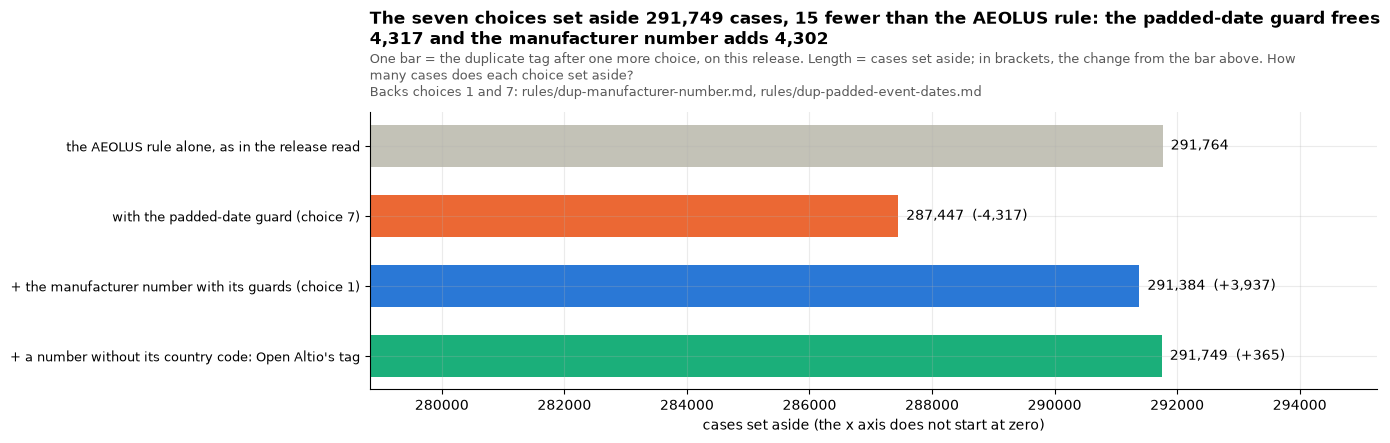

,this release
cases,"20,588,529"
never compared by the AEOLUS rule (a field empty),"12,684,711"
set aside in the release,"291,749"
set aside by Open Altio's tag,"291,749"
of which grouped by the AEOLUS rule,"287,453"
of which grouped by the number,"4,549"
"number groups (trimmed, in capitals)","4,320"
skipped by the sex guard,79
skipped by the age guard,115
groups joined by a number without its code,372


,code,cases,name
0,any serious code,2405,
1,OT,1460,other serious
2,HO,728,hospitalised
3,DE,298,death
4,LT,103,life-threatening
5,RI,73,needed intervention
6,DS,71,disability
7,CA,13,congenital anomaly


In [32]:
STEPS = {
    "the AEOLUS rule alone, as in the release read": "lg_aeolus_T",
    "with the padded-date guard (choice 7)": "lg_padded_T",
    "+ the manufacturer number with its guards (choice 1)": "lg_number_T",
    "+ a number without its country code: Open Altio's tag": "lg_tag_T",
}
cases_all = con.execute("SELECT count(*) FROM w.case_rules_T").fetchone()[0]
released_aside = con.execute(
    "SELECT count(*) FILTER (WHERE NOT released_kept_T) FROM w.case_rules_T"
).fetchone()[0]
funnel = pd.DataFrame(
    [
        q(
            f"SELECT count(DISTINCT comp_T) AS groups_, count(*) AS in_groups, count(*) - count(DISTINCT comp_T) AS set_aside FROM w.{t}"
        ).iloc[0]
        for t in STEPS.values()
    ],
    index=pd.Index(list(STEPS), name="step"),
)
funnel["change"] = funnel.set_aside.diff()
assert funnel.set_aside.iloc[-1] == released_aside, (
    funnel.set_aside.iloc[-1],
    released_aside,
)  # the last step rebuilds the release's own flags, which hold every rule
guards = q("""SELECT count(DISTINCT plain_key) FILTER (WHERE n_plain > 1) AS number_groups,
                     count(DISTINCT plain_key) FILTER (WHERE plain_sex_clash) AS sex_guard_groups,
                     count(DISTINCT plain_key) FILTER (WHERE NOT plain_sex_clash AND plain_age_clash) AS age_guard_groups,
                     count(*) FILTER (WHERE plain_sex_clash) - count(DISTINCT plain_key) FILTER (WHERE plain_sex_clash) AS sex_guard_kept_visible,
                     count(*) FILTER (WHERE NOT plain_sex_clash AND plain_age_clash) - count(DISTINCT plain_key) FILTER (WHERE NOT plain_sex_clash AND plain_age_clash) AS age_guard_kept_visible,
                     count(DISTINCT code_key) FILTER (WHERE code_ok IS NOT NULL AND any_via_code) AS code_groups,
                     count(*) FILTER (WHERE code_ok IS NOT NULL AND via_code) AS cases_without_code_matched,
                     count(*) FILTER (WHERE bare_two_codes) AS bare_with_two_codes,
                     count(DISTINCT g_cur_T) FILTER (WHERE n_cur_T > 1 AND padded_any) AS padded_any_groups,
                     count(DISTINCT g_cur_T) FILTER (WHERE n_cur_T > 1 AND padded) AS padded_groups,
                     count(*) FILTER (WHERE n_cur_T > 1 AND padded) AS padded_cases
              FROM w.tag_T""").iloc[0]
links = q("""SELECT count(*) AS groups_, count(*) FILTER (WHERE both_rules) AS linked_across_rules, sum(aside_cur) AS aside_cur, sum(aside_num) AS aside_num FROM (
               SELECT l.comp_T, count(DISTINCT coalesce(x.cur_ok, l.case_key_T)) > 1 AND count(DISTINCT coalesce(x.code_ok, l.case_key_T)) > 1 AS both_rules,
                      count(*) FILTER (WHERE NOT l.shown_T AND x.cur_ok IS NOT NULL) AS aside_cur, count(*) FILTER (WHERE NOT l.shown_T AND x.code_ok IS NOT NULL) AS aside_num
               FROM w.lg_tag_T l JOIN w.tag_T x USING (era_T, case_key_T) GROUP BY 1)""").iloc[0]
shown = q("""SELECT count(*) FILTER (WHERE r.released_kept_T AND l.shown_T = false) AS shown_before_now_set_aside,
                    count(*) FILTER (WHERE NOT r.released_kept_T AND coalesce(l.shown_T, true)) AS set_aside_before_now_shown,
                    count(*) FILTER (WHERE l.shown_T AND year(l.first_fda_dt_T) <> year(l.group_first_dt_T)) AS shown_received_in_a_later_year
             FROM w.case_rules_T r LEFT JOIN w.lg_tag_T l USING (era_T, case_key_T)""").iloc[0]
serious = q(f"""WITH e AS (SELECT era_T, case_key_T, primaryid, quarter_T, n_real_drugs_T = 0 AS no_drug, n_real_pts_T = 0 AS no_reaction
                           FROM w.case_rules_T WHERE empty_T),
                o AS (SELECT DISTINCT e.era_T, e.case_key_T, o.outc_cod FROM e JOIN outc_latest_T o USING (era_T, primaryid, quarter_T)
                      WHERE upper(trim(o.outc_cod)) IN ({sql_list(SERIOUS)}))
                SELECT coalesce(outc_cod, 'any serious code') AS code, count(DISTINCT (era_T, case_key_T)) AS cases
                FROM o GROUP BY ROLLUP (outc_cod) ORDER BY 2 DESC""")
flagged = int(serious.loc[serious.code == "any serious code", "cases"].iloc[0])
fig, ax = plt.subplots(figsize=(13, 3.6))
yy = np.arange(len(funnel))[::-1]
ax.barh(yy, funnel.set_aside, color=[GREY, ORANGE, BLUE, GREEN], height=0.6)
for y_, (_, r) in zip(yy, funnel.iterrows(), strict=True):
    ax.text(
        r.set_aside,
        y_,
        f"  {int(r.set_aside):,}" + ("" if pd.isna(r.change) else f"  ({int(r.change):+,})"),
        va="center",
        fontsize=10,
    )
ax.set_yticks(yy)
ax.set_yticklabels(funnel.index, fontsize=9.5)
ax.set_xlim(funnel.set_aside.min() * 0.97, funnel.set_aside.max() * 1.012)
ax.set_xlabel("cases set aside (the x axis does not start at zero)")
d_total = int(funnel.set_aside.iloc[-1] - funnel.set_aside.iloc[0])
title(
    header(fig),
    f"The seven choices set aside {int(funnel.set_aside.iloc[-1]):,} cases, {abs(d_total):,} {'fewer' if d_total < 0 else 'more'} than the AEOLUS rule: "
    f"the padded-date guard frees {int(-funnel.change.iloc[1]):,} and the manufacturer number adds {int(funnel.change.iloc[2] + funnel.change.iloc[3]):,}",
    "One bar = the duplicate tag after one more choice, on this release. Length = cases set aside; in brackets, the change from the bar above.",
    "How many cases does each choice set aside?",
    rule_line((1, 7)),
)
plt.show()
summary = pd.Series(
    {
        "cases": cases_all,
        "never compared by the AEOLUS rule (a field empty)": int(rep.loc["all", "never_compared"]),
        "set aside in the release": released_aside,
        "set aside by Open Altio's tag": int(funnel.set_aside.iloc[-1]),
        "of which grouped by the AEOLUS rule": int(links.aside_cur),
        "of which grouped by the number": int(links.aside_num),
        "number groups (trimmed, in capitals)": int(guards.number_groups),
        "skipped by the sex guard": int(guards.sex_guard_groups),
        "skipped by the age guard": int(guards.age_guard_groups),
        "groups joined by a number without its code": int(guards.code_groups),
        "numbers without a code the sender wrote with two codes (never matched)": int(
            guards.bare_with_two_codes
        ),
        "large padded-date groups": int(guards.padded_any_groups),
        "of which from one company, left whole": int(guards.padded_groups),
        "cases in them": int(guards.padded_cases),
        "linked groups": int(links.groups_),
        "groups linked across the two rules": int(links.linked_across_rules),
        "cases shown by the release read, now set aside": int(shown.shown_before_now_set_aside),
        "cases set aside by the release read, now shown": int(shown.set_aside_before_now_shown),
        "shown copies received in a later year than their group": int(
            shown.shown_received_in_a_later_year
        ),
        "reports with no usable drug or reaction": int(tot.cases),
        "of which with a serious outcome (flagged)": flagged,
    }
)
display(summary.map("{:,}".format).to_frame("this release"))
serious.assign(name=serious.code.map(lambda c: SERIOUS.get(c, "")))

**1. Open Altio's tag: the AEOLUS rule or the manufacturer number.** A number group (same `mfr_num` and `mfr_sndr`, trimmed and in capitals) is skipped when its cases include both M and F, or ages more than 2 years apart. A number without its country code joins the one coded form its sender uses; two codes never match, and a number its sender wrote with two codes matches neither. Groups of the two rules that share a case are one group.
- This release: 4,320 number groups; the sex guard skips 79 and the age guard 115 more. The guarded number adds 3,937 set aside, the missing country code 365 more in 372 groups. No number without a code was written by its sender with two codes. 25 groups are linked across the two rules. Open Altio's tag sets aside 291,749 cases in 189,488 groups: 287,453 grouped by the AEOLUS rule, 4,549 by the number (253 by both).
- Code: `rules/dup-manufacturer-number.md`; `DUP_NUMBERS_T` and `DUP_MEMBERS_T` in `src/open_altio/faers/derive.py`, and `link_dup_groups`, a label propagation in SQL. Run over this release's tables, the release code sets aside the same 291,749 cases in the same 189,488 groups as the notebook's own union-find.

**2. Empty fields are never compared.** No change to matching. The AEOLUS rule cannot check 12,684,711 cases (61.6%). The release says so: `funnel.json` carries `duplicates.not_compared_by_aeolus`, and the methods page states it under "What we do not do". Matching on any version of a case, then a probability score, are for later releases.

**3. The latest received copy is shown, and the group is dated by its earliest receipt.** One order for every rule. The groups and the number set aside do not depend on it; only the copy shown changes. Against this release's own flags, which show the latest received copy, no case changes: 0 shown cases are set aside and 0 set aside cases are shown. 38,255 shown copies were first received in a later year than their group; the group date keeps those events in their original year.
- Code: `rules/dup-shown-copy.md`; `dup_kept_T` follows the latest received, and `group_first_dt_T` is on `case_latest_T` and `explorer_case_T`. The explorer's received-date filters and sorting, its list's received column and the filtered export's order use it. The insight cards count every case, not the shown ones, so they keep each case's own year.

**4. A reason line per rule, naming the shown copy.** The release carries `dup_rule_T` (the rules that grouped each case), `dup_shown_case_T` (the shown copy) and, on the shown copy, `dup_other_cases_T`. The sentences are values of `rules/dup-shown-copy.md`, and `open_altio.faers.duplicates.reason_lines` writes them.

**5. Reaction terms in capitals.** Already in the release, from notebook 02.

**6. Reports with no usable drug or reaction stay visible.** 28,004 reports, 27,620 of them only "no adverse event". 2,405 carry a serious outcome code and get their own flag, `serious_no_drug_or_reaction_T`: other serious 1,460, hospitalised 728, death 298, life-threatening 103, needed intervention 73, disability 71, congenital anomaly 13 (a report can carry several). Rule `rules/no-drug-or-reaction.md`.

**7. Padded dates in large groups from one company.** In the AEOLUS rule's groups of 8 or more whose shared event date is 1 January, or a month or year only, and whose cases were all sent by one company (the same sender, trimmed and in capitals; a blank sender counts as another), the date does not count, so nothing is set aside. Of the 440 such large groups, 372 come from one company: they hold 4,689 cases and the guard leaves 4,317 more visible. They are mostly one company's reports of one product over a few years, such as Zantac (2020 to 2022) and Mirena (2013 to 2017). The other 68 groups (621 cases) come from two or more companies, often one published case that every maker reported, such as eight makers reporting the same 53-year-old man with the same drugs and reactions: they are real duplicates and stay set aside. Guarded cases can still group by the number. Rule `rules/dup-padded-event-dates.md`; `dup_padded_date_T` on `case_dup_T`. Event-date precision becomes a field of a later study of duplicate probability.

## Methods-page cards from this notebook

The five cards of this notebook, computed by the same functions the release build calls (`src/open_altio/faers/insights/cards/duplicates.py`) on the release this notebook reads. Three sit behind the duplicates step: one event reaching FAERS as several cases (and why the latest copy is shown), one company's case under two FDA case numbers, and padded event dates in one-company groups. Two are documented: cases the duplicate rules cannot check, and "no adverse event" reports with a serious outcome. On the release this notebook reads, built without the seven choices, the cards count none of what the choices set aside; a release built with Altio's standard carries them in `methods.json`. Each is written to `notebooks/out/cards/` (or `$OPEN_ALTIO_INSIGHTS_OUT`) for checking; the release carries them in `methods.json`.

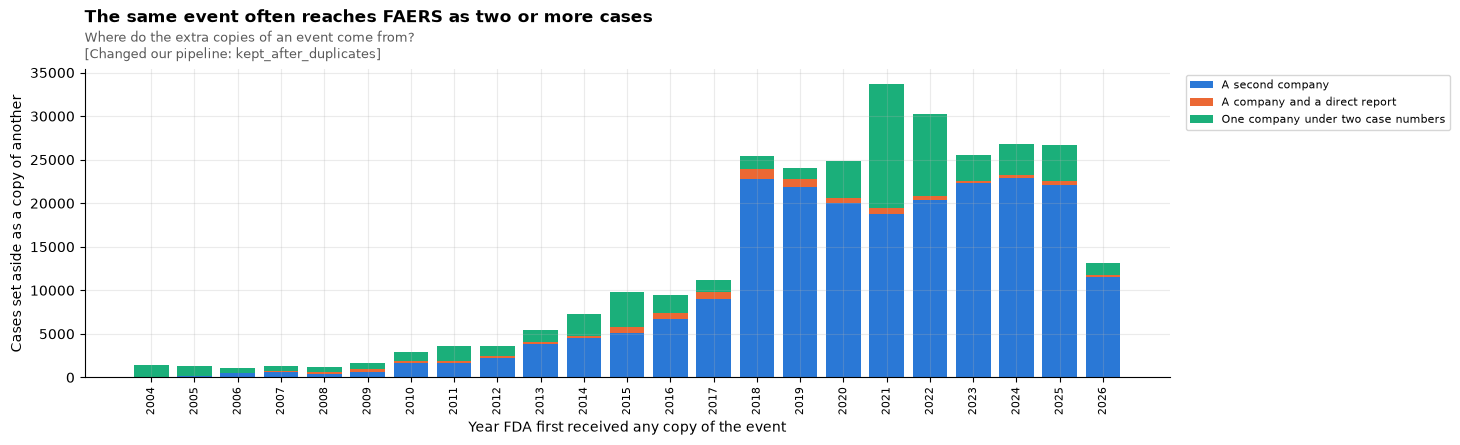

291,749 cases (1.4% of all cases) repeat an event already in FAERS under another case number: 219,741 sent by a second company, 8,831 where a company and a direct report both sent it, and 63,177 by one company under two numbers. We flag them and show one copy per event, the latest received, dated when FDA first received any copy. Where one company sent an event twice and the copies list different reactions, the later copy lists more in 69% of pairs and the earlier in 31%.


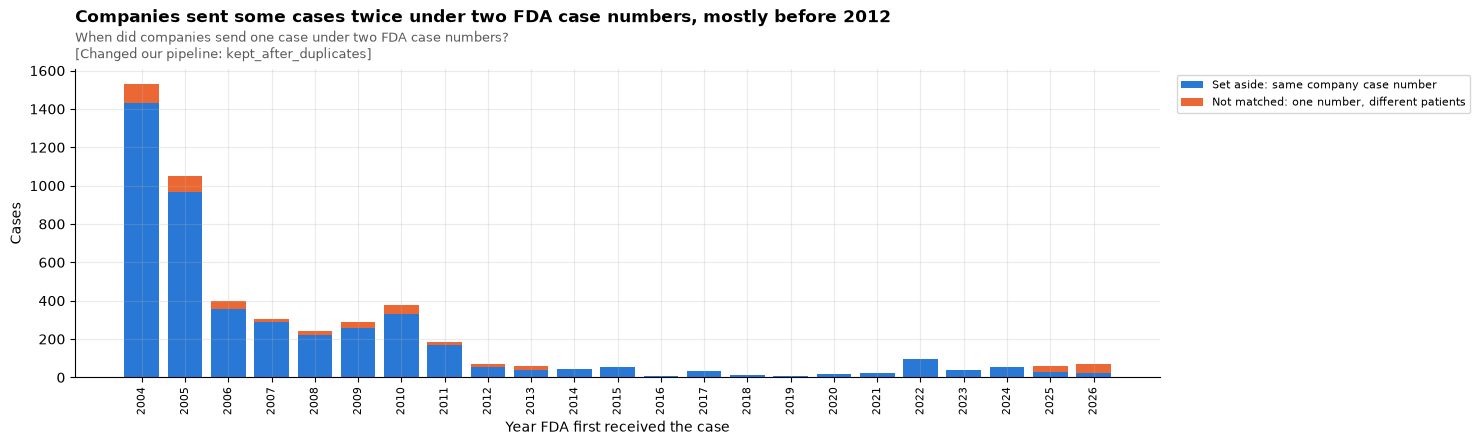

4,549 cases share their company case number and sender with another FDA case, 88% of them received before 2012, often a follow-up filed as a new case with reactions added or a field left blank, which an exact match on every field misses. We set them aside on the number, except 464 cases whose copies disagree on sex or on age by more than 2 years, where one number was used for different patients.


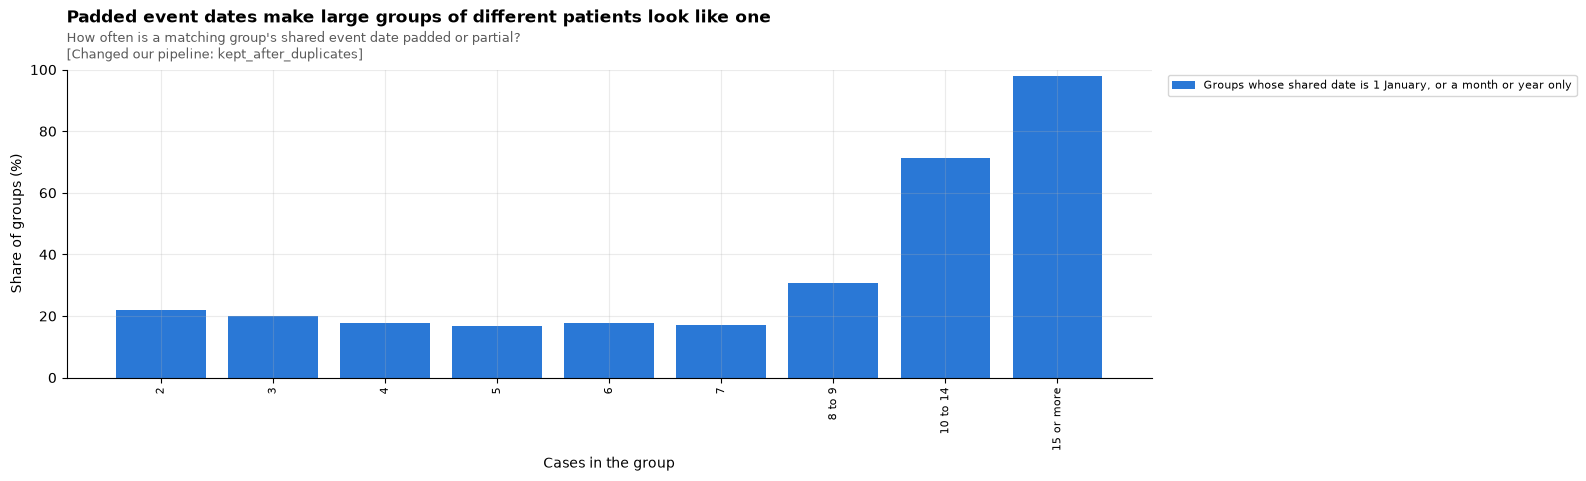

When only the year is known, FAERS often shows 1 January: 11% of full event dates fall on it, against under 1% if dates were spread evenly, and the larger a group of exactly matching cases, the more often its shared date is 1 January or a month or year alone, mostly where one company filed dozens of separate cases with the same profile. In groups of 8 or more that one company sent, such a date no longer counts as a match, so 4,317 cases in 372 groups are no longer set aside; copies of one event from several companies stay set aside.


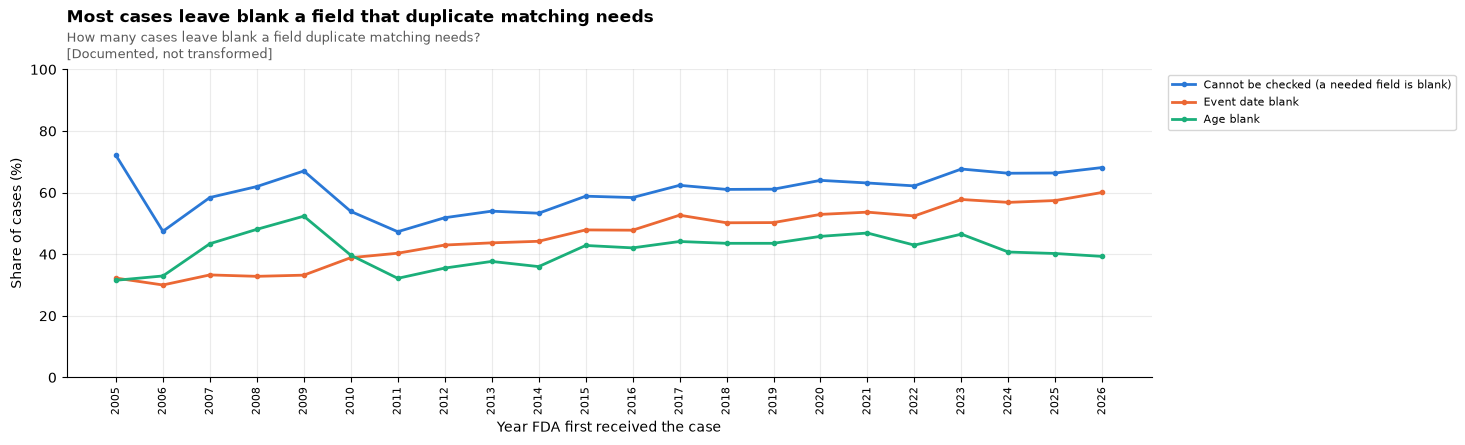

12,684,725 cases (62%) leave the event date, age, sex or country blank, so no exact rule can tell whether they repeat another case, up from 47% of cases received in 2011 to 68% in 2026, led by the event date. We do not fill blanks, so the duplicate flag finds only the copies it can check.


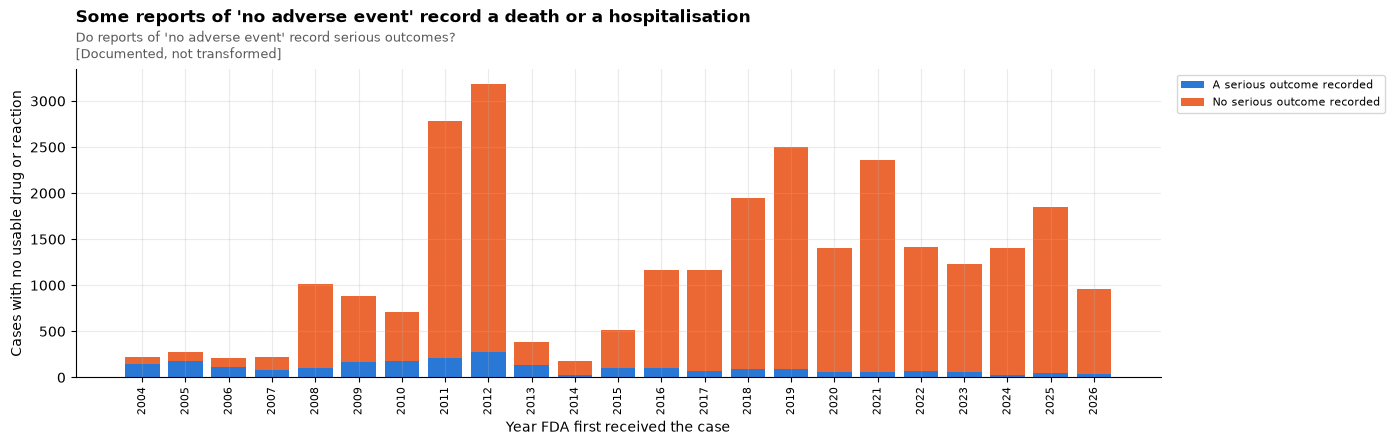

28,004 cases name no usable drug or reaction, 99% of them saying only 'no adverse event', yet 2,405 record a serious outcome, including 298 deaths and 728 hospitalisations. We keep all of them in the analysis set and flag the ones with a serious outcome.
notebooks/out/cards/04_duplicates.json


In [33]:
from open_altio.faers.insights.cards import compute_cards
from open_altio.faers.insights.cards.notebook import plot_card, write_cards

cards = compute_cards(
    con,
    [
        "same_event_several_cases",
        "one_case_two_numbers",
        "padded_dates_join_different_patients",
        "duplicate_check_needs_fields",
        "no_adverse_event_serious_outcome",
    ],
)
for card in cards:
    plot_card(card)
print(write_cards(cards, "04_duplicates"))